# Estudo de Caso 2: Tempo de Tramitação no 4º JEC de Natal/RN — conciliação obrigatória presencial, remota e rito atual

**Autor:** rafaelcc · **Disciplina:** Ciência de Dados e Estatística aplicadas ao Direito e Políticas Públicas (CDEaDPP) — 2026.2 · **Professor:** Cleuler Barbosa das Neves
**Notebook:** `rafaelcc_ed2.ipynb` (gerado por `src/build_rafaelcc_ed2.py`; não editar à mão)

## Introdução

**O experimento.** O juiz titular do 4º Juizado Especial Cível (JEC) de Natal/RN, Paulo Giovani Militão de Alencar, conduziu, como pesquisa de mestrado profissional (PPGDP/UFG, orientação do Prof. Cleuler), um experimento na própria unidade. Cada ação de conhecimento distribuída ao 4º JEC entre **01/01/2026 e 03/08/2026** foi submetida a um sorteio que definia o rito procedimental:

| Grupo (código) | Rótulo neste notebook | Rótulo na planilha | Descrição |
|---|---|---|---|
| `Controle` | Controle (rito atual, AC opcional) | Rito Atual Ac Opcional | Fluxo vigente em Natal desde a pandemia: citação para contestar, sem audiência de conciliação (AC) inaugural, salvo pedido conjunto das partes |
| `Presencial` | AC presencial obrigatória | Ac Obrigatória Presencial | AC inaugural obrigatória (art. 21 da Lei 9.099/1995), no fórum, conduzida por servidora do CEJUSC |
| `Remota` | AC remota obrigatória | Ac Remota | AC inaugural obrigatória por videoconferência (Teams), conduzida por servidora do gabinete |

Nas audiências, a técnica de conciliação também era sorteada (seis técnicas). A planilha de acompanhamento, alimentada diariamente pela unidade, registra **943 processos** sorteados (944 linhas) com o rito, a ocorrência de acordo na audiência ou fora dela, a técnica, o tipo e a data da sentença. A versão analisada foi **atualizada em 07/10/2026**: os processos ainda sem sentença nessa data estão em tramitação e têm, portanto, tempo **censurado à direita**.

**Variável-alvo.** O **tempo de tramitação**, em dias corridos, da distribuição ao 4º JEC até a sentença (de mérito, sem mérito ou homologatória de acordo).

**Perguntas de pesquisa.**

1. **Curadoria.** Os dados brutos são confiáveis? Que anomalias existem e como tratá-las sem inventar informação?
2. **Efeito sobre o tempo.** A audiência de conciliação obrigatória, presencial ou remota, altera o tempo até a sentença em relação ao rito atual?
3. **Efeito sobre o acordo.** A audiência obrigatória aumenta a proporção de acordos? A modalidade (presencial × remota) importa?
4. **Desenho.** O sorteio produziu grupos comparáveis? Que limitações (censura, redistribuições, híbridas, unidade única) afetam a validade interna e a externa?
5. **Questões do professor.** Respostas às questões 2.2 a 2.12 do roteiro.

**Pipeline de ciência de dados.**

| Parte | Seções | Conteúdo |
|---|---|---|
| I. Curadoria | 1 | Ambiente; formação do dataset bruto; fórmulas e data de corte; tipos e tipologia das variáveis; ausências, duplicidades, número CNJ, grafias, recodificações e desvios de protocolo; dataset *tidy* com tempo e evento; verificações; registro de tratamentos; dicionário e exportação |
| II. Exploratória | 2 | Análise univariada e bivariada com o tempo como alvo; normalidade e ajuste de distribuições; modelo binomial para as proporções |
| III. Testes de hipóteses | 3 | Testes adequados a cada pergunta (qui-quadrado, Fisher, Kruskal-Wallis, Mann-Whitney, Dunn, sequências), com tamanho de efeito e correção de multiplicidade |
| IV. Análise de sobrevivência | 4 | Kaplan-Meier, log-rank, Cox, modelos AFT, riscos competitivos (Aalen-Johansen, Fine-Gray) e tempo médio restrito (RMST) |
| V. Multivariada e regressão | 5 | Modelos com covariáveis (mês de distribuição, origem do processo), regressão logística para o acordo e diagnósticos |
| VI. Questões do professor | 6 | Respostas fundamentadas às questões 2.2 a 2.12 |
| VII. Síntese | 7 | Conclusões, limitações e sugestões para a replicação |

### O notebook do professor

O notebook inicial `estcaso_4jec_natal_rn.ipynb` foi revisado célula a célula (30 problemas catalogados, E1 a E30). Os principais, corrigidos aqui:

- **E1** — `from lifelines import KaplanMeierFitter, logrank_test` falha (a função fica em `lifelines.statistics`), e o `except ImportError` desliga silenciosamente o Kaplan-Meier: a única análise adequada a dados censurados nunca é executada;
- **E7/E14** — os tempos dos processos em tramitação (censurados) são tratados como tempos completos, e a "janela de 218 dias" não corresponde aos dados; a data de referência real é 07/10/2026, fixada aqui;
- **E3** — duplicidades detectadas e não tratadas (há processos redistribuídos que voltaram e foram **sorteados de novo**, inclusive para outro grupo);
- **E4/E5** — o marcador `**` ("não se aplica") e as ausências estruturais são tratados como categorias ou como "Não";
- **E10** — a "Decisão" (redistribuição por prevenção) é contada como sentença;
- **E6/E16** — quatro colunas de duração são a mesma variável, e a matriz de correlação entre elas é tautológica (r = 1);
- **E17–E27** — Kruskal-Wallis, OLS e ajuste de distribuições aplicados a tempos censurados; testes tautológicos (Encerrado × Ativo) e sem tamanho de efeito nem correção de multiplicidade.

Em cada seção, quando a abordagem difere da do notebook do professor, o erro corrigido é indicado pelo código (E*n*).

---

# PARTE I — CURADORIA DOS DADOS

A Parte I transforma a planilha da pesquisadora num dataset analítico (*tidy*: uma linha por processo, uma coluna por variável, um tipo adequado por coluna). O roteiro segue a auditoria completa dos dados brutos, e cada decisão é registrada num **log de tratamentos** exportado ao final. Duas regras valem em toda a Parte I:

1. **O arquivo-fonte nunca é alterado**, e `dados_brutos` preserva exatamente a leitura; todas as transformações ocorrem numa cópia de trabalho.
2. **Nenhuma data ou duração é imputada.** O que falta continua faltando, e os processos sem sentença são tratados como **censurados** na data de corte.

## 1.1 Preparação do ambiente

A primeira célula concentra as importações, os caminhos, as constantes do estudo e a identidade visual que as demais partes do notebook reutilizam:

- **`DATA_CORTE = 07/10/2026`**: data de referência da censura (seção 1.3);
- **`CORES_GRUPO`**: uma cor fixa por grupo, da paleta de Okabe-Ito (segura para daltonismo). A mesma cor representa o mesmo grupo em todos os gráficos;
- **avisos**: só são silenciados os avisos conhecidos e inofensivos (extensões do Excel que o `openpyxl` não lê e avisos de depreciação). O notebook do professor usava `warnings.filterwarnings('ignore')`, que esconde qualquer problema, inclusive o que desligou o Kaplan-Meier (E1).

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import importlib
import platform
import re
import sys
import unicodedata
import warnings

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
import lifelines
from lifelines import KaplanMeierFitter, CoxPHFitter, AalenJohansenFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test, pairwise_logrank_test
import sklearn
import scikit_posthocs as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl
from IPython.display import display, Markdown

# Avisos conhecidos e inofensivos (não se usa filterwarnings('ignore') global)
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')
warnings.filterwarnings('ignore', category=FutureWarning)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 70)

# ---------------------------------------------------------------- caminhos
ARQUIVO_BRUTO = 'ControleDosProcessos_Mestrado_Atualizacao_07.10.2026.xlsx'
_candidatos = [Path.cwd(), Path.cwd() / 'EstudodeCaso2', Path.cwd().parent, Path.cwd().parent / 'EstudodeCaso2']
RAIZ = next((p.resolve() for p in _candidatos if (p / ARQUIVO_BRUTO).exists()), None)
if RAIZ is None:
    raise FileNotFoundError(f'{ARQUIVO_BRUTO} não encontrado. Inicie o kernel na raiz do projeto ou em EstudodeCaso2.')
BRUTO = RAIZ / ARQUIVO_BRUTO
PROC = RAIZ / 'dat' / 'processado'
FIG = RAIZ / 'fig'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- constantes do estudo
DATA_INICIO = pd.Timestamp('2026-01-01')        # primeira distribuição
FIM_RECRUTAMENTO = pd.Timestamp('2026-08-03')   # último sorteio
DATA_CORTE = pd.Timestamp('2026-10-07')         # atualização da planilha = censura administrativa
SEMENTE = 2026
RNG = np.random.default_rng(SEMENTE)

ORDEM_GRUPO = ['Controle', 'Presencial', 'Remota']   # referência = Controle
ROTULO_GRUPO = {'Controle': 'Controle (rito atual, AC opcional)',
                'Presencial': 'AC presencial obrigatória',
                'Remota': 'AC remota obrigatória'}
CORES_GRUPO = {'Controle': '#0072B2', 'Presencial': '#E69F00', 'Remota': '#009E73'}   # Okabe-Ito
ORDEM_DESFECHO = ['Homologação', 'Mérito', 'Sem mérito', 'Redistribuição', 'Ativo']
CORES_DESFECHO = {'Homologação': '#009E73', 'Mérito': '#0072B2', 'Sem mérito': '#D55E00',
                  'Redistribuição': '#CC79A7', 'Ativo': '#999999'}
TINTA, TINTA_2, GRADE = '#1a1a1a', '#555555', '#e5e5e5'

plt.rcParams.update({
    'figure.dpi': 100, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': TINTA_2,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.grid': True, 'grid.color': GRADE,
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'font.size': 10, 'legend.frameon': False,
    'axes.prop_cycle': mpl.cycler(color=list(CORES_GRUPO.values())),
})
sns.set_palette(list(CORES_GRUPO.values()))


# ---------------------------------------------------------------- números em pt-BR
def fmt_br(valor, casas=1):
    """Formata número no padrão brasileiro: 1.234,5."""
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return '–'
    return f'{valor:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def pct_br(proporcao, casas=1):
    """Proporção (0–1) como percentual pt-BR: 12,3%."""
    return fmt_br(100 * proporcao, casas) + '%'


def p_br(p):
    """Valor-p em pt-BR, com limite inferior."""
    return '< 0,001' if p < 0.001 else fmt_br(p, 3)


print(f'Python {platform.python_version()} | pasta do estudo: {RAIZ}')
print(f'Data de corte (censura): {DATA_CORTE:%d/%m/%Y}')

Python 3.12.8 | pasta do estudo: C:\Users\MPGO\AulaCleuler\EstudodeCaso2
Data de corte (censura): 07/10/2026


### Versões das bibliotecas e o erro de importação do notebook do professor

A tabela registra as versões usadas (reprodutibilidade; o ambiente é o `uv.lock` do projeto). Em seguida, a célula reproduz o import do notebook do professor. A função `logrank_test` **não** existe no espaço de nomes principal do `lifelines`; ela fica em `lifelines.statistics`. No notebook original, o `ImportError` era capturado por um `except` que fazia `TEM_LIFELINES = False`, e todo o Kaplan-Meier era pulado **mesmo com a biblioteca instalada** (E1).

In [2]:
BIBLIOTECAS = ['pandas', 'numpy', 'scipy', 'statsmodels', 'lifelines', 'sklearn', 'scikit_posthocs',
               'matplotlib', 'seaborn', 'openpyxl', 'nbformat']
versoes = pd.DataFrame(
    [(nome, getattr(importlib.import_module(nome), '__version__', '?')) for nome in BIBLIOTECAS],
    columns=['Biblioteca', 'Versão'])
display(versoes.set_index('Biblioteca').T)

try:
    from lifelines import logrank_test as _teste  # import do notebook do professor
    resultado_import = 'funcionou'
except ImportError as erro:
    resultado_import = f'ImportError: {erro}'
print('from lifelines import logrank_test            ->', resultado_import)
print('from lifelines.statistics import logrank_test ->', logrank_test.__module__, '(correto)')

Biblioteca,pandas,numpy,scipy,statsmodels,lifelines,sklearn,scikit_posthocs,matplotlib,seaborn,openpyxl,nbformat
Versão,3.0.5,2.5.2,1.18.0,0.15.0,0.30.0,1.9.0,0.17.0,3.11.1,0.13.2,3.1.5,5.11.1


from lifelines import logrank_test            -> ImportError: cannot import name 'logrank_test' from 'lifelines' (C:\Users\MPGO\AulaCleuler\.venv\Lib\site-packages\lifelines\__init__.py)
from lifelines.statistics import logrank_test -> lifelines.statistics (correto)


---

## 1.2 Formação do dataset bruto

### 1.2.1 As abas da planilha

O arquivo tem oito abas, mas só uma contém dados por processo. As demais são painéis, tabelas dinâmicas e listas de validação construídas **a partir** da aba `Processos`; servem apenas para conferência (seção 1.13).

In [3]:
livro = openpyxl.load_workbook(BRUTO, data_only=False)   # fórmulas, não valores
PAPEL_ABA = {
    'Processos': 'Dados por processo (tabela Excel TAB_DADOS) — única fonte analítica',
    'Dash1': 'Painel (segmentações/gráficos), sem dados',
    'Dash2': 'Painel (segmentações/gráficos), sem dados',
    'Dash3': 'Painel (segmentações/gráficos), sem dados',
    'Tab_D': 'Tabelas dinâmicas da pesquisadora (médias por grupo, técnica, status)',
    'Tabelas': 'Resumos com fórmulas (acordos, "eficiência" por rito)',
    'Resumo': 'Questionário de perguntas descritivas (valores vazios no cache)',
    'Lista': 'Listas das validações de dados (valores permitidos nas colunas)',
}
abas = pd.DataFrame([{
    'Aba': ws.title,
    'Visibilidade': 'oculta' if ws.sheet_state != 'visible' else 'visível',
    'Intervalo usado': ws.dimensions,
    'Células preenchidas': sum(c.value is not None for linha in ws.iter_rows() for c in linha),
    'Papel': PAPEL_ABA.get(ws.title, ''),
} for ws in livro.worksheets])
display(abas)

ws = livro['Processos']
print('Tabela Excel na aba Processos:', {nome: ref for nome, ref in ws.tables.items()})
print('Colunas ocultas:', [c for c, d in ws.column_dimensions.items() if d.hidden])
print('Linha 1 (acima do cabeçalho):', [ws.cell(1, c).value for c in range(1, 16)])

,Aba,Visibilidade,Intervalo usado,Células preenchidas,Papel
0,Processos,visível,A2:O946,13317,Dados por processo (tabela Excel TAB_DADOS) — única fonte analítica
1,Dash1,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
2,Dash2,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
3,Dash3,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
4,Tab_D,oculta,A1:BG144,351,"Tabelas dinâmicas da pesquisadora (médias por grupo, técnica, status)"
5,Tabelas,visível,A2:AL49,623,"Resumos com fórmulas (acordos, ""eficiência"" por rito)"
6,Resumo,visível,A2:C25,25,Questionário de perguntas descritivas (valores vazios no cache)
7,Lista,oculta,A1:I8,26,Listas das validações de dados (valores permitidos nas colunas)


Tabela Excel na aba Processos: {'TAB_DADOS': 'A2:O946'}
Colunas ocultas: ['J', 'M', 'P']
Linha 1 (acima do cabeçalho): [None, None, None, None, None, None, None, None, None, None, None, None, None, None, None]


### 1.2.2 Leitura da aba `Processos`

A linha 1 está vazia e o cabeçalho está na linha 2 (`header=1`). O índice de `dados_brutos` passa a ser o **número da linha no Excel** (`linha_excel`), o que permite rastrear cada tratamento até a célula de origem. `dados_brutos` não é modificado em nenhum momento.

In [4]:
dados_brutos = pd.read_excel(BRUTO, sheet_name='Processos', header=1, engine='openpyxl')
dados_brutos.index = pd.RangeIndex(3, 3 + len(dados_brutos), name='linha_excel')

print(f'{dados_brutos.shape[0]} linhas × {dados_brutos.shape[1]} colunas (linhas 3 a {dados_brutos.index[-1]} do Excel)')
print('Nomes das colunas (repr, para ver espaços):')
print([c for c in dados_brutos.columns])
print(f'Linhas inteiramente vazias: {dados_brutos.isna().all(axis=1).sum()} | '
      f'números de processo distintos: {dados_brutos["NÚMERO DO PROCESSO"].nunique()}')
display(dados_brutos.head(5))

944 linhas × 15 colunas (linhas 3 a 946 do Excel)
Nomes das colunas (repr, para ver espaços):
['NÚMERO DO PROCESSO', 'DT. DISTRIBUIÇÃO', 'SORTEIO', 'HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA', 'DT. SENTENÇA', 'DURAÇÃO-SENT2', 'DURAÇÃO-TECN', 'DURAÇÃO-SORT', 'DURAÇÃO-PROC', ' DURAÇÃO DO PROCESSO', 'STATUS']
Linhas inteiramente vazias: 0 | números de processo distintos: 938


,NÚMERO DO PROCESSO,DT. DISTRIBUIÇÃO,SORTEIO,HÍBRIDA,TEVE ACORDO NA AC?,TÉCNICA,TEVE ACORDO FORA DA AC?,SENTENÇA,DT. SENTENÇA,DURAÇÃO-SENT2,DURAÇÃO-TECN,DURAÇÃO-SORT,DURAÇÃO-PROC,DURAÇÃO DO PROCESSO,STATUS
linha_excel,,,,,,,,,,,,,,,
3,0800001-35.2026.8.20.5004,2026-01-01,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do feito sem julgamento de mérito,2026-01-07,6.0,NaN,6.0,6.0,6 dia(s),Encerrado
4,0800024-78.2026.8.20.5004,2026-01-06,Rito Atual Ac Opcional,Não,Não,**,NaN,NaN,NaT,274.0,NaN,274.0,274.0,274 dia(s),Ativo
5,0808292-43.2025.8.20.5300,2026-01-06,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do Feito sem Julgamento de Mérito,2026-01-09,3.0,NaN,3.0,3.0,3 dia(s),Encerrado
6,0800038-62.2026.8.20.5004,2026-01-07,Ac Obrigatória Presencial,Não,Sim,Desconstrução da Verdade,Não,Extinção do Feito com Homologação do Acordo,2026-02-22,46.0,46.0,46.0,46.0,46 dia(s),Encerrado
7,0800035-10.2026.8.20.5004,2026-01-07,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do Feito com Julgamento de Mérito,2026-02-27,51.0,NaN,51.0,51.0,51 dia(s),Encerrado


**Leitura.**

- **Uma única aba tem dados.** A aba `Processos` (tabela Excel `TAB_DADOS`, intervalo A2:O946) é a fonte de tudo o que vem depois. As abas `Dash1` a `Dash3` estão vazias de dados (só segmentações e gráficos); `Tab_D` e `Lista` estão **ocultas** e contêm as tabelas dinâmicas e as listas de validação; `Tabelas` e `Resumo` são resumos calculados.
- **944 linhas, não 943.** A aba tem 944 linhas de dados (linhas 3 a 946 do Excel), com **938 números de processo distintos**: há números repetidos (seção 1.9). O enunciado fala em 943 processos porque uma linha (920) não tem as fórmulas de duração e de status (seção 1.3).
- **15 colunas, não 11.** Nove são digitadas pela unidade (A a I); seis são calculadas por fórmula (J a O), três delas ocultas (J, M e a coluna vazia P). O nome de uma coluna começa com espaço (`' DURAÇÃO DO PROCESSO'`), detalhe que quebra qualquer código que a procure pelo nome "limpo".

---

## 1.3 Colunas digitadas × colunas calculadas: a data de corte

As colunas J a O da planilha **não são dados**: são fórmulas. Ler as fórmulas (e não apenas os valores) é essencial, porque a duração dos processos sem sentença é calculada com `TODAY()`, uma função **volátil**: cada vez que o arquivo é aberto, o tempo dos processos ativos aumenta, sem que nenhuma informação nova tenha sido coletada. A célula mostra a fórmula de cada coluna calculada e conta quantas linhas têm fórmula.

In [5]:
COLUNAS_CALCULADAS = {'J': 'DURAÇÃO-SENT2', 'K': 'DURAÇÃO-TECN', 'L': 'DURAÇÃO-SORT', 'M': 'DURAÇÃO-PROC',
                      'N': 'DURAÇÃO DO PROCESSO', 'O': 'STATUS'}
ultima = 2 + len(dados_brutos)
formulas = []
for letra, nome in COLUNAS_CALCULADAS.items():
    valores = [ws[f'{letra}{r}'].value for r in range(3, ultima + 1)]
    com_formula = [isinstance(v, str) and v.startswith('=') for v in valores]
    formulas.append({'Coluna': letra, 'Nome': nome,
                     'Linhas com fórmula': sum(com_formula),
                     'Usa TODAY()': 'TODAY()' in str(valores[0]),
                     'Oculta': ws.column_dimensions[letra].hidden,
                     'Fórmula (linha 3)': valores[0]})
with pd.option_context('display.max_colwidth', 140):
    display(pd.DataFrame(formulas))

sem_formula = [r for r in range(3, ultima + 1) if not str(ws[f'M{r}'].value or '').startswith('=')]
print('Linhas sem fórmula na coluna M:', sem_formula)
print('Conteúdo da linha', sem_formula[0], ':', [ws[f'{c}{sem_formula[0]}'].value for c in 'ABCDEFGHI'])

,Coluna,Nome,Linhas com fórmula,Usa TODAY(),Oculta,Fórmula (linha 3)
0,J,DURAÇÃO-SENT2,943,True,True,"=IF(TAB_DADOS[[#This Row],[SENTENÇA]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
1,K,DURAÇÃO-TECN,943,True,False,"=IF(TAB_DADOS[[#This Row],[TÉCNICA]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
2,L,DURAÇÃO-SORT,943,True,False,"=IF(TAB_DADOS[[#This Row],[SORTEIO]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
3,M,DURAÇÃO-PROC,943,True,True,"=ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3))))"
4,N,DURAÇÃO DO PROCESSO,943,False,False,"=IF(TAB_DADOS[[#This Row],[DURAÇÃO-PROC]]="""","""",TAB_DADOS[[#This Row],[DURAÇÃO-PROC]]&"" dia(s)"")"
5,O,STATUS,943,False,False,"=IF(AND(B3="""",I3=""""),"""",IF(AND(NOT(ISBLANK(B3)),NOT(ISBLANK(I3))),""Encerrado"",""Ativo""))"


Linhas sem fórmula na coluna M: [920]
Conteúdo da linha 920 : ['0813782-27.2026.8.20.5004', datetime.datetime(2026, 7, 29, 0, 0), 'Ac Obrigatória Presencial', None, None, None, None, None, None]


Os **valores em cache** (o que o Excel calculou na última gravação e o que o `pandas` lê) revelam a data em que `TODAY()` foi avaliado: para cada processo ativo, `DT. DISTRIBUIÇÃO + DURAÇÃO-PROC` é essa data. Se ela for única, é a data de corte de fato usada pela pesquisadora.

In [6]:
ativos_bruto = dados_brutos['STATUS'].eq('Ativo')
data_referencia = (dados_brutos.loc[ativos_bruto, 'DT. DISTRIBUIÇÃO']
                   + pd.to_timedelta(dados_brutos.loc[ativos_bruto, 'DURAÇÃO-PROC'], unit='D'))
display(data_referencia.dt.date.value_counts().rename('Processos ativos').to_frame())
assert data_referencia.nunique() == 1 and data_referencia.iloc[0] == DATA_CORTE

props = livro.properties
print(f'Última gravação do arquivo: {props.modified} (por {props.lastModifiedBy}); criado em {props.created:%d/%m/%Y}')
print(f'Sentença mais recente: {dados_brutos["DT. SENTENÇA"].max():%d/%m/%Y} | '
      f'distribuição mais recente: {dados_brutos["DT. DISTRIBUIÇÃO"].max():%d/%m/%Y}')
assert dados_brutos['DT. SENTENÇA'].max() <= DATA_CORTE and dados_brutos['DT. DISTRIBUIÇÃO'].max() <= DATA_CORTE

# As quatro durações são a mesma variável (E6): comparação célula a célula onde não nulas
DURACOES = ['DURAÇÃO-SENT2', 'DURAÇÃO-TECN', 'DURAÇÃO-SORT']
iguais = pd.DataFrame([{
    'Coluna': c,
    'Não nulas': int(dados_brutos[c].notna().sum()),
    'Iguais a DURAÇÃO-PROC': int((dados_brutos[c] == dados_brutos['DURAÇÃO-PROC']).sum()),
} for c in DURACOES])
texto_igual = (dados_brutos[' DURAÇÃO DO PROCESSO'].str.extract(r'(\d+)')[0].astype(float)
               == dados_brutos['DURAÇÃO-PROC']).sum()
display(iguais)
print(f'" DURAÇÃO DO PROCESSO" (texto "N dia(s)") igual a DURAÇÃO-PROC em {texto_igual} linhas')

,Processos ativos
2026-10-07,209


Última gravação do arquivo: 2026-10-07 19:57:29 (por pvccr); criado em 28/01/2026
Sentença mais recente: 06/10/2026 | distribuição mais recente: 03/08/2026


,Coluna,Não nulas,Iguais a DURAÇÃO-PROC
0,DURAÇÃO-SENT2,943,943
1,DURAÇÃO-TECN,428,428
2,DURAÇÃO-SORT,943,943


" DURAÇÃO DO PROCESSO" (texto "N dia(s)") igual a DURAÇÃO-PROC em 943 linhas


**Leitura. A data de corte é 07/10/2026, e precisa ser fixada.**

- **Todas as durações vêm de uma fórmula com `TODAY()`.** As 943 linhas com fórmula calculam `ABS(DT. SENTENÇA − DT. DISTRIBUIÇÃO)` quando há sentença e `ABS(TODAY() − DT. DISTRIBUIÇÃO)` quando não há.
- **Os 209 processos ativos apontam para uma única data: 07/10/2026.** É o dia da última gravação do arquivo (07/10/2026, 19h57) e o que está no nome do arquivo. A sentença mais recente é de 06/10/2026 e a última distribuição, de 03/08/2026, coerentes com essa data.
- **Por que fixar.** Se a planilha for aberta e recalculada hoje (12/11/2026), cada processo ativo "ganha" 36 dias sem nenhuma informação nova. O tempo é, por isso, recalculado em Python a partir das datas, com `DATA_CORTE = 07/10/2026`. O acompanhamento real vai de **65 dias** (distribuídos em 03/08) a **279 dias** (distribuídos em 01/01). A "janela de 218 dias" usada no notebook do professor não corresponde aos dados (E7).
- **As quatro colunas de duração são a mesma variável.** `DURAÇÃO-SENT2` e `DURAÇÃO-SORT` coincidem com `DURAÇÃO-PROC` nas 943 linhas; `DURAÇÃO-TECN` coincide nas 428 em que existe (é a mesma duração, apagada onde a técnica é `**`); o texto `"N dia(s)"` repete o número. Elas só serviam de filtro para as tabelas dinâmicas. Por isso a matriz de correlação do notebook do professor dá r = 1 em todos os pares (E6, E16): correlaciona uma variável consigo mesma.
- **O `ABS()` da fórmula esconderia datas trocadas** (sentença anterior à distribuição). A verificação direta nas datas (seção 1.13) mostra que não há nenhum caso.

---

## 1.4 Estrutura do dado bruto: o que o pandas leu

O `dtype` atribuído pelo `pandas` na leitura não é o tipo estatístico da variável. A coluna *tipos Python presentes* mostra o que realmente existe em cada coluna (por exemplo, `str` e `float` juntos indicam texto com células vazias, `NaN`).

In [7]:
def tipos_presentes(serie):
    """Tipos Python efetivamente presentes nas células não nulas, com contagem."""
    contagem = Counter(type(v).__name__ for v in serie.dropna())
    return ', '.join(f'{t} ({n})' for t, n in contagem.most_common())


perfil_bruto = pd.DataFrame({
    'dtype lido': dados_brutos.dtypes.astype(str),
    'tipos Python presentes': dados_brutos.apply(tipos_presentes),
    'não nulos': dados_brutos.notna().sum(),
    'NaN': dados_brutos.isna().sum(),
    'distintos': dados_brutos.nunique(),
    'exemplo (linha 3)': dados_brutos.iloc[0].astype(str).str.slice(0, 45),
})
display(perfil_bruto)

,dtype lido,tipos Python presentes,não nulos,NaN,distintos,exemplo (linha 3)
NÚMERO DO PROCESSO,str,str (944),944,0,938,0800001-35.2026.8.20.5004
DT. DISTRIBUIÇÃO,datetime64[us],Timestamp (944),944,0,190,2026-01-01 00:00:00
SORTEIO,str,str (944),944,0,3,Rito Atual Ac Opcional
HÍBRIDA,str,str (872),872,72,2,Não
TEVE ACORDO NA AC?,str,str (869),869,75,2,Não
TÉCNICA,str,str (867),867,77,7,**
TEVE ACORDO FORA DA AC?,str,str (736),736,208,3,Não
SENTENÇA,str,str (734),734,210,5,Extinção do feito sem julgamento de mérito
DT. SENTENÇA,datetime64[us],Timestamp (734),734,210,179,2026-01-07 00:00:00
DURAÇÃO-SENT2,float64,float (943),943,1,189,6.0


---

## 1.5 Tipologia estatística das variáveis

A escolha de gráficos, medidas e testes depende do **tipo estatístico** de cada variável, não do `dtype`. A tabela classifica as colunas da planilha e indica o tipo `pandas` adequado a cada uma no dataset *tidy*:

- **nominal** → `category` (sem ordem); **ordinal** → `category` ordenada;
- **binária** → `boolean` (o tipo anulável do pandas, que aceita `<NA>` sem virar `object`);
- **quantitativa discreta** (contagem de dias) → `Int64` (inteiro anulável);
- **data** → `datetime64`; **identificador** → `string` (não é medida: não se calcula média de número de processo).

Note-se que o tempo em dias é discreto por registro, mas é tratado como **contínuo** nos modelos de sobrevivência (com empates). As colunas J a O são descartadas: são derivadas por fórmula, redundantes entre si e dependentes de `TODAY()`.

In [8]:
TIPOLOGIA_BRUTA = pd.DataFrame([
    ('NÚMERO DO PROCESSO', 'Identificador', '—', 'string', 'Mantida como `processo` (limpa e validada)'),
    ('DT. DISTRIBUIÇÃO', 'Data', 'intervalar (tempo de calendário)', 'datetime64', 'Origem do tempo; gera mês, dia da semana, ordem'),
    ('SORTEIO', 'Qualitativa nominal (3 níveis)', 'nominal', 'category', 'Tratamento sorteado → `grupo`'),
    ('HÍBRIDA', 'Qualitativa binária', 'nominal', 'boolean', 'Adesão ao protocolo (pós-sorteio)'),
    ('TEVE ACORDO NA AC?', 'Qualitativa binária', 'nominal', 'boolean', 'Desfecho secundário'),
    ('TÉCNICA', 'Qualitativa nominal (6 níveis + "**")', 'nominal', 'category', '`**` → AC não realizada (`ac_realizada`)'),
    ('TEVE ACORDO FORA DA AC?', 'Qualitativa binária', 'nominal', 'boolean', 'Desfecho secundário'),
    ('SENTENÇA', 'Qualitativa nominal (4 níveis)', 'nominal', 'category', 'Tipo de desfecho; define o evento'),
    ('DT. SENTENÇA', 'Data', 'intervalar (tempo de calendário)', 'datetime64', 'Fim do tempo quando há desfecho'),
    ('DURAÇÃO-SENT2', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: fórmula, cópia de DURAÇÃO-PROC'),
    ('DURAÇÃO-TECN', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: cópia filtrada de DURAÇÃO-PROC'),
    ('DURAÇÃO-SORT', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: fórmula, cópia de DURAÇÃO-PROC'),
    ('DURAÇÃO-PROC', 'Quantitativa discreta (dias)', 'razão', 'Int64', 'Recalculada pelas datas → `tempo` (com censura)'),
    (' DURAÇÃO DO PROCESSO', 'Texto ("N dia(s)")', '—', '—', 'Descartada: DURAÇÃO-PROC em texto'),
    ('STATUS', 'Qualitativa binária', 'nominal', 'boolean', 'Recalculada pela data → `encerrado`'),
], columns=['Coluna bruta', 'Tipo estatístico', 'Escala de medida', 'dtype adequado', 'Decisão'])
TIPOLOGIA_BRUTA.insert(1, 'dtype lido', TIPOLOGIA_BRUTA['Coluna bruta'].map(dados_brutos.dtypes.astype(str)))
display(TIPOLOGIA_BRUTA)

,Coluna bruta,dtype lido,Tipo estatístico,Escala de medida,dtype adequado,Decisão
0,NÚMERO DO PROCESSO,str,Identificador,—,string,Mantida como `processo` (limpa e validada)
1,DT. DISTRIBUIÇÃO,datetime64[us],Data,intervalar (tempo de calendário),datetime64,"Origem do tempo; gera mês, dia da semana, ordem"
2,SORTEIO,str,Qualitativa nominal (3 níveis),nominal,category,Tratamento sorteado → `grupo`
3,HÍBRIDA,str,Qualitativa binária,nominal,boolean,Adesão ao protocolo (pós-sorteio)
4,TEVE ACORDO NA AC?,str,Qualitativa binária,nominal,boolean,Desfecho secundário
5,TÉCNICA,str,"Qualitativa nominal (6 níveis + ""**"")",nominal,category,`**` → AC não realizada (`ac_realizada`)
6,TEVE ACORDO FORA DA AC?,str,Qualitativa binária,nominal,boolean,Desfecho secundário
7,SENTENÇA,str,Qualitativa nominal (4 níveis),nominal,category,Tipo de desfecho; define o evento
8,DT. SENTENÇA,datetime64[us],Data,intervalar (tempo de calendário),datetime64,Fim do tempo quando há desfecho
9,DURAÇÃO-SENT2,float64,Quantitativa discreta (dias),razão,—,"Descartada: fórmula, cópia de DURAÇÃO-PROC"


---

## 1.6 Ausências: `NaN`, `**` e células em branco

A planilha tem **três formas** de "não há valor", que não significam a mesma coisa e não podem ser fundidas:

| Forma | Significado | Exemplo |
|---|---|---|
| `NaN` (célula vazia) | **ainda não informado**: o processo não chegou àquela etapa (quase sempre em tramitação) | `SENTENÇA` vazia num processo ativo |
| `**` | **não se aplica**: a etapa não existe para aquele processo (zero estrutural) | `TÉCNICA = **` no Controle, que não tem audiência |
| texto vazio/espaços | erro de digitação | — |

O notebook do professor tratou `**` como categoria nos gráficos de Pareto e, no Controle, leu "Não" como resposta, quando a pergunta não se aplica (E4, E5).

In [9]:
COLUNAS_DIGITADAS = ['NÚMERO DO PROCESSO', 'DT. DISTRIBUIÇÃO', 'SORTEIO', 'HÍBRIDA', 'TEVE ACORDO NA AC?',
                     'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA', 'DT. SENTENÇA']


def resumo_ausencias(df, colunas):
    linhas = []
    for c in colunas:
        s = df[c]
        texto = s.dropna().astype(str)
        linhas.append({'Coluna': c, 'NaN': int(s.isna().sum()), '"**"': int(texto.eq('**').sum()),
                       'Vazio/espaços': int(texto.str.strip().eq('').sum()),
                       'Válidos': int(s.notna().sum() - texto.eq('**').sum() - texto.str.strip().eq('').sum())})
    return pd.DataFrame(linhas).set_index('Coluna')


display(resumo_ausencias(dados_brutos, COLUNAS_DIGITADAS))

,NaN,"""**""",Vazio/espaços,Válidos
Coluna,,,,
NÚMERO DO PROCESSO,0,0,0,944
DT. DISTRIBUIÇÃO,0,0,0,944
SORTEIO,0,0,0,944
HÍBRIDA,72,0,0,872
TEVE ACORDO NA AC?,75,0,0,869
TÉCNICA,77,515,0,352
TEVE ACORDO FORA DA AC?,208,1,0,735
SENTENÇA,210,0,0,734
DT. SENTENÇA,210,0,0,734


### 1.6.1 Padrões de ausência

Se as ausências dependem da **etapa** do processo, elas aparecem em blocos: quem ainda não teve audiência não tem acordo na AC, técnica, acordo fora nem sentença. A tabela codifica, para cinco colunas, `1` = `NaN` e `0` = preenchido, e cruza o padrão com o status e o grupo sorteado.

In [10]:
COLUNAS_PADRAO = ['HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA']
padrao = dados_brutos[COLUNAS_PADRAO].isna().astype(int).astype(str).agg(''.join, axis=1).rename('padrão')
tabela_padrao = pd.concat([
    pd.crosstab(padrao, dados_brutos['STATUS'].fillna('(vazio)')),
    pd.crosstab(padrao, dados_brutos['SORTEIO']),
], axis=1)
tabela_padrao['Total'] = padrao.value_counts()
tabela_padrao['Linhas (se ≤ 3)'] = padrao.groupby(padrao).apply(
    lambda s: ', '.join(map(str, s.index)) if len(s) <= 3 else '')
display(tabela_padrao.sort_values('Total', ascending=False))
print('Ordem das colunas no padrão:', COLUNAS_PADRAO)

,(vazio),Ativo,Encerrado,Ac Obrigatória Presencial,Ac Remota,Rito Atual Ac Opcional,Total,Linhas (se ≤ 3)
padrão,,,,,,,,
00000,0,0,733,240,225,268,733,
00011,0,132,0,50,36,46,132,
11111,1,71,0,24,48,0,72,
01111,0,3,0,1,2,0,3,"268, 369, 832"
00001,0,2,0,0,2,0,2,"566, 607"
00111,0,1,0,0,1,0,1,249
00100,0,0,1,1,0,0,1,373


Ordem das colunas no padrão: ['HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA']


O mapa abaixo mostra a mesma informação linha a linha, na ordem de chegada dos processos (eixo vertical). Cinza claro = preenchido; laranja = `**` (não se aplica); azul-escuro = `NaN` (não informado).

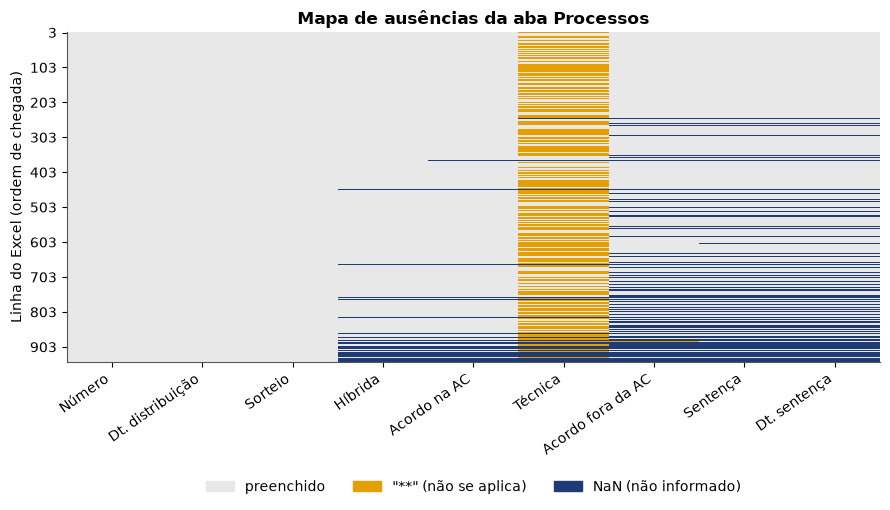

In [11]:
codigo_ausencia = pd.DataFrame({
    c: np.select([dados_brutos[c].isna(), dados_brutos[c].astype(str).eq('**')], [2, 1], 0)
    for c in COLUNAS_DIGITADAS})
fig, ax = plt.subplots(figsize=(9, 5.5))
mapa = mpl.colors.ListedColormap(['#e8e8e8', '#E69F00', '#1f3b73'])
ax.imshow(codigo_ausencia.to_numpy(), aspect='auto', cmap=mapa, interpolation='nearest', vmin=0, vmax=2)
ROTULOS_CURTOS = ['Número', 'Dt. distribuição', 'Sorteio', 'Híbrida', 'Acordo na AC', 'Técnica', 'Acordo fora da AC',
                  'Sentença', 'Dt. sentença']
ax.set_xticks(range(len(COLUNAS_DIGITADAS)), ROTULOS_CURTOS, rotation=35, ha='right')
ax.set_yticks(np.arange(0, len(codigo_ausencia), 100), dados_brutos.index[::100])
ax.set_ylabel('Linha do Excel (ordem de chegada)')
ax.grid(False)
ax.set_title('Mapa de ausências da aba Processos')
legenda = [mpl.patches.Patch(color=c, label=r) for c, r in
           zip(['#e8e8e8', '#E69F00', '#1f3b73'], ['preenchido', '"**" (não se aplica)', 'NaN (não informado)'])]
ax.legend(handles=legenda, loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=3)
plt.tight_layout()
plt.show()

**Leitura. As ausências são estruturais: dependem da etapa em que o processo está.**

- **Não há texto vazio nem espaços soltos**; as ausências são `NaN` (célula vazia) ou o marcador `**`.
- **`**` aparece em duas colunas.** Em `TÉCNICA` (515 linhas) significa que a audiência não foi realizada: todo o Controle e parte dos tratados. Em `ACORDO FORA DA AC?` aparece uma única vez (linha 888), um erro de preenchimento.
- **Os `NaN` formam blocos coerentes com a tramitação:**
  - **733 linhas completas**, todas encerradas;
  - **132 ativos** com audiência já registrada, aguardando o acordo fora e a sentença (padrão `00011`);
  - **72 linhas sem nada após o sorteio** (padrão `11111`): 71 ativos e a linha 920, recém-distribuídos, **todos dos grupos com audiência** (24 Presencial, 48 Remota, 0 Controle). No Controle não há audiência a aguardar, e a unidade já preenche `Não`/`**` na distribuição;
  - **sete linhas com padrões isolados**, listadas na tabela e tratadas nas seções 1.10 e 1.11. A mais relevante é a linha 373: um processo encerrado com a técnica em branco.
- **No mapa, os `NaN` se concentram nas últimas linhas**, as de chegada mais recente. É a assinatura de uma ausência que depende do tempo de acompanhamento, e não de um sorteio ao acaso (não é MCAR).
- **Consequência.** Nenhuma imputação é necessária nem adequada. O desfecho principal (tempo até a sentença) trata a falta de sentença como **censura**. As variáveis de processo (híbrida, técnica, acordo na AC) são analisadas onde se aplicam, com a ausência declarada, e não por exclusão silenciosa de casos incompletos, como fazem os testes do notebook do professor (E5).

---

## 1.7 Cópia de trabalho, nomes das colunas e registro de tratamentos

A partir daqui as transformações acontecem em `trab`, uma cópia de `dados_brutos` com nomes em *snake_case* (minúsculas, sem acento, válidos como identificador Python). As colunas calculadas (J a O) são mantidas na cópia apenas para conferência e descartadas no dataset final.

Cada correção, exclusão ou recodificação é anotada pela função `registrar()` num **log de tratamentos**, com a linha do Excel, o processo, a variável, o valor original, o valor novo, o problema e a justificativa. O código `A`*n* remete ao catálogo de anomalias da auditoria dos dados.

In [12]:
RENOMEAR = {
    'NÚMERO DO PROCESSO': 'numero_bruto', 'DT. DISTRIBUIÇÃO': 'dt_distribuicao', 'SORTEIO': 'sorteio',
    'HÍBRIDA': 'hibrida_bruto', 'TEVE ACORDO NA AC?': 'acordo_ac_bruto', 'TÉCNICA': 'tecnica_bruto',
    'TEVE ACORDO FORA DA AC?': 'acordo_fora_bruto', 'SENTENÇA': 'sentenca_bruto', 'DT. SENTENÇA': 'dt_sentenca',
    'DURAÇÃO-SENT2': 'xl_duracao_sent2', 'DURAÇÃO-TECN': 'xl_duracao_tecn', 'DURAÇÃO-SORT': 'xl_duracao_sort',
    'DURAÇÃO-PROC': 'xl_duracao_proc', ' DURAÇÃO DO PROCESSO': 'xl_duracao_texto', 'STATUS': 'xl_status',
}
trab = dados_brutos.rename(columns=RENOMEAR).copy()
assert set(RENOMEAR) == set(dados_brutos.columns)
assert all(c.isidentifier() and c.isascii() for c in trab.columns)

_registros = []


def registrar(linhas, variavel, valor_novo, problema, tratamento, codigo, valor_original=None):
    """Anota um tratamento para cada linha do Excel informada (valor original lido de dados_brutos)."""
    linhas = [linhas] if np.isscalar(linhas) else list(linhas)
    coluna_bruta = {v: k for k, v in RENOMEAR.items()}.get(variavel)
    for linha in linhas:
        original = valor_original
        if original is None and coluna_bruta is not None:
            original = dados_brutos.at[linha, coluna_bruta]
        _registros.append({'codigo': codigo, 'linha_excel': int(linha),
                           'processo_bruto': dados_brutos.at[linha, 'NÚMERO DO PROCESSO'],
                           'variavel': variavel, 'valor_original': repr(original) if isinstance(original, str) else str(original),
                           'valor_novo': str(valor_novo), 'problema': problema, 'tratamento': tratamento})


def log_tratamentos():
    return pd.DataFrame(_registros)


display(pd.DataFrame({'Coluna original': [repr(k) for k in RENOMEAR], 'Nome na cópia de trabalho': list(RENOMEAR.values())}))

,Coluna original,Nome na cópia de trabalho
0,'NÚMERO DO PROCESSO',numero_bruto
1,'DT. DISTRIBUIÇÃO',dt_distribuicao
2,'SORTEIO',sorteio
3,'HÍBRIDA',hibrida_bruto
4,'TEVE ACORDO NA AC?',acordo_ac_bruto
5,'TÉCNICA',tecnica_bruto
6,'TEVE ACORDO FORA DA AC?',acordo_fora_bruto
7,'SENTENÇA',sentenca_bruto
8,'DT. SENTENÇA',dt_sentenca
9,'DURAÇÃO-SENT2',xl_duracao_sent2


---

## 1.8 Número do processo (CNJ)

O número único segue a Resolução CNJ 65/2008: `NNNNNNN-DD.AAAA.J.TR.OOOO` (sequencial, dígito verificador, ano de ajuizamento, segmento da Justiça, tribunal e órgão de origem). O dígito verificador (DV) é calculado pelo **módulo 97** (ISO 7064): `DD = 98 − (NNNNNNN AAAA J TR OOOO 00 mod 97)`. Validar o DV detecta erros de digitação no número, a chave que permite cruzar a base com o PJe e o DataJud.

A limpeza tem três passos, cada um registrado:

1. remover espaços e quebras de linha nas bordas;
2. remover hífen final digitado por engano;
3. completar o órgão truncado com 3 dígitos, **somente se** o DV confirmar o órgão do estudo (5004 = 4º JEC de Natal).

In [13]:
PADRAO_CNJ = re.compile(r'^(\d{7})-(\d{2})\.(\d{4})\.(\d)\.(\d{2})\.(\d{4})$')


def dv_cnj(sequencial, ano, j, tr, orgao):
    """Dígito verificador CNJ (mod 97, ISO 7064)."""
    return 98 - int(f'{sequencial}{ano}{j}{tr}{orgao}00') % 97


def cnj_valido(numero):
    m = PADRAO_CNJ.fullmatch(str(numero))
    return bool(m) and int(m.group(2)) == dv_cnj(m.group(1), m.group(3), m.group(4), m.group(5), m.group(6))


numero = trab['numero_bruto'].astype('string')
fora = ~numero.map(lambda n: bool(PADRAO_CNJ.fullmatch(n))).astype(bool)
print('Fora do padrão antes da limpeza:', int(fora.sum()), '→ linhas', list(trab.index[fora]))
display(numero[fora].map(repr).rename('valor bruto (repr)').to_frame())

# Passo 1 — espaços e quebras de linha
passo1 = numero.str.strip()
alterado = trab.index[passo1 != numero]
registrar(alterado, 'numero_bruto', '(sem espaços)', 'Espaço ou quebra de linha no fim do número',
          'strip()', 'A7')

# Passo 2 — hífen final
passo2 = passo1.str.replace(r'\s*-\s*$', '', regex=True)
alterado = trab.index[passo2 != passo1]
registrar(alterado, 'numero_bruto', '(sem hífen final)', 'Hífen digitado após o número', 'Sufixo removido', 'A7')

# Passo 3 — órgão truncado (3 dígitos): candidatos que fecham o DV
truncado = passo2.str.match(r'^\d{7}-\d{2}\.\d{4}\.\d\.\d{2}\.\d{3}$')
candidatos = {}
for linha in trab.index[truncado]:
    seq, dv, ano, j, tr, _ = re.split(r'[-.]', passo2[linha])
    candidatos[linha] = [o for o in range(5000, 5400) if dv_cnj(seq, ano, j, tr, o) == int(dv)]
display(pd.DataFrame({'Número truncado': passo2[truncado],
                      'Órgãos 5000–5399 com DV válido': pd.Series(candidatos)}))
passo3 = passo2.copy()
for linha, lista in candidatos.items():
    assert 5004 in lista, f'linha {linha}: DV não fecha com 5004'
    passo3[linha] = passo2[linha] + '4'
registrar(list(candidatos), 'numero_bruto', '(órgão 5004)', 'Órgão de origem com 3 dígitos ("500")',
          'Completado para 5004: DV confere e é a vara do estudo; flag cnj_corrigido', 'A8')

trab['processo'] = passo3
trab['cnj_corrigido'] = trab.index.isin(trab.index[(passo3 != numero.str.strip())])
partes = trab['processo'].str.extract(PADRAO_CNJ)
partes.columns = ['seq', 'dv', 'ano', 'j', 'tr', 'orgao']
trab['dv_valido'] = trab['processo'].map(cnj_valido)
trab['cnj_ano'] = partes['ano'].astype('Int64')
trab['cnj_orgao'] = partes['orgao']
print(f'Após a limpeza: {int(partes["seq"].notna().sum())} no padrão; DV válido em {int(trab["dv_valido"].sum())}; '
      f'J.TR = {sorted((partes["j"] + "." + partes["tr"]).unique())}')
assert trab['dv_valido'].all()

Fora do padrão antes da limpeza: 6 → linhas [55, 377, 443, 453, 692, 771]


,valor bruto (repr)
linha_excel,
55,'0800780-87.2026.8.20.5004-'
377,'0805750-33.2026.8.20.5004\xa0-'
443,'0806633-77.2026.8.20.500'
453,'0806739-39.2026.8.20.500'
692,'0809702-20.2026.8.20.5004 '
771,'0811548-72.2026.8.20.5004\n'


,Número truncado,Órgãos 5000–5399 com DV válido
443,0806633-77.2026.8.20.500,"[5004, 5101, 5198, 5295, 5392]"
453,0806739-39.2026.8.20.500,"[5004, 5101, 5198, 5295, 5392]"


Após a limpeza: 944 no padrão; DV válido em 944; J.TR = ['8.20']


### 1.8.1 Processos de outro órgão ou de ano anterior

O órgão `5004` é o 4º JEC de Natal e o ano esperado é 2026. Números de outro órgão ou de ano anterior indicam processos **ajuizados em outra unidade e redistribuídos** ao 4º JEC: a "data de distribuição" da planilha é a data de chegada à vara, não a do ajuizamento. Eles são mantidos (entraram no sorteio quando chegaram, e o relógio do estudo começa ali), marcados com `origem_externa` para análise de sensibilidade.

In [14]:
trab['origem_externa'] = trab['cnj_orgao'].ne('5004') | trab['cnj_ano'].lt(2026)
display(pd.crosstab([trab['cnj_ano'], trab['cnj_orgao']], trab['sorteio'], margins=True, margins_name='Total'))
registrar(trab.index[trab['origem_externa']], 'numero_bruto', 'origem_externa=True',
          'Número de outro órgão ou de ano anterior (processo redistribuído à vara)',
          'Mantido; flag origem_externa para sensibilidade', 'A9', valor_original='(órgão/ano)')
print(f'origem_externa: {int(trab["origem_externa"].sum())} linhas')

sorteio            Ac Obrigatória Presencial  Ac Remota  Rito Atual Ac Opcional  Total
cnj_ano cnj_orgao                                                                     
2023    5004                               1          0                       0      1
2025    5004                               1          0                       1      2
        5300                               0          0                       1      1
2026    5001                               1          1                       0      2
        5004                             309        312                     311    932
        5106                               1          0                       0      1
        5124                               0          1                       0      1
        5129                               0          0                       1      1
        5300                               3          0                       0      3
Total                                    316        314                     314    944

origem_externa: 12 linhas


---

## 1.9 Duplicidades e reentradas

A unidade experimental é o **processo**: cada um deve aparecer uma vez, com o grupo do seu sorteio. Depois da limpeza do número, há processos com mais de uma linha. A tabela mostra todos, para que a regra de decisão seja verificável:

In [15]:
duplicados = trab[trab['processo'].duplicated(keep=False)].sort_values(['processo', 'dt_distribuicao'])
display(duplicados[['processo', 'dt_distribuicao', 'sorteio', 'tecnica_bruto', 'sentenca_bruto', 'dt_sentenca',
                    'xl_status']])
print(f'{duplicados["processo"].nunique()} números repetidos em {len(duplicados)} linhas; '
      f'{trab["processo"].nunique()} processos distintos')

,processo,dt_distribuicao,sorteio,tecnica_bruto,sentenca_bruto,dt_sentenca,xl_status
linha_excel,,,,,,,
162,0802424-65.2026.8.20.5004,2026-02-13,Ac Obrigatória Presencial,**,Decisão,2026-02-18,Encerrado
164,0802424-65.2026.8.20.5004,2026-02-13,Ac Obrigatória Presencial,NaN,NaN,NaT,Ativo
290,0804436-52.2026.8.20.5004,2026-03-18,Ac Obrigatória Presencial,**,Decisão,2026-03-18,Encerrado
322,0804436-52.2026.8.20.5004,2026-03-24,Ac Obrigatória Presencial,**,Decisão,2026-04-09,Encerrado
475,0804436-52.2026.8.20.5004,2026-04-27,Rito Atual Ac Opcional,**,Decisão,2026-04-27,Encerrado
591,0808905-44.2026.8.20.5004,2026-05-20,Ac Remota,**,Decisão,2026-05-21,Encerrado
607,0808905-44.2026.8.20.5004,2026-05-22,Ac Remota,**,NaN,NaT,Ativo
819,0812314-28.2026.8.20.5004,2026-07-08,Ac Remota,NaN,NaN,NaT,Ativo
822,0812314-28.2026.8.20.5004,2026-07-08,Ac Remota,**,Extinção do Feito com Homologação do Acordo,2026-09-16,Encerrado


5 números repetidos em 11 linhas; 938 processos distintos


Há duas situações diferentes:

- **Duplicata de registro** (A3, A4): a segunda linha é uma cópia vazia ou desatualizada do mesmo processo, no mesmo grupo. Mantê-la criaria um **falso censurado** (por exemplo, a linha 164 ficaria "ativa" por 236 dias, embora o processo tenha sido redistribuído em 5 dias). → excluir a cópia e manter o registro mais antigo/completo.
- **Reentrada após `Decisão`** (A5): o processo saiu por redistribuição, voltou à vara e foi **sorteado de novo**; o `0804436-52` passou de Presencial para Controle. Reentradas violam a unicidade da unidade experimental e contaminam os grupos (E3). → na base primária, por **intenção de tratar**, vale só o **primeiro episódio**, com o grupo do primeiro sorteio. As alternativas (excluir o processo; unir os episódios) ficam para a análise de sensibilidade, a partir do arquivo com todas as linhas.

In [16]:
EXCLUIR_PRIMARIA = {
    164: ('A3', 'Duplicata de 162: mesma data e grupo, linha vazia (falso censurado)'),
    819: ('A3', 'Duplicata de 822: mesma data e grupo, registro desatualizado sem desfecho'),
    857: ('A4', 'Duplicata de 851 (dia seguinte, mesmo grupo); mantido o registro mais antigo e completo'),
    322: ('A5', 'Reentrada (2º episódio) de 0804436-52 após Decisão; re-sorteado'),
    475: ('A5', 'Reentrada (3º episódio) de 0804436-52 após Decisão; re-sorteado para outro grupo'),
    607: ('A5', 'Reentrada de 0808905-44 um dia após a Decisão; re-sorteado'),
}
# Conferência: toda linha excluída tem o mesmo número que uma linha mantida, e esta é anterior ou igual na data
for linha, (codigo, motivo) in EXCLUIR_PRIMARIA.items():
    mesmos = trab.index[trab['processo'].eq(trab.at[linha, 'processo'])]
    mantidas = [m for m in mesmos if m not in EXCLUIR_PRIMARIA]
    assert len(mantidas) == 1 and trab.at[mantidas[0], 'dt_distribuicao'] <= trab.at[linha, 'dt_distribuicao']
    registrar(linha, 'processo', 'excluída da base primária', motivo,
              f'Excluída; mantida a linha {mantidas[0]} (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)',
              codigo, valor_original=trab.at[linha, 'processo'])

trab['base_primaria'] = ~trab.index.isin(list(EXCLUIR_PRIMARIA))
trab['motivo_exclusao'] = pd.Series({k: f'{v[0]}: {v[1]}' for k, v in EXCLUIR_PRIMARIA.items()},
                                    dtype='string').reindex(trab.index)
trab['duplicado_removido'] = trab['processo'].duplicated(keep=False) & trab['base_primaria']
trab['reentrada'] = trab['processo'].duplicated(keep='first')  # 2º episódio em diante (inclui duplicatas)
assert not trab.loc[trab['base_primaria'], 'processo'].duplicated().any()
print('Base primária:', int(trab['base_primaria'].sum()), 'processos')
display(pd.crosstab(trab['sorteio'], trab['base_primaria'].map({True: 'mantidas', False: 'excluídas'}),
                    margins=True, margins_name='Total'))

Base primária: 938 processos


base_primaria,excluídas,mantidas,Total
sorteio,,,
Ac Obrigatória Presencial,2,314,316
Ac Remota,3,311,314
Rito Atual Ac Opcional,1,313,314
Total,6,938,944


**Leitura.**

- **São 5 números repetidos em 11 linhas**, ou seja, 6 linhas a mais que processos. O notebook do professor contou essas 6 linhas extras como "6 duplicatas" e não as tratou (E3).
- **Três são duplicatas de registro** (linhas 164, 819 e 857): cópias vazias ou desatualizadas do mesmo processo, no mesmo grupo. A linha 164, por exemplo, ficaria "em tramitação" por 236 dias, quando o processo foi redistribuído 5 dias depois de chegar (linha 162).
- **Três são reentradas re-sorteadas** (linhas 322, 475 e 607):
  - o processo `0804436-52` saiu por `Decisão` em 18/03, voltou em 24/03 (Presencial, nova Decisão em 09/04) e voltou de novo em 27/04, quando foi sorteado para o **Controle** (nova Decisão no mesmo dia);
  - o `0808905-44` foi redistribuído em 21/05 e voltou no dia 22/05, sorteado de novo.
- **Lição de desenho.** Um processo que sai e volta não deveria passar por novo sorteio: deveria herdar o grupo original.
- **Base primária: 938 processos** (Controle 313, Presencial 314, Remota 311), cada um com o grupo do primeiro sorteio (intenção de tratar). As 944 linhas ficam preservadas em `ed2_todas_linhas.pkl` para as análises de sensibilidade.

---

## 1.10 Categorias: grafia, partições e recodificações

### 1.10.1 Funções de normalização

Uma variável categórica bem construída é uma **partição** dos casos: exaustiva, disjunta, sem classes vazias e sem sinônimos (a mesma categoria com duas grafias). Três funções garantem isso:

- `limpar_texto` colapsa espaços e quebras de linha e converte texto vazio em `<NA>`;
- `normalizar_chave` gera uma chave de comparação sem acento, em maiúsculas e com espaços simples; duas grafias com a mesma chave são **sinônimos**;
- `para_categoria` aplica um **mapa explícito** (valor original → rótulo) e recusa valores não previstos; `verificar_particao` confere as propriedades com `assert`, de modo que um erro interrompe a execução em vez de passar despercebido.

In [17]:
def limpar_texto(serie):
    """Colapsa espaços/quebras de linha e converte vazio em NA (dtype string)."""
    return serie.astype('string').str.replace(r'\s+', ' ', regex=True).str.strip().replace('', pd.NA)


def normalizar_chave(texto):
    """Chave de comparação: sem acentos, maiúscula, espaços simples (não altera o dado)."""
    if pd.isna(texto):
        return pd.NA
    texto = unicodedata.normalize('NFKD', str(texto))
    texto = ''.join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r'\s+', ' ', texto).strip().upper()


def para_categoria(serie, mapa, ordem, ordenada=False):
    """Aplica um mapa exaustivo (valor original → rótulo) e devolve dtype category."""
    sem_mapa = sorted(set(serie.dropna().unique()) - set(mapa))
    assert not sem_mapa, f'Valores sem mapeamento: {sem_mapa}'
    rotulos = serie.map(mapa)
    assert set(rotulos.dropna()) <= set(ordem), 'Há rótulos fora da lista de categorias'
    return pd.Series(pd.Categorical(rotulos, categories=ordem, ordered=ordenada), index=serie.index, name=serie.name)


resumo_particoes = []


def verificar_particao(nova, nome, ausentes_permitidos=0):
    """Confere se uma variável category é partição: exaustiva, sem vazias e sem sinônimos."""
    contagem = nova.value_counts(sort=False, dropna=True)
    chaves = pd.Series(contagem.index.astype(str)).map(normalizar_chave)
    resultado = {'Variável': nome, 'Categorias': len(contagem), 'Vazias': int((contagem == 0).sum()),
                 'NA': int(nova.isna().sum()), 'Sinônimos': int(chaves.duplicated().sum()),
                 'Soma = n': int(contagem.sum() + nova.isna().sum()) == len(nova)}
    resultado['Partição válida'] = (resultado['Vazias'] == 0 and resultado['Sinônimos'] == 0
                                    and resultado['NA'] <= ausentes_permitidos and resultado['Soma = n'])
    assert resultado['Partição válida'], f'{nome} não é partição: {resultado}'
    resumo_particoes.append(resultado)
    return contagem


COLUNAS_TEXTO = ['sorteio', 'hibrida_bruto', 'acordo_ac_bruto', 'tecnica_bruto', 'acordo_fora_bruto', 'sentenca_bruto']
diagnostico = []
for c in COLUNAS_TEXTO:
    original = trab[c].astype('string')
    limpo = limpar_texto(trab[c])
    chaves = original.dropna().map(normalizar_chave)
    diagnostico.append({'Variável': c, 'Valores alterados pela limpeza': int((original != limpo).sum()),
                        'Grafias distintas': original.nunique(), 'Chaves distintas': chaves.nunique()})
    trab[c] = limpo
display(pd.DataFrame(diagnostico))

,Variável,Valores alterados pela limpeza,Grafias distintas,Chaves distintas
0,sorteio,0,3,3
1,hibrida_bruto,0,2,2
2,acordo_ac_bruto,0,2,2
3,tecnica_bruto,0,7,7
4,acordo_fora_bruto,0,3,3
5,sentenca_bruto,0,5,4


### 1.10.2 Tipo de sentença: uma variante de caixa e o significado de "Decisão"

`SENTENÇA` tem cinco grafias, mas só quatro chaves: `Extinção do feito sem julgamento de mérito` (minúsculas, 11 casos de janeiro) é a mesma categoria que `Extinção do Feito sem Julgamento de Mérito`. A validação de lista do Excel não distingue maiúsculas, por isso a variante passou.

`Decisão` **não é sentença**. Segundo o pesquisador, é a decisão que remete o processo para redistribuição a outro juízo, por prevenção: o processo **sai da vara** e o seu desfecho deixa de ser observado. Contá-la como sentença, como faz o notebook do professor (E10), encurta artificialmente o tempo dos grupos. Aqui ela vira o desfecho `Redistribuição`, tratado como censura na análise principal e como risco competitivo na complementar (Parte IV).

In [18]:
display(trab['sentenca_bruto'].value_counts(dropna=False).rename_axis('Grafia').to_frame('Linhas')
        .assign(Chave=lambda t: t.index.map(normalizar_chave)))

MAPA_SENTENCA = {
    'Extinção do Feito com Homologação do Acordo': 'Homologação',
    'Extinção do Feito com Julgamento de Mérito': 'Mérito',
    'Extinção do Feito sem Julgamento de Mérito': 'Sem mérito',
    'Extinção do feito sem julgamento de mérito': 'Sem mérito',
    'Decisão': 'Redistribuição',
}
variante = trab['sentenca_bruto'].eq('Extinção do feito sem julgamento de mérito').fillna(False)
registrar(trab.index[variante], 'sentenca_bruto', 'Sem mérito', 'Variante de caixa (minúsculas)',
          'Recodificada para a forma canônica', 'A6')
decisao = trab['sentenca_bruto'].eq('Decisão').fillna(False)
registrar(trab.index[decisao], 'sentenca_bruto', 'Redistribuição',
          '"Decisão" = remessa para redistribuição por prevenção (não é sentença)',
          'Desfecho Redistribuição; evento=0 (censura) e evento_cr=2 (risco competitivo)', 'A-Dec')

desfecho = trab['sentenca_bruto'].map(MAPA_SENTENCA).where(trab['sentenca_bruto'].notna(), 'Ativo')
trab['tipo_desfecho'] = para_categoria(desfecho, {v: v for v in ORDEM_DESFECHO}, ORDEM_DESFECHO)
display(pd.crosstab(trab['sentenca_bruto'].fillna('(vazio)'), trab['tipo_desfecho']))

,Linhas,Chave
Grafia,,
Extinção do Feito com Julgamento de Mérito,341,EXTINCAO DO FEITO COM JULGAMENTO DE MERITO
Extinção do Feito sem Julgamento de Mérito,275,EXTINCAO DO FEITO SEM JULGAMENTO DE MERITO
<NA>,210,<NA>
Extinção do Feito com Homologação do Acordo,81,EXTINCAO DO FEITO COM HOMOLOGACAO DO ACORDO
Decisão,26,DECISAO
Extinção do feito sem julgamento de mérito,11,EXTINCAO DO FEITO SEM JULGAMENTO DE MERITO


tipo_desfecho,Homologação,Mérito,Sem mérito,Redistribuição,Ativo
sentenca_bruto,,,,,
(vazio),0,0,0,0,210
Decisão,0,0,0,26,0
Extinção do Feito com Homologação do Acordo,81,0,0,0,0
Extinção do Feito com Julgamento de Mérito,0,341,0,0,0
Extinção do Feito sem Julgamento de Mérito,0,0,275,0,0
Extinção do feito sem julgamento de mérito,0,0,11,0,0


### 1.10.3 Grupo sorteado

Os rótulos longos da planilha passam a códigos curtos (`Controle`, `Presencial`, `Remota`), com `Controle` como **categoria de referência** (primeira posição). O rótulo descritivo fica em `grupo_rotulo`, para tabelas e legendas.

In [19]:
MAPA_GRUPO = {'Rito Atual Ac Opcional': 'Controle', 'Ac Obrigatória Presencial': 'Presencial', 'Ac Remota': 'Remota'}
trab['grupo'] = para_categoria(trab['sorteio'], MAPA_GRUPO, ORDEM_GRUPO)
trab['grupo_rotulo'] = para_categoria(trab['grupo'].astype('string'), ROTULO_GRUPO, list(ROTULO_GRUPO.values()))
display(pd.crosstab(trab['sorteio'], trab['grupo']))

grupo,Controle,Presencial,Remota
sorteio,,,
Ac Obrigatória Presencial,0,316,0
Ac Remota,0,0,314
Rito Atual Ac Opcional,314,0,0


### 1.10.4 Respostas Sim/Não, o `**` em "acordo fora" e a técnica

- **`HÍBRIDA`, `TEVE ACORDO NA AC?`, `TEVE ACORDO FORA DA AC?`** → `boolean` (`Sim` = True, `Não` = False, `NaN` = `<NA>`).
- **`**` em "acordo fora" (linha 888, A10):** processo extinto sem mérito em 8 dias, sem homologação → `False`.
- **`TÉCNICA`:** `**` significa que a AC **não foi realizada** (todo o Controle e parte dos tratados); vira `ac_realizada = False` e `tecnica = <NA>`. `NaN` significa "ainda não informado" (processos ativos sem audiência) → `ac_realizada = <NA>`. Essa separação é a que o notebook do professor não fez (E4).
- **Linha 373 (A11):** processo Presencial **encerrado** sem mérito em 1 dia, com técnica vazia; não houve AC → `**`.
- **Linha 249 (A14):** processo Remota ativo com "acordo na AC = Não" e técnica vazia; mantido `<NA>` (não se imputa).

In [20]:
SIM_NAO = {'Sim': True, 'Não': False}
for bruto, novo in [('hibrida_bruto', 'hibrida'), ('acordo_ac_bruto', 'acordo_ac'), ('acordo_fora_bruto', 'acordo_fora')]:
    valores = trab[bruto]
    if bruto == 'acordo_fora_bruto':
        estrela = valores.eq('**').fillna(False)
        registrar(trab.index[estrela], bruto, False, '"**" em acordo fora da AC (desfecho sem mérito, sem homologação)',
                  'Recodificado para Não (False)', 'A10')
        valores = valores.mask(estrela, 'Não')
    assert set(valores.dropna().unique()) <= set(SIM_NAO), (bruto, valores.unique())
    trab[novo] = valores.map(SIM_NAO).astype('boolean')

tecnica = trab['tecnica_bruto'].copy()
linha_373 = trab.index[tecnica.isna() & trab['tipo_desfecho'].ne('Ativo')]
assert list(linha_373) == [373]
registrar(linha_373, 'tecnica_bruto', '**', 'Técnica vazia em processo encerrado (sem mérito em 1 dia)',
          'Recodificada para "**" (AC não realizada)', 'A11')
tecnica[linha_373] = '**'
registrar(249, 'tecnica_bruto', '<NA>', 'Processo ativo com acordo na AC = Não e técnica vazia',
          'Mantido NA (não imputado)', 'A14')

trab['ac_realizada'] = pd.Series(np.where(tecnica.isna(), pd.NA, tecnica.ne('**')), index=trab.index).astype('boolean')
ORDEM_TECNICA = ['Desconstrução da Verdade', 'Parafraseamento', 'Separação de Pessoas e Problemas',
                 'Padrões Objetivos', 'Teoria do Afago ou do Reforço Positivo',
                 'Análise da Comunicação Verbal e Não-Verbal das Partes']
CURTA_TECNICA = dict(zip(ORDEM_TECNICA, ['Desconstrução', 'Parafraseamento', 'Separação', 'Padrões objetivos',
                                         'Afago', 'Comunicação']))
trab['tecnica'] = para_categoria(tecnica.where(tecnica.ne('**')), {t: t for t in ORDEM_TECNICA}, ORDEM_TECNICA)
trab['tecnica_curta'] = para_categoria(trab['tecnica'].astype('string'), CURTA_TECNICA, list(CURTA_TECNICA.values()))

# Acordo em qualquer momento: lógica de Kleene (True se houve algum; False só se ambos False)
trab['acordo'] = trab['acordo_ac'] | trab['acordo_fora']

display(pd.crosstab(trab['tecnica_bruto'].fillna('(NaN)'), trab['ac_realizada'].astype('string').fillna('<NA>'),
                    margins=True, margins_name='Total'))
display(pd.crosstab([trab['acordo_ac'].astype('string').fillna('<NA>'), trab['acordo_fora'].astype('string').fillna('<NA>')],
                    trab['tipo_desfecho']))

ac_realizada,<NA>,False,True,Total
tecnica_bruto,,,,
(NaN),76,1,0,77
**,0,515,0,515
Análise da Comunicação Verbal e Não-Verbal das Partes,0,0,63,63
Desconstrução da Verdade,0,0,47,47
Padrões Objetivos,0,0,67,67
Parafraseamento,0,0,57,57
Separação de Pessoas e Problemas,0,0,60,60
Teoria do Afago ou do Reforço Positivo,0,0,58,58
Total,76,516,352,944


tipo_desfecho          Homologação  Mérito  Sem mérito  Redistribuição  Ativo
acordo_ac acordo_fora                                                        
<NA>      <NA>                   0       0           0               0     75
False     <NA>                   0       0           0               0    133
          False                  0     341         286              26      2
          True                  64       0           0               0      0
True      False                 17       0           0               0      0

**Leitura.**

- **Uma só variante de grafia.** Nas seis colunas categóricas, a limpeza de espaços não alterou nenhum valor, e só `SENTENÇA` tem duas grafias para a mesma chave: 11 sentenças de janeiro escritas em minúsculas, unificadas na categoria `Sem mérito` (275 + 11 = **286**). As demais (grupo, híbrida, acordos, técnica) não têm sinônimos.
- **Desfechos nas 944 linhas:** 341 de mérito, 286 sem mérito, 81 homologações de acordo, 26 redistribuições (`Decisão`) e 210 sem desfecho.
- **Técnica e audiência.** 352 linhas têm técnica registrada (AC realizada), 516 têm `**` (as 515 originais mais a linha 373) e 76 seguem `<NA>`, por não haver ainda informação. As seis técnicas aparecem entre 47 (Desconstrução) e 67 (Padrões objetivos) vezes; o "53,85% de padrões objetivos" do resumo expandido não se reproduz nesta versão dos dados.
- **Acordo e sentença são perfeitamente coerentes.** As 81 homologações correspondem exatamente a 17 acordos na AC e 64 fora dela. Não há acordo marcado sem homologação, nem homologação sem acordo, nem acordo nos dois momentos. Por isso `acordo` (qualquer momento) é igual a "sentença homologatória" sempre que é conhecido.
- **`<NA>` nos acordos só ocorre em processos ativos:** 75 sem nenhuma das duas respostas e 133 com "Não" na AC e o acordo fora ainda em aberto. Para um processo em tramitação, "ainda não houve acordo" não é "não houve acordo", e a variável não é preenchida com `False`.

---

## 1.11 Desvios de protocolo e coerência do desenho

O protocolo define o que é possível em cada grupo. Três verificações:

- **Controle sem audiência (A18):** o grupo de rito atual não deveria ter AC, técnica nem acordo na AC. Se isso se confirma, o contraste real do experimento é "**com AC obrigatória × sem AC**".
- **Híbrida na Remota (A12):** por definição do pesquisador, a híbrida é uma AC *presencial* em que uma parte participou à distância (Res. CNJ 481). Uma híbrida no grupo Remota é incongruente.
- **Híbrida sem AC (A13):** marcar "híbrida = Sim" pressupõe que a audiência ocorreu; com técnica `**`, há contradição.

Os casos são **mantidos no grupo sorteado** (análise por intenção de tratar, ITT) e marcados com `desvio_protocolo` para a análise "conforme tratado". A variável `hibrida` é, ela mesma, **pós-sorteio** (decorre do pedido da parte): é adesão parcial ao rito presencial, não um quarto grupo aleatorizado (E11).

In [21]:
coerencia_grupo = pd.DataFrame({
    'AC realizada': trab.groupby('grupo', observed=True)['ac_realizada'].sum(),
    'Técnica registrada': trab.groupby('grupo', observed=True)['tecnica'].count(),
    'Acordo na AC': trab.groupby('grupo', observed=True)['acordo_ac'].sum(),
    'Acordo fora da AC': trab.groupby('grupo', observed=True)['acordo_fora'].sum(),
    'Híbrida = Sim': trab.groupby('grupo', observed=True)['hibrida'].sum(),
    'Linhas': trab.groupby('grupo', observed=True).size(),
})
display(coerencia_grupo)
assert coerencia_grupo.loc['Controle', ['AC realizada', 'Técnica registrada', 'Acordo na AC', 'Híbrida = Sim']].eq(0).all()

trab['hibrida_remota'] = (trab['hibrida'].fillna(False) & trab['grupo'].eq('Remota')).astype(bool)
trab['hibrida_sem_ac'] = (trab['hibrida'].fillna(False) & trab['ac_realizada'].eq(False).fillna(False)).astype(bool)
trab['desvio_protocolo'] = trab['hibrida_remota'] | trab['hibrida_sem_ac']
registrar(trab.index[trab['hibrida_remota']], 'hibrida_bruto', 'desvio_protocolo=True',
          'Audiência híbrida no grupo Remota (protocolo prevê híbrida só na presencial)',
          'Mantido no grupo sorteado (ITT); flag hibrida_remota', 'A12')
registrar(trab.index[trab['hibrida_sem_ac']], 'hibrida_bruto', 'desvio_protocolo=True',
          'Híbrida = Sim com técnica "**" (AC não realizada): contraditório',
          'Mantido; flag hibrida_sem_ac; consultar a pesquisadora', 'A13')
display(trab.loc[trab['desvio_protocolo'], ['processo', 'grupo', 'hibrida', 'tecnica_bruto', 'tipo_desfecho',
                                            'hibrida_remota', 'hibrida_sem_ac']])

,AC realizada,Técnica registrada,Acordo na AC,Acordo fora da AC,Híbrida = Sim,Linhas
grupo,,,,,,
Controle,0,0,0,21,0,314
Presencial,178,178,9,16,28,316
Remota,174,174,8,27,3,314


,processo,grupo,hibrida,tecnica_bruto,tipo_desfecho,hibrida_remota,hibrida_sem_ac
linha_excel,,,,,,,
318,0804822-82.2026.8.20.5004,Remota,True,Separação de Pessoas e Problemas,Mérito,True,False
433,0806545-39.2026.8.20.5004,Presencial,True,**,Sem mérito,False,True
455,0806829-47.2026.8.20.5004,Presencial,True,**,Homologação,False,True
456,0806797-42.2026.8.20.5004,Remota,True,Teoria do Afago ou do Reforço Positivo,Ativo,True,False
712,0810564-88.2026.8.20.5004,Presencial,True,**,Sem mérito,False,True
832,0812493-59.2026.8.20.5004,Remota,True,<NA>,Ativo,True,False


### 1.11.1 As redistribuições (`Decisão`)

Quando ocorrem as redistribuições? Se quase todas acontecem nos primeiros dias, antes de qualquer audiência, o processo saiu do estudo antes de poder receber o tratamento.

In [22]:
redist = trab[trab['tipo_desfecho'].eq('Redistribuição')].copy()
redist['dias'] = (redist['dt_sentenca'] - redist['dt_distribuicao']).dt.days
print(f'{len(redist)} redistribuições (todas as linhas); na base primária: {int(redist["base_primaria"].sum())}')
display(redist.groupby('grupo', observed=True)['dias'].describe()[['count', 'min', '50%', 'mean', 'max']])
display(redist.loc[redist['ac_realizada'].fillna(False), ['processo', 'grupo', 'tecnica', 'dias']]
        .rename(columns={'dias': 'dias até a Decisão'}))

26 redistribuições (todas as linhas); na base primária: 24


,count,min,50%,mean,max
grupo,,,,,
Controle,6.0,0.0,1.0,4.166667,20.0
Presencial,11.0,0.0,1.0,3.000000,16.0
Remota,9.0,1.0,8.0,25.444444,84.0


,processo,grupo,tecnica,dias até a Decisão
linha_excel,,,,
395,0805907-06.2026.8.20.5004,Remota,Teoria do Afago ou do Reforço Positivo,84
571,0808552-04.2026.8.20.5004,Remota,Padrões Objetivos,74


**Leitura.**

- **O Controle não teve nenhuma audiência.** São 0 audiências, 0 técnicas, 0 acordos na AC e 0 híbridas em 314 processos. O contraste real do experimento é, portanto, "**AC obrigatória × nenhuma AC**", e não "AC obrigatória × AC opcional". O acordo fora da audiência existe nos três grupos (21 no Controle, 16 na Presencial, 27 na Remota) e é o único desfecho de acordo comparável entre os três.
- **Nem todo tratado teve audiência.** Só 178 dos 316 processos da Presencial (56%) e 174 dos 314 da Remota (55%) têm técnica registrada. Os demais foram extintos antes da audiência (`**`) ou ainda a aguardam (`<NA>`). A análise por intenção de tratar (ITT) compara os **grupos sorteados**, não "quem teve audiência", para não quebrar a aleatorização.
- **Desvios de protocolo em 6 processos, todos mantidos no grupo sorteado e sinalizados:**
  - 3 híbridas no grupo **Remota** (linhas 318, 456 e 832), quando a híbrida, por definição, é uma variação da audiência presencial;
  - 3 híbridas na Presencial com técnica `**` (linhas 433, 455 e 712), o que é contraditório. Uma delas (455) terminou em homologação.
- **A híbrida é adesão parcial, não tratamento.** Ela ocorreu em 28 processos da Presencial, a pedido da parte, e não foi sorteada. Uma comparação "híbrida × presencial" é observacional.
- **As redistribuições são quase sempre imediatas.** A mediana é de 1 dia no Controle e na Presencial e de 8 dias na Remota. Só 2 ocorreram depois da audiência: as linhas 395 (84 dias) e 571 (74 dias), ambas da Remota, que puxam a média desse grupo para 25,4 dias. Em geral, o processo sai da vara antes que o tratamento possa agir, e por isso a `Decisão` é censura ou risco competitivo, nunca sentença (E10).

---

## 1.12 O dataset *tidy*: tempo, evento e variáveis derivadas

### 1.12.1 Tempo e evento

A análise de sobrevivência precisa de dois números por processo:

- **`tempo`** — dias corridos da distribuição até o desfecho (`dt_sentenca`), ou até a **data de corte** (07/10/2026) se não houve desfecho. É recalculado pelas datas; as colunas de duração do Excel não são usadas (A1, A17);
- **`evento`** — `1` se o processo foi **sentenciado** (mérito, sem mérito ou homologação de acordo); `0` se está **censurado**: em tramitação na data de corte ou **redistribuído** (sai da vara no dia da Decisão, sem sentença observada).

Duas codificações complementares:

- **`evento_cr`** (riscos competitivos): `0` = censurado (ativo), `1` = sentença, `2` = redistribuição;
- **`causa`** (desfecho específico): `0` = censurado, `1` = homologação, `2` = mérito, `3` = sem mérito, `4` = redistribuição. Permite estudar, por exemplo, o tempo até a homologação de acordo, que é onde a conciliação atua diretamente.

Há processos com tempo **zero** (desfecho no próprio dia da distribuição). Kaplan-Meier e Cox os aceitam; os modelos paramétricos (AFT) exigem tempo positivo, por isso `tempo_pos` substitui 0 por 0,5 dia (convenção documentada, não imputação; A15).

O **acompanhamento** (`followup`) é o tempo entre a distribuição e a data de corte: o máximo que cada processo poderia ser observado. Como a entrada é escalonada (janeiro a agosto), o acompanhamento varia de 65 a 279 dias, e é por isso que a média simples dos tempos, sem tratar a censura, não é um estimador válido (E7, E14).

In [23]:
CODIGO_CAUSA = {'Ativo': 0, 'Homologação': 1, 'Mérito': 2, 'Sem mérito': 3, 'Redistribuição': 4}
CODIGO_CR = {'Ativo': 0, 'Homologação': 1, 'Mérito': 1, 'Sem mérito': 1, 'Redistribuição': 2}
SENTENCAS = ['Homologação', 'Mérito', 'Sem mérito']

fim = trab['dt_sentenca'].fillna(DATA_CORTE)
trab['tempo'] = (fim - trab['dt_distribuicao']).dt.days.astype('Int64')
trab['tempo_pos'] = trab['tempo'].astype('float64').mask(trab['tempo'].eq(0), 0.5)
trab['evento'] = trab['tipo_desfecho'].isin(SENTENCAS).astype('Int64')
trab['evento_cr'] = trab['tipo_desfecho'].astype('string').map(CODIGO_CR).astype('Int64')
trab['causa'] = trab['tipo_desfecho'].astype('string').map(CODIGO_CAUSA).astype('Int64')
trab['encerrado'] = trab['dt_sentenca'].notna().astype('boolean')
trab['followup'] = (DATA_CORTE - trab['dt_distribuicao']).dt.days.astype('Int64')
trab['tempo_zero'] = trab['tempo'].eq(0).astype('boolean')
trab['sem_formula_excel'] = trab['xl_duracao_proc'].isna().astype('boolean')

registrar(trab.index[trab['tipo_desfecho'].eq('Ativo')], 'xl_duracao_proc', 'tempo = 07/10/2026 − distribuição',
          'Duração dos ativos calculada com TODAY() (volátil)', 'Censurado em DATA_CORTE fixa; evento=0', 'A1')
registrar(trab.index[trab['sem_formula_excel']], 'xl_duracao_proc', 'tempo = 70; evento = 0',
          'Linha sem nenhuma fórmula (STATUS vazio)', 'Mantida: ativo censurado em 07/10/2026 (data de distribuição válida)', 'A2')
registrar(trab.index[trab['tempo_zero']], 'tempo', 'tempo=0; tempo_pos=0,5',
          'Desfecho no próprio dia da distribuição', 'Mantido; tempo_pos=0,5 só para modelos paramétricos', 'A15',
          valor_original='0')

# Conferência com a coluna DURAÇÃO-PROC do Excel (valores em cache)
confere = trab['tempo'].astype('float64').eq(trab['xl_duracao_proc'])
print(f'tempo recalculado = DURAÇÃO-PROC do Excel em {int(confere.sum())} de {len(trab)} linhas; '
      f'divergentes: {list(trab.index[~confere])} (sem fórmula no Excel)')

tempo recalculado = DURAÇÃO-PROC do Excel em 943 de 944 linhas; divergentes: [920] (sem fórmula no Excel)


### 1.12.2 Variáveis de calendário e ordem de chegada

Segundo o pesquisador, o sorteio "seguiu rigorosamente a ordem de chegada" dos processos, e as linhas da planilha estão nessa ordem (a data de distribuição nunca decresce de uma linha para a seguinte). Derivam-se:

- **`ordem_chegada`** — posição do processo na sequência de chegada da base primária (1 = primeiro); variável **ordinal**, usada na questão 2.7;
- **`dia_estudo`** — dias desde 01/01/2026 (tempo de calendário da entrada, quantitativo);
- **`mes_distribuicao`** — mês de entrada (ordinal); como a censura depende do mês de entrada, é a covariável natural de estratificação;
- **`ciclo`** — os "dois ciclos" do resumo expandido: 01/01–28/04 e 29/04–03/08/2026;
- **`dia_semana_distribuicao`** e **`sentenca_fim_semana`** — sentenças em sábado ou domingo sugerem que a data registrada pode ser a de **lançamento** no sistema (ou de mutirão), não a da assinatura (A16).

In [24]:
assert trab['dt_distribuicao'].is_monotonic_increasing, 'linhas fora da ordem cronológica'
DIAS = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
MESES = {1: 'jan', 2: 'fev', 3: 'mar', 4: 'abr', 5: 'mai', 6: 'jun', 7: 'jul', 8: 'ago'}

trab['dia_estudo'] = (trab['dt_distribuicao'] - DATA_INICIO).dt.days.astype('Int64')
trab['mes_distribuicao'] = pd.Categorical(trab['dt_distribuicao'].dt.month.map(MESES),
                                          categories=list(MESES.values()), ordered=True)
trab['ciclo'] = pd.Categorical(np.where(trab['dt_distribuicao'] <= pd.Timestamp('2026-04-28'), '1º ciclo', '2º ciclo'),
                               categories=['1º ciclo', '2º ciclo'], ordered=True)
trab['dia_semana_distribuicao'] = pd.Categorical(trab['dt_distribuicao'].dt.dayofweek.map(dict(enumerate(DIAS))),
                                                 categories=DIAS, ordered=True)
trab['sentenca_fim_semana'] = pd.Series(pd.NA, index=trab.index, dtype='boolean')
tem_data = trab['dt_sentenca'].notna()
trab.loc[tem_data, 'sentenca_fim_semana'] = trab.loc[tem_data, 'dt_sentenca'].dt.dayofweek.ge(5)
registrar(trab.index[trab['sentenca_fim_semana'].fillna(False)], 'dt_sentenca', '(mantida)',
          'Sentença datada em sábado ou domingo (possível data de lançamento/lote)',
          'Mantida; flag sentenca_fim_semana; limitação a validar no DataJud', 'A16', valor_original='(fim de semana)')

trab['ordem_chegada'] = pd.Series(pd.NA, index=trab.index, dtype='Int64')
trab.loc[trab['base_primaria'], 'ordem_chegada'] = np.arange(1, int(trab['base_primaria'].sum()) + 1)
print('Sentenças em fim de semana:', int(trab['sentenca_fim_semana'].sum()), 'de', int(tem_data.sum()))
display(trab.loc[tem_data].groupby(trab['dt_sentenca'].dt.dayofweek.map(dict(enumerate(DIAS))))
        .size().reindex(DIAS).rename('Sentenças').to_frame().T)

Sentenças em fim de semana: 135 de 734


dt_sentenca,seg,ter,qua,qui,sex,sáb,dom
Sentenças,91,186,149,85,88,70,65


### 1.12.3 Montagem e tipos finais

O dataset final tem uma linha por processo e as colunas na ordem: identificação → calendário → tratamento → processo (audiência, acordo) → desfecho e tempo → *flags* de qualidade. São produzidos dois objetos:

- **`dados_todas`** — as 944 linhas, com `base_primaria` e `motivo_exclusao` (para as análises de sensibilidade);
- **`dados`** — a **base primária** (`base_primaria == True`), usada em todo o restante do notebook.

In [25]:
COLUNAS_TIDY = [
    'processo', 'linha_excel', 'ordem_chegada',
    'dt_distribuicao', 'dia_estudo', 'mes_distribuicao', 'ciclo', 'dia_semana_distribuicao',
    'grupo', 'grupo_rotulo',
    'ac_realizada', 'tecnica', 'tecnica_curta', 'hibrida', 'acordo_ac', 'acordo_fora', 'acordo',
    'tipo_desfecho', 'dt_sentenca', 'encerrado', 'tempo', 'tempo_pos', 'evento', 'evento_cr', 'causa', 'followup',
    'cnj_ano', 'cnj_orgao', 'cnj_corrigido', 'origem_externa', 'duplicado_removido', 'sem_formula_excel',
    'sentenca_fim_semana', 'tempo_zero', 'hibrida_remota', 'hibrida_sem_ac', 'desvio_protocolo',
]
dados_todas = trab.reset_index()[COLUNAS_TIDY + ['base_primaria', 'motivo_exclusao', 'reentrada']].copy()
TIPOS = {
    'processo': 'string', 'linha_excel': 'Int64', 'dt_distribuicao': 'datetime64[ns]',
    'dt_sentenca': 'datetime64[ns]', 'cnj_orgao': 'category',
    'cnj_corrigido': 'boolean', 'origem_externa': 'boolean', 'duplicado_removido': 'boolean',
    'hibrida_remota': 'boolean', 'hibrida_sem_ac': 'boolean', 'desvio_protocolo': 'boolean',
    'base_primaria': 'boolean', 'reentrada': 'boolean', 'motivo_exclusao': 'string',
}
dados_todas = dados_todas.astype(TIPOS)
dados = dados_todas.loc[dados_todas['base_primaria'], COLUNAS_TIDY].reset_index(drop=True)

print(f'dados_todas: {dados_todas.shape} | dados (base primária): {dados.shape}')
display(dados.dtypes.astype(str).rename('dtype').to_frame().T)
display(dados.head(5))

dados_todas: (944, 40) | dados (base primária): (938, 37)


,processo,linha_excel,ordem_chegada,dt_distribuicao,dia_estudo,mes_distribuicao,ciclo,dia_semana_distribuicao,grupo,grupo_rotulo,ac_realizada,tecnica,tecnica_curta,hibrida,acordo_ac,acordo_fora,acordo,tipo_desfecho,dt_sentenca,encerrado,tempo,tempo_pos,evento,evento_cr,causa,followup,cnj_ano,cnj_orgao,cnj_corrigido,origem_externa,duplicado_removido,sem_formula_excel,sentenca_fim_semana,tempo_zero,hibrida_remota,hibrida_sem_ac,desvio_protocolo
dtype,string,Int64,Int64,datetime64[ns],Int64,category,category,category,category,category,boolean,category,category,boolean,boolean,boolean,boolean,category,datetime64[ns],boolean,Int64,float64,Int64,Int64,Int64,Int64,Int64,category,boolean,boolean,boolean,boolean,boolean,boolean,boolean,boolean,boolean


,processo,linha_excel,ordem_chegada,dt_distribuicao,dia_estudo,mes_distribuicao,ciclo,dia_semana_distribuicao,grupo,grupo_rotulo,ac_realizada,tecnica,tecnica_curta,hibrida,acordo_ac,acordo_fora,acordo,tipo_desfecho,dt_sentenca,encerrado,tempo,tempo_pos,evento,evento_cr,causa,followup,cnj_ano,cnj_orgao,cnj_corrigido,origem_externa,duplicado_removido,sem_formula_excel,sentenca_fim_semana,tempo_zero,hibrida_remota,hibrida_sem_ac,desvio_protocolo
0,0800001-35.2026.8.20.5004,3,1,2026-01-01,0,jan,1º ciclo,qui,Controle,"Controle (rito atual, AC opcional)",False,NaN,NaN,False,False,False,False,Sem mérito,2026-01-07,True,6,6.0,1,1,3,279,2026,5004,False,False,False,False,False,False,False,False,False
1,0800024-78.2026.8.20.5004,4,2,2026-01-06,5,jan,1º ciclo,ter,Controle,"Controle (rito atual, AC opcional)",False,NaN,NaN,False,False,<NA>,<NA>,Ativo,NaT,False,274,274.0,0,0,0,274,2026,5004,False,False,False,False,<NA>,False,False,False,False
2,0808292-43.2025.8.20.5300,5,3,2026-01-06,5,jan,1º ciclo,ter,Controle,"Controle (rito atual, AC opcional)",False,NaN,NaN,False,False,False,False,Sem mérito,2026-01-09,True,3,3.0,1,1,3,274,2025,5300,False,True,False,False,False,False,False,False,False
3,0800038-62.2026.8.20.5004,6,4,2026-01-07,6,jan,1º ciclo,qua,Presencial,AC presencial obrigatória,True,Desconstrução da Verdade,Desconstrução,False,True,False,True,Homologação,2026-02-22,True,46,46.0,1,1,1,273,2026,5004,False,False,False,False,True,False,False,False,False
4,0800035-10.2026.8.20.5004,7,5,2026-01-07,6,jan,1º ciclo,qua,Controle,"Controle (rito atual, AC opcional)",False,NaN,NaN,False,False,False,False,Mérito,2026-02-27,True,51,51.0,1,1,2,273,2026,5004,False,False,False,False,False,False,False,False,False


---

## 1.13 Verificações

### 1.13.1 Asserções de integridade

Cada propriedade que as análises seguintes pressupõem é verificada com `assert`: se alguma falhar, a execução para aqui. Entre elas: unicidade do processo, tempos não negativos e nunca maiores que o acompanhamento, coerência entre `evento`, `evento_cr`, `causa`, `tipo_desfecho` e a data da sentença, e as partições das variáveis categóricas.

In [26]:
n = len(dados)
assert n == 938 and dados['processo'].is_unique
assert dados['grupo'].value_counts().to_dict() == {'Controle': 313, 'Presencial': 314, 'Remota': 311}
assert dados['tempo'].notna().all() and (dados['tempo'] >= 0).all()
assert (dados['tempo'] <= dados['followup']).all() and (dados['followup'] >= 65).all()
assert (dados['dt_sentenca'].dropna() >= dados.loc[dados['dt_sentenca'].notna(), 'dt_distribuicao']).all()
# evento e desfecho
assert (dados['evento'].eq(1) == dados['tipo_desfecho'].isin(SENTENCAS)).all()
assert (dados['evento_cr'].eq(0) == dados['tipo_desfecho'].eq('Ativo')).all()
assert (dados['evento_cr'].eq(2) == dados['tipo_desfecho'].eq('Redistribuição')).all()
assert (dados['encerrado'] == dados['dt_sentenca'].notna()).all()
assert (dados['encerrado'] == dados['evento_cr'].ne(0)).all()
assert (dados.loc[dados['evento_cr'].eq(0), 'tempo'] == dados.loc[dados['evento_cr'].eq(0), 'followup']).all()
assert (dados['causa'].map({0: 'Ativo', 1: 'Homologação', 2: 'Mérito', 3: 'Sem mérito', 4: 'Redistribuição'})
        == dados['tipo_desfecho'].astype(str)).all()
# acordo e audiência
assert (dados['acordo'].fillna(False) == dados['tipo_desfecho'].eq('Homologação')).all()
assert not (dados['acordo_ac'].fillna(False) & dados['acordo_fora'].fillna(False)).any()
assert not dados.loc[dados['grupo'].eq('Controle'), 'ac_realizada'].fillna(False).any()
assert (dados['tecnica'].notna() == dados['ac_realizada'].fillna(False)).all()
assert not (dados['acordo_ac'].fillna(False) & ~dados['ac_realizada'].fillna(False)).any()
# ordem e calendário
assert dados['ordem_chegada'].tolist() == list(range(1, n + 1))
assert dados['dt_distribuicao'].between(DATA_INICIO, FIM_RECRUTAMENTO).all()

for coluna, na in [('grupo', 0), ('grupo_rotulo', 0), ('tipo_desfecho', 0), ('mes_distribuicao', 0),
                   ('ciclo', 0), ('dia_semana_distribuicao', 0), ('tecnica', n), ('tecnica_curta', n)]:
    verificar_particao(dados[coluna], coluna, ausentes_permitidos=na)
display(pd.DataFrame(resumo_particoes))
print('Todas as verificações passaram.')

,Variável,Categorias,Vazias,NA,Sinônimos,Soma = n,Partição válida
0,grupo,3,0,0,0,True,True
1,grupo_rotulo,3,0,0,0,True,True
2,tipo_desfecho,5,0,0,0,True,True
3,mes_distribuicao,8,0,0,0,True,True
4,ciclo,2,0,0,0,True,True
5,dia_semana_distribuicao,7,0,0,0,True,True
6,tecnica,6,0,586,0,True,True
7,tecnica_curta,6,0,586,0,True,True


Todas as verificações passaram.


### 1.13.2 Fluxo dos processos e composição dos desfechos

À maneira de um diagrama CONSORT, a tabela acompanha os processos desde as linhas da planilha até a base primária e a situação na data de corte, por grupo.

In [27]:
def contar(df, grupo):
    sub = df[df['grupo'].eq(grupo)] if grupo != 'Total' else df
    return sub


fluxo = {}
for g in ORDEM_GRUPO + ['Total']:
    todas = contar(dados_todas, g)
    prim = contar(dados, g)
    fluxo[g] = {
        'Linhas na planilha': len(todas),
        'Excluídas (duplicata/reentrada)': int((~todas['base_primaria']).sum()),
        'Base primária': len(prim),
        'Sentença — homologação de acordo': int(prim['causa'].eq(1).sum()),
        'Sentença — mérito': int(prim['causa'].eq(2).sum()),
        'Sentença — sem mérito': int(prim['causa'].eq(3).sum()),
        'Eventos (sentenças)': int(prim['evento'].sum()),
        'Redistribuição (censura / risco competitivo)': int(prim['evento_cr'].eq(2).sum()),
        'Em tramitação em 07/10/2026 (censurado)': int(prim['evento_cr'].eq(0).sum()),
        'Acompanhamento mediano (dias)': fmt_br(float(prim['followup'].median()), 1),
        'origem_externa': int(prim['origem_externa'].sum()),
        'desvio_protocolo': int(prim['desvio_protocolo'].sum()),
    }
fluxo = pd.DataFrame(fluxo).astype(object)
display(fluxo)
assert fluxo.loc['Base primária', 'Total'] == (fluxo.loc['Eventos (sentenças)', 'Total']
                                               + fluxo.loc['Redistribuição (censura / risco competitivo)', 'Total']
                                               + fluxo.loc['Em tramitação em 07/10/2026 (censurado)', 'Total'])

,Controle,Presencial,Remota,Total
Linhas na planilha,314,316,314,944
Excluídas (duplicata/reentrada),1,2,3,6
Base primária,313,314,311,938
Sentença — homologação de acordo,21,25,35,81
Sentença — mérito,162,96,83,341
Sentença — sem mérito,79,109,98,286
Eventos (sentenças),262,230,216,708
Redistribuição (censura / risco competitivo),5,10,9,24
Em tramitação em 07/10/2026 (censurado),46,74,86,206
Acompanhamento mediano (dias),"170,0","162,0","161,0","164,0"


### 1.13.3 Conferência com os números da pesquisadora

As abas `Tab_D` e `Tabelas` e o resumo expandido trazem contagens que podem ser refeitas com o dataset *tidy*. A conferência usa **todas as 944 linhas** (como a pesquisadora) e mostra, ao lado, o valor na base primária. Diferenças em relação ao resumo expandido refletem a data da versão (o texto usou uma extração anterior, com mais processos ativos).

In [28]:
t = dados_todas
conf = pd.DataFrame([
    ('Processos (linhas com STATUS)', '943 (Tab_D)', int(t['linha_excel'].ne(920).sum()), n),
    ('Encerrados (STATUS)', '734 (Tab_D)', int(t['encerrado'].sum()), int(dados['encerrado'].sum())),
    ('Ativos (STATUS preenchido; a base primária inclui a linha 920)', '209 (Tab_D)',
     int((~t['encerrado'] & ~t['sem_formula_excel']).sum()), int((~dados['encerrado']).sum())),
    ('Acordos (homologações)', '81 (Tabelas)', int(t['acordo'].fillna(False).sum()), int(dados['acordo'].fillna(False).sum())),
    ('Acordos na AC — P / R / O', '9 / 8 / 0 (Tabelas)',
     ' / '.join(str(int(t.loc[t['grupo'].eq(g), 'acordo_ac'].sum())) for g in ['Presencial', 'Remota', 'Controle']),
     ' / '.join(str(int(dados.loc[dados['grupo'].eq(g), 'acordo_ac'].sum())) for g in ['Presencial', 'Remota', 'Controle'])),
    ('Acordos fora da AC — P / R / O', '16 / 27 / 21 (Tabelas)',
     ' / '.join(str(int(t.loc[t['grupo'].eq(g), 'acordo_fora'].sum())) for g in ['Presencial', 'Remota', 'Controle']),
     ' / '.join(str(int(dados.loc[dados['grupo'].eq(g), 'acordo_fora'].sum())) for g in ['Presencial', 'Remota', 'Controle'])),
    ('Sentenciados / ativos (resumo expandido)', '668 / 275 (DOCX)',
     f'{int(t["evento"].sum())} / {int(t["evento_cr"].eq(0).sum())}', f'{int(dados["evento"].sum())} / {int(dados["evento_cr"].eq(0).sum())}'),
], columns=['Indicador', 'Pesquisadora', 'Recalculado (944 linhas)', 'Base primária (938)'])
display(conf.astype(str))

,Indicador,Pesquisadora,Recalculado (944 linhas),Base primária (938)
0,Processos (linhas com STATUS),943 (Tab_D),943,938
1,Encerrados (STATUS),734 (Tab_D),734,732
2,Ativos (STATUS preenchido; a base primária inclui a linha 920),209 (Tab_D),209,206
3,Acordos (homologações),81 (Tabelas),81,81
4,Acordos na AC — P / R / O,9 / 8 / 0 (Tabelas),9 / 8 / 0,9 / 8 / 0
5,Acordos fora da AC — P / R / O,16 / 27 / 21 (Tabelas),16 / 27 / 21,16 / 27 / 21
6,Sentenciados / ativos (resumo expandido),668 / 275 (DOCX),708 / 210,708 / 206


**Leitura.**

- **Todas as asserções passaram.** Isso garante, entre outros pontos:
  - um processo por linha;
  - nenhum tempo negativo (portanto, o `ABS()` do Excel não escondia nada);
  - nenhum tempo maior que o acompanhamento;
  - acompanhamento mínimo de 65 dias;
  - `evento`, `evento_cr`, `causa`, `tipo_desfecho`, `encerrado` e a data da sentença mutuamente coerentes;
  - nenhuma audiência no Controle.

  As oito variáveis categóricas formam partições válidas.
- **Base primária: 938 processos, com 708 sentenças (eventos), 24 redistribuições e 206 em tramitação em 07/10/2026.**

| Grupo | n | Homologação | Mérito | Sem mérito | Redistribuição | Em tramitação |
|---|---|---|---|---|---|---|
| Controle | 313 | 21 | 162 | 79 | 5 | 46 |
| Presencial | 314 | 25 | 96 | 109 | 10 | 74 |
| Remota | 311 | 35 | 83 | 98 | 9 | 86 |

- **A censura é desigual entre os grupos:** 46 processos em tramitação no Controle, 74 na Presencial e 86 na Remota. O acompanhamento mediano é parecido (170, 162 e 161 dias), mas uma censura desigual invalida a comparação de **médias simples** dos tempos, como as do resumo expandido e do notebook do professor. Exige métodos de sobrevivência (Parte IV).
- **Os perfis de desfecho já sugerem diferenças.** O Controle tem mais sentenças de mérito (162) e os grupos com audiência têm mais extinções sem mérito (109 e 98) e mais homologações (25 e 35). É um retrato descritivo, que a Parte III testa formalmente.
- **Os números da pesquisadora são reproduzidos exatamente** com as 944 linhas: 943 com status, 734 encerrados, 209 ativos, 81 acordos, acordos na AC 9 / 8 / 0 e fora da AC 16 / 27 / 21 (P / R / O). Os valores do resumo expandido (668 sentenciados e 275 ativos) não se reproduzem nesta versão da planilha: o texto usou uma extração anterior, com menos desfechos registrados.

---

## 1.14 Log de tratamentos

O log reúne, linha a linha, todas as intervenções feitas sobre os dados brutos. O resumo por código mostra o alcance de cada tratamento; o log completo é exportado em `dat/processado/ed2_log_tratamentos.csv`.

In [29]:
log = log_tratamentos()
resumo_log = (log.groupby(['codigo', 'problema', 'tratamento'], sort=False)
              .agg(linhas=('linha_excel', 'size'),
                   exemplos=('linha_excel', lambda s: ', '.join(map(str, s.head(6))) + (' …' if len(s) > 6 else '')))
              .reset_index())
with pd.option_context('display.max_colwidth', 90):
    display(resumo_log)
print(f'{len(log)} registros no log, {log["linha_excel"].nunique()} linhas distintas do Excel afetadas')

,codigo,problema,tratamento,linhas,exemplos
0,A7,Espaço ou quebra de linha no fim do número,strip(),2,"692, 771"
1,A7,Hífen digitado após o número,Sufixo removido,2,"55, 377"
2,A8,"Órgão de origem com 3 dígitos (""500"")",Completado para 5004: DV confere e é a vara do estudo; flag cnj_corrigido,2,"443, 453"
3,A9,Número de outro órgão ou de ano anterior (processo redistribuído à vara),Mantido; flag origem_externa para sensibilidade,12,"5, 21, 49, 184, 215, 234 …"
4,A3,"Duplicata de 162: mesma data e grupo, linha vazia (falso censurado)","Excluída; mantida a linha 162 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,164
5,A3,"Duplicata de 822: mesma data e grupo, registro desatualizado sem desfecho","Excluída; mantida a linha 822 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,819
6,A4,"Duplicata de 851 (dia seguinte, mesmo grupo); mantido o registro mais antigo e completo","Excluída; mantida a linha 851 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,857
7,A5,Reentrada (2º episódio) de 0804436-52 após Decisão; re-sorteado,"Excluída; mantida a linha 290 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,322
8,A5,Reentrada (3º episódio) de 0804436-52 após Decisão; re-sorteado para outro grupo,"Excluída; mantida a linha 290 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,475
9,A5,Reentrada de 0808905-44 um dia após a Decisão; re-sorteado,"Excluída; mantida a linha 591 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,607


455 registros no log, 428 linhas distintas do Excel afetadas


---

## 1.15 Dicionário de variáveis e exportação

### 1.15.1 Dicionário de variáveis

O dicionário descreve cada coluna do dataset *tidy*: significado, tipo estatístico, `dtype`, regra de construção e valores. É exportado junto com os dados e é a referência para as Partes II a VII.

In [30]:
DICIONARIO = [
    ('processo', 'Número CNJ do processo (limpo e validado pelo DV mod 97)', 'Identificador', 'A (NÚMERO DO PROCESSO)'),
    ('linha_excel', 'Linha da aba Processos de origem (rastreabilidade)', 'Identificador', 'posição na planilha'),
    ('ordem_chegada', 'Posição na sequência de chegada (1 = primeiro) na base primária', 'Qualitativa ordinal', 'ordem das linhas'),
    ('dt_distribuicao', 'Data de distribuição ao 4º JEC (início do tempo; = sorteio)', 'Data', 'B'),
    ('dia_estudo', 'Dias desde 01/01/2026 até a distribuição', 'Quantitativa discreta', 'B − 01/01/2026'),
    ('mes_distribuicao', 'Mês da distribuição (jan a ago/2026)', 'Qualitativa ordinal', 'B'),
    ('ciclo', '1º ciclo (01/01–28/04) ou 2º ciclo (29/04–03/08/2026), como no resumo expandido', 'Qualitativa ordinal', 'B'),
    ('dia_semana_distribuicao', 'Dia da semana da distribuição', 'Qualitativa ordinal', 'B'),
    ('grupo', 'Grupo sorteado: Controle (referência), Presencial, Remota', 'Qualitativa nominal', 'C (SORTEIO)'),
    ('grupo_rotulo', 'Rótulo descritivo do grupo', 'Qualitativa nominal', 'C'),
    ('ac_realizada', 'Audiência de conciliação realizada (técnica registrada); False se "**"; NA se não informado', 'Binária', 'F'),
    ('tecnica', 'Técnica de conciliação sorteada (6 níveis); NA se não houve AC ou não informado', 'Qualitativa nominal', 'F'),
    ('tecnica_curta', 'Rótulo curto da técnica (para gráficos)', 'Qualitativa nominal', 'F'),
    ('hibrida', 'AC presencial com participação remota de uma parte (Res. CNJ 481); pós-sorteio', 'Binária', 'D'),
    ('acordo_ac', 'Acordo obtido na audiência de conciliação', 'Binária', 'E'),
    ('acordo_fora', 'Acordo obtido fora da audiência (petição das partes)', 'Binária', 'G ("**" → False)'),
    ('acordo', 'Acordo em qualquer momento (acordo_ac OU acordo_fora; lógica de Kleene)', 'Binária', 'E, G'),
    ('tipo_desfecho', 'Homologação, Mérito, Sem mérito, Redistribuição (Decisão) ou Ativo', 'Qualitativa nominal', 'H (variantes unificadas)'),
    ('dt_sentenca', 'Data do desfecho (sentença ou Decisão de redistribuição); NaT se ativo', 'Data', 'I'),
    ('encerrado', 'Saiu da vara até 07/10/2026 (sentença ou redistribuição) = STATUS Encerrado', 'Binária', 'I preenchida'),
    ('tempo', 'Dias da distribuição ao desfecho ou, se ativo, até 07/10/2026', 'Quantitativa discreta (tratada como contínua)', 'I − B ou DATA_CORTE − B'),
    ('tempo_pos', 'tempo com 0 substituído por 0,5 dia (só para modelos paramétricos/AFT)', 'Quantitativa contínua', 'tempo'),
    ('evento', '1 = sentença (homologação, mérito, sem mérito); 0 = censurado (ativo ou redistribuído)', 'Binária (0/1)', 'tipo_desfecho'),
    ('evento_cr', '0 = censurado (ativo), 1 = sentença, 2 = redistribuição (risco competitivo)', 'Qualitativa nominal (código)', 'tipo_desfecho'),
    ('causa', '0 = censurado, 1 = homologação, 2 = mérito, 3 = sem mérito, 4 = redistribuição', 'Qualitativa nominal (código)', 'tipo_desfecho'),
    ('followup', 'Acompanhamento máximo possível: dias de 07/10/2026 − distribuição', 'Quantitativa discreta', 'DATA_CORTE − B'),
    ('cnj_ano', 'Ano de ajuizamento no número CNJ', 'Quantitativa discreta', 'A'),
    ('cnj_orgao', 'Órgão de origem no número CNJ (5004 = 4º JEC de Natal)', 'Qualitativa nominal', 'A'),
    ('cnj_corrigido', 'Número com hífen final ou órgão truncado corrigido', 'Binária', 'A7/A8'),
    ('origem_externa', 'Órgão ≠ 5004 ou ano < 2026 (processo redistribuído à vara)', 'Binária', 'A9'),
    ('duplicado_removido', 'Registro mantido cujo número tinha outra(s) linha(s), excluída(s) da base primária', 'Binária', 'A3–A5'),
    ('sem_formula_excel', 'Linha sem fórmulas no Excel (linha 920)', 'Binária', 'A2'),
    ('sentenca_fim_semana', 'Desfecho datado em sábado ou domingo; NA se ativo', 'Binária', 'A16'),
    ('tempo_zero', 'Desfecho no próprio dia da distribuição', 'Binária', 'A15'),
    ('hibrida_remota', 'Híbrida = Sim no grupo Remota (incongruente com o protocolo)', 'Binária', 'A12'),
    ('hibrida_sem_ac', 'Híbrida = Sim com técnica "**" (AC não realizada)', 'Binária', 'A13'),
    ('desvio_protocolo', 'hibrida_remota OU hibrida_sem_ac', 'Binária', 'A12/A13'),
]
dicionario = pd.DataFrame(DICIONARIO, columns=['variavel', 'descricao', 'tipo_estatistico', 'origem_regra'])
assert dicionario['variavel'].tolist() == list(dados.columns)
dicionario.insert(2, 'dtype', dicionario['variavel'].map(dados.dtypes.astype(str)))
dicionario['nao_nulos'] = dicionario['variavel'].map(dados.notna().sum())


def valores_resumo(serie):
    if isinstance(serie.dtype, pd.CategoricalDtype):
        return ' | '.join(f'{k}: {v}' for k, v in serie.value_counts(sort=False).items())[:160]
    if isinstance(serie.dtype, pd.BooleanDtype):
        return f'True: {int(serie.sum())} | False: {int((~serie).sum())} | NA: {int(serie.isna().sum())}'
    if pd.api.types.is_datetime64_any_dtype(serie):
        return f'{serie.min():%d/%m/%Y} a {serie.max():%d/%m/%Y}'
    if pd.api.types.is_numeric_dtype(serie) and serie.nunique() <= 5:
        return ' | '.join(f'{k}: {v}' for k, v in serie.value_counts().sort_index().items())
    if pd.api.types.is_numeric_dtype(serie):
        return f'mín {serie.min()} | mediana {serie.median()} | máx {serie.max()}'
    return f'{serie.nunique()} distintos'


dicionario['valores'] = dicionario['variavel'].map(lambda v: valores_resumo(dados[v]))
with pd.option_context('display.max_colwidth', 110):
    display(dicionario)

,variavel,descricao,dtype,tipo_estatistico,origem_regra,nao_nulos,valores
0,processo,Número CNJ do processo (limpo e validado pelo DV mod 97),string,Identificador,A (NÚMERO DO PROCESSO),938,938 distintos
1,linha_excel,Linha da aba Processos de origem (rastreabilidade),Int64,Identificador,posição na planilha,938,mín 3 | mediana 473.5 | máx 946
2,ordem_chegada,Posição na sequência de chegada (1 = primeiro) na base primária,Int64,Qualitativa ordinal,ordem das linhas,938,mín 1 | mediana 469.5 | máx 938
3,dt_distribuicao,Data de distribuição ao 4º JEC (início do tempo; = sorteio),datetime64[ns],Data,B,938,01/01/2026 a 03/08/2026
4,dia_estudo,Dias desde 01/01/2026 até a distribuição,Int64,Quantitativa discreta,B − 01/01/2026,938,mín 0 | mediana 115.0 | máx 214
5,mes_distribuicao,Mês da distribuição (jan a ago/2026),category,Qualitativa ordinal,B,938,jan: 103 | fev: 106 | mar: 151 | abr: 137 | mai: 146 | jun: 132 | jul: 157 | ago: 6
6,ciclo,"1º ciclo (01/01–28/04) ou 2º ciclo (29/04–03/08/2026), como no resumo expandido",category,Qualitativa ordinal,B,938,1º ciclo: 485 | 2º ciclo: 453
7,dia_semana_distribuicao,Dia da semana da distribuição,category,Qualitativa ordinal,B,938,seg: 181 | ter: 181 | qua: 181 | qui: 182 | sex: 157 | sáb: 28 | dom: 28
8,grupo,"Grupo sorteado: Controle (referência), Presencial, Remota",category,Qualitativa nominal,C (SORTEIO),938,Controle: 313 | Presencial: 314 | Remota: 311
9,grupo_rotulo,Rótulo descritivo do grupo,category,Qualitativa nominal,C,938,"Controle (rito atual, AC opcional): 313 | AC presencial obrigatória: 314 | AC remota obrigatória: 311"


### 1.15.2 Exportação

Os arquivos vão para `dat/processado/`:

| Arquivo | Conteúdo | Uso |
|---|---|---|
| `ed2_tidy.pkl` | base primária (938), com todos os `dtypes` preservados (`category` ordenada, `boolean`, `Int64`, `datetime64`) | **leitura nas Partes II a VII** |
| `ed2_tidy.csv` | a mesma base, `;` como separador e vírgula decimal (UTF-8 com BOM, abre no Excel) | consulta humana |
| `ed2_todas_linhas.pkl` | as 944 linhas, com `base_primaria`, `motivo_exclusao` e `reentrada` | análises de sensibilidade |
| `ed2_log_tratamentos.csv` | log de tratamentos (seção 1.14) | auditoria |
| `dicionario_variaveis.csv` | dicionário (seção 1.15.1) | documentação |

O formato pickle é usado porque o ambiente não tem `pyarrow` (Parquet). A leitura de volta é conferida.

In [31]:
ARQ_TIDY = PROC / 'ed2_tidy.pkl'
dados.to_pickle(ARQ_TIDY)
dados_todas.to_pickle(PROC / 'ed2_todas_linhas.pkl')
dados.to_csv(PROC / 'ed2_tidy.csv', sep=';', decimal=',', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
log.to_csv(PROC / 'ed2_log_tratamentos.csv', sep=';', index=False, encoding='utf-8-sig')
dicionario.to_csv(PROC / 'dicionario_variaveis.csv', sep=';', index=False, encoding='utf-8-sig')

pd.testing.assert_frame_equal(pd.read_pickle(ARQ_TIDY), dados)
pd.testing.assert_frame_equal(pd.read_pickle(PROC / 'ed2_todas_linhas.pkl'), dados_todas)
for arquivo in ['ed2_tidy.pkl', 'ed2_tidy.csv', 'ed2_todas_linhas.pkl', 'ed2_log_tratamentos.csv', 'dicionario_variaveis.csv']:
    print(f'{arquivo:28s} {(PROC / arquivo).stat().st_size / 1024:8,.1f} KiB')

ed2_tidy.pkl                    165.1 KiB
ed2_tidy.csv                    233.0 KiB
ed2_todas_linhas.pkl            172.4 KiB
ed2_log_tratamentos.csv          89.3 KiB
dicionario_variaveis.csv          5.7 KiB


**Síntese da Parte I.**

O dataset analítico (`dados`, 938 processos × 37 variáveis) está pronto e documentado. Os tratamentos aplicados, todos registrados no log (455 registros, 428 linhas do Excel afetadas), foram:

| Código | Tratamento | Linhas |
|---|---|---|
| A1 | Censura dos ativos fixada em 07/10/2026; tempo recalculado pelas datas (a fórmula usava `TODAY()`) | 210 |
| A2 | Linha 920 (sem fórmulas, status vazio) mantida como ativa e censurada (70 dias) | 1 |
| A3/A4 | Duplicatas de registro excluídas da base primária | 3 |
| A5 | Reentradas re-sorteadas excluídas da base primária (vale o 1º sorteio) | 3 |
| A6 | Variante de caixa em `SENTENÇA` unificada | 11 |
| A7/A8 | Número CNJ: espaços, hífen final e órgão truncado (5004, confirmado pelo DV) | 6 |
| A9 | Processos de outro órgão ou ano anterior sinalizados (`origem_externa`) | 12 |
| A10 | `**` em "acordo fora" → Não | 1 |
| A11 | Técnica vazia em processo encerrado → `**` (AC não realizada) | 1 |
| A12/A13 | Híbridas incongruentes sinalizadas (`desvio_protocolo`) | 6 |
| A14 | Ausência mantida sem imputação | 1 |
| A15 | Tempo zero mantido; `tempo_pos` = 0,5 dia só para modelos paramétricos | 39 |
| A16 | Sentenças datadas em fim de semana sinalizadas (possível data de lançamento) | 135 |
| Dec. | `Decisão` = redistribuição: censura (`evento = 0`) ou risco competitivo (`evento_cr = 2`) | 26 |

O número CNJ é válido (DV mod 97) em 100% das linhas. A auditoria preliminar apontava 16 processos de origem externa; a contagem refeita aqui é **12**.

**Como as próximas partes devem usar a base.**

- **Desfecho principal:** `tempo` e `evento`, com `grupo` (referência = Controle).
- **Riscos competitivos:** `evento_cr` (redistribuição como causa concorrente) e `causa` (homologação × mérito × sem mérito).
- **Modelos paramétricos:** `tempo_pos`.
- **Estratificação pela data de entrada**, da qual a censura depende: `mes_distribuicao` ou `ciclo`.
- **Questão 2.7:** `ordem_chegada`.
- **Sensibilidade:** excluir `origem_externa` e `desvio_protocolo`, e usar `ed2_todas_linhas.pkl` para as regras alternativas de duplicidade.

**O que a curadoria não resolve.**

- A data de sentença pode refletir lançamentos em lote (135 sentenças em fins de semana).
- O mecanismo exato do sorteio não está documentado.
- As covariáveis previstas no projeto (tipo de ação, valor da causa, número de partes) não foram coletadas.

# PARTE III — TESTES DE HIPÓTESES

A Parte III aplica os **testes de significância contra a hipótese nula (TSHN)** clássicos às perguntas que eles conseguem responder neste desenho, e critica os que o notebook do professor aplicou. Três regras atravessam a parte:

1. **Só se testa o que faz sentido substantivamente.** Cada teste nasce de uma pergunta jurídica ou de desenho (o rito muda o *tipo* de desfecho? a AC remota produz mais acordos que a presencial? o sorteio foi aleatório?). Testes que só "confirmam" uma propriedade da construção dos dados são descartados e explicados (seção 3.1).
2. **O tempo até a sentença é censurado.** Comparações de duração com testes clássicos (Kruskal-Wallis, Mann-Whitney, ANOVA) são feitas **apenas entre processos encerrados**, como estatística *condicional* e enviesada para tempos curtos; a comparação correta dos tempos é a da Parte IV (Kaplan-Meier, log-rank, Cox). Sempre que possível, usa-se uma **janela comum de 65 dias**: como todo processo tem pelo menos 65 dias de acompanhamento (distribuídos até 03/08/2026, corte em 07/10/2026), o que acontece **até o 65º dia** é observado sem censura para os 938 processos.
3. **Todo teste tem hipóteses explícitas, pressupostos verificados, tamanho de efeito com intervalo de confiança, correção de multiplicidade (Holm) dentro de cada família e o seu próprio gráfico.** A seção 3.7 reúne todos os valores-p da parte.

## 3.1 Plano de testes

### 3.1.1 Ferramentas comuns

A célula abaixo define as funções reutilizadas na parte:

- **`tst_registra`** guarda cada teste (seção, família, H₀, estatística, p, efeito) num registro único, usado na seção 3.7;
- **resíduos padronizados ajustados** de Haberman, r = (O − E)/√[E(1 − linha/n)(1 − coluna/n)], que seguem aproximadamente N(0, 1) sob H₀: |r| > 2 aponta a célula que se afasta da independência (AGRESTI, 2007);
- **V de Cramér** com IC 95% por *bootstrap* percentil (2.000 reamostragens dos processos);
- **intervalo de Wilson** para proporções e **intervalo de Newcombe** (método híbrido de escores) para a diferença de duas proporções, ambos adequados a proporções pequenas como as de acordo (NEWCOMBE, 1998);
- **teste de permutação de Monte Carlo** para tabelas r × c esparsas: mantém as margens fixas e embaralha os rótulos, com duas estatísticas — o qui-quadrado e a probabilidade hipergeométrica da tabela (esta última é a versão Monte Carlo do teste exato de Fisher-Freeman-Halton);
- **delta de Cliff** (igual à correlação bisserial de postos de Mann-Whitney), com IC por *bootstrap*.

In [32]:
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint, confint_proportions_2indep
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from scipy.stats.contingency import odds_ratio
from scipy.special import gammaln

if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')

t3 = dados.copy()
t3['tempo_f'] = t3['tempo'].astype(float)
t3['grupo'] = t3['grupo'].cat.set_categories(ORDEM_GRUPO)
PARES_GRUPO = [('Presencial', 'Controle'), ('Remota', 'Controle'), ('Presencial', 'Remota')]
TST_REGISTRO = []


def tst_registra(secao, familia, teste, h0, estatistica, p, efeito=''):
    """Guarda um teste no registro da Parte III (seção 3.7)."""
    TST_REGISTRO.append({'Seção': secao, 'Família': familia, 'Teste': teste, 'H0': h0,
                         'Estatística': estatistica, 'p': float(p), 'Efeito (IC 95%)': efeito})


def tst_holm(pvalores):
    return multipletests(np.asarray(pvalores, dtype=float), method='holm')[1]


def tst_residuos(tab):
    """Resíduos padronizados ajustados de Haberman."""
    O = np.asarray(tab, dtype=float)
    n = O.sum()
    lin, col = O.sum(axis=1, keepdims=True), O.sum(axis=0, keepdims=True)
    E = lin @ col / n
    return pd.DataFrame((O - E) / np.sqrt(E * (1 - lin / n) * (1 - col / n)), index=tab.index, columns=tab.columns)


def tst_cramer(tab):
    O = np.asarray(tab, dtype=float)
    O = O[O.sum(axis=1) > 0][:, O.sum(axis=0) > 0]
    chi2 = stats.chi2_contingency(O, correction=False)[0]
    return np.sqrt(chi2 / (O.sum() * (min(O.shape) - 1)))


def tst_cramer_ic(x, y, B=2000, semente=SEMENTE):
    """V de Cramér e IC 95% bootstrap percentil (reamostra os processos)."""
    x = pd.Categorical(x); y = pd.Categorical(y)
    cx, cy = x.codes, y.codes
    kx, ky = len(x.categories), len(y.categories)
    obs = tst_cramer(np.bincount(cx * ky + cy, minlength=kx * ky).reshape(kx, ky))
    rng = np.random.default_rng(semente)
    n = len(cx)
    boot = np.empty(B)
    for b in range(B):
        i = rng.integers(0, n, n)
        boot[b] = tst_cramer(np.bincount(cx[i] * ky + cy[i], minlength=kx * ky).reshape(kx, ky))
    return obs, np.percentile(boot, 2.5), np.percentile(boot, 97.5)


def tst_wilson(x, n):
    return proportion_confint(x, n, method='wilson')


def tst_newcombe(x1, n1, x2, n2):
    """Diferença p1 − p2 com IC 95% de Newcombe (híbrido de escores)."""
    lo, hi = confint_proportions_2indep(x1, n1, x2, n2, method='newcomb', compare='diff')
    return x1 / n1 - x2 / n2, lo, hi


def tst_fisher(tab2):
    """Fisher exato bilateral + razão de chances (amostral) e IC 95% condicional exato."""
    tab2 = np.asarray(tab2, dtype=int)
    p = stats.fisher_exact(tab2)[1]
    orc = odds_ratio(tab2, kind='conditional')
    ic = orc.confidence_interval(0.95)
    a, b, c, d = tab2.ravel()
    or_amostral = (a * d) / (b * c) if b * c > 0 else np.inf
    return p, or_amostral, orc.statistic, ic.low, ic.high


def tst_perm_rxc(x, y, B=10000, semente=SEMENTE):
    """Permutação de Monte Carlo com margens fixas: p do qui-quadrado e p de Fisher-Freeman-Halton."""
    x = pd.Categorical(x); y = pd.Categorical(y)
    cx, cy = x.codes.copy(), y.codes.copy()
    kx, ky = len(x.categories), len(y.categories)
    tab = lambda a, b: np.bincount(a * ky + b, minlength=kx * ky).reshape(kx, ky)
    O = tab(cx, cy)
    E = O.sum(axis=1, keepdims=True) @ O.sum(axis=0, keepdims=True) / O.sum()
    chi_obs = ((O - E) ** 2 / E).sum()
    lp_obs = -gammaln(O + 1).sum()                       # log P(tabela) + constante (margens fixas)
    rng = np.random.default_rng(semente)
    chi_b, lp_b = np.empty(B), np.empty(B)
    for b in range(B):
        Ob = tab(cx, rng.permutation(cy))
        chi_b[b] = ((Ob - E) ** 2 / E).sum()
        lp_b[b] = -gammaln(Ob + 1).sum()
    p_chi = (1 + (chi_b >= chi_obs - 1e-9).sum()) / (B + 1)
    p_ffh = (1 + (lp_b <= lp_obs + 1e-9).sum()) / (B + 1)
    return chi_obs, p_chi, p_ffh, chi_b


def tst_cliff(x, y, B=2000, semente=SEMENTE):
    """Delta de Cliff d = P(X > Y) − P(X < Y) = 2U/(n1 n2) − 1, com IC bootstrap."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    f = lambda a, b: 2 * stats.mannwhitneyu(a, b).statistic / (len(a) * len(b)) - 1
    rng = np.random.default_rng(semente)
    boot = [f(rng.choice(x, len(x)), rng.choice(y, len(y))) for _ in range(B)]
    return f(x, y), np.percentile(boot, 2.5), np.percentile(boot, 97.5)


def tst_eq(p):
    """'< 0,001' ou '= 0,034' (para escrever 'p < 0,001' / 'p = 0,034')."""
    return p_br(p) if p < 0.001 else '= ' + p_br(p)


def tst_ic_txt(v, lo, hi, casas=2):
    return f'{fmt_br(v, casas)} [{fmt_br(lo, casas)}; {fmt_br(hi, casas)}]'


def tst_tabela_p(df, colunas_p=('p', 'p Holm'), casas=3):
    """Exibe tabela com valores-p formatados em pt-BR (os p não são arredondados antes)."""
    saida = df.copy()
    for c in colunas_p:
        if c in saida:
            saida[c] = saida[c].map(p_br)
    numericas = [c for c in saida.select_dtypes('number').columns if c not in colunas_p]
    saida[numericas] = saida[numericas].round(casas)
    display(saida)


print('Funções da Parte III carregadas; base com', len(t3), 'processos.')

Funções da Parte III carregadas; base com 938 processos.


### 3.1.2 Hipóteses que fazem sentido — e as que não fazem

O desenho é um ensaio aleatorizado com três braços independentes (questões 2.2 e 2.3): os testes são, portanto, **para amostras independentes** (qui-quadrado, Fisher, Kruskal-Wallis, Mann-Whitney), nunca pareados (McNemar, Wilcoxon, Friedman). As hipóteses abaixo foram escolhidas **antes** de olhar os valores-p, a partir da pergunta de pesquisa e do achado descritivo da Parte I (mais mérito no Controle, mais extinções sem mérito nos braços com AC).

| # | Pergunta substantiva | H₀ | Teste | Seção |
|---|---|---|---|---|
| H1 | O rito altera o **tipo de desfecho** (homologação, mérito, sem mérito)? | tipo de desfecho independente do grupo | χ² de independência, resíduos ajustados, V de Cramér; pares 2 × 3 com Holm | 3.2 |
| H2 | A AC obrigatória **aumenta as extinções sem mérito** (ausência do autor, art. 51, I, Lei 9.099/1995) e **reduz o mérito**? | mesma proporção de sem mérito (e de mérito) nos três grupos | χ² 3 × 2 + Fisher par a par com OR e IC, Holm | 3.2 |
| H3 | O rito altera a **redistribuição** (Decisão)? | proporção de redistribuições igual | permutação / Fisher-Freeman-Halton | 3.2 |
| H4 | A **modalidade** (presencial × remota) altera o **acordo na AC**? | p(acordo na AC) igual, entre AC realizadas | Fisher exato, OR, diferença com IC de Newcombe | 3.3 |
| H5 | O rito altera o **acordo em qualquer momento** (na AC ou fora)? | p(acordo) igual nos três grupos | χ² + Fisher par a par com Holm, em janela comum | 3.3 |
| H6 | O rito altera o **acordo fora da AC**? | p(acordo fora) igual | χ² + Fisher par a par | 3.3 |
| H7 | A AC **híbrida** e a **técnica** de conciliação alteram o acordo na AC? | acordo independente da híbrida / técnica | Fisher; permutação (Fisher-Freeman-Halton Monte Carlo) | 3.3 |
| H8 | Entre os **sentenciados**, o tempo difere entre os grupos? (condicional) | mesma distribuição do tempo | Kruskal-Wallis + Dunn (Holm); Mann-Whitney + Cliff; mediana de Mood; ANOVA/Welch só didático | 3.4 |
| H9 | O **sorteio** seguiu um padrão aleatório na ordem de chegada? | sequência de grupos aleatória | Wald-Wolfowitz (corridas), permutação | 3.5 |
| H10 | A **ordem de chegada** se associa ao tempo? (questão 2.7) | ρ = 0 | Spearman e Kendall, com e sem censura | 3.5 |
| H11 | A composição dos grupos é a mesma em todos os **meses**? | grupo independente do mês | χ² de independência | 3.5 |
| H12 | O efeito do grupo sobre o acordo resiste ao **ajuste pelo mês**? | OR comum = 1 | Cochran-Mantel-Haenszel + Breslow-Day | 3.6 |

**Testes que não serão feitos, e por quê:**

- **Mann-Whitney Encerrado × Ativo** (notebook do professor, E18): é tautológico. Um processo ativo tem, por construção, pelo menos o seu tempo de acompanhamento (≥ 65 dias); o teste mede o calendário de distribuição, não um efeito.
- **Teste z de uma proporção com p₀ = 0,5** de encerrados (E23): nenhum fundamento jurídico ou de gestão sustenta 50%, e a proporção de encerrados depende só da data de corte.
- **Testes com zeros estruturais**, como Controle × acordo na AC ou Controle × técnica (E20): o Controle não tem AC; "0 acordos na AC" não é um resultado, é a definição do grupo. As comparações de acordo na AC são feitas **só entre Presencial e Remota**, entre AC realizadas.
- **Correlação entre as quatro colunas de duração** (E16): são a mesma variável (r = 1).
- **Testes de grupo × status (encerrado/ativo) sem horizonte fixo** (E19): o status depende do mês de entrada. São substituídos pela comparação em janela comum de 65 dias.
- **Testes pareados** (Wilcoxon, McNemar, Friedman): não há pareamento; cada processo pertence a um só grupo.
- **Testes de tendência entre grupos** (Jonckheere-Terpstra, Cochran-Armitage sobre o grupo): o grupo é nominal; não há ordem *a priori* Controle < Presencial < Remota. Fariam sentido para o **mês** (seção 3.6).

### 3.1.3 Estratégia de multiplicidade e de tamanho de efeito

- **Famílias.** Cada pergunta (H1 … H12) é uma família; dentro dela, os valores-p das comparações par a par são ajustados por **Holm** (1979), que controla a taxa de erro por família (FWER) sem a perda de poder do Bonferroni simples. O teste global de cada família funciona como "porteiro": os pares só são lidos se o global rejeita, mas são exibidos sempre.
- **Visão de conjunto.** A seção 3.7 reúne todos os valores-p da parte e aplica Holm global (FWER) e **Benjamini-Hochberg** (1995, controle da taxa de falsas descobertas, FDR), para mostrar quais conclusões sobrevivem a qualquer critério.
- **Tamanho de efeito.** Valor-p não mede importância. Cada teste vem com uma medida de efeito e o seu IC 95%: V de Cramér (tabelas), razão de chances (OR) e diferença de proporções (2 × 2), ε² (Kruskal-Wallis), delta de Cliff (Mann-Whitney), ρ de Spearman e τ de Kendall (correlações).

### 3.1.4 Paramétrico ou não paramétrico?

A Parte II mostra que o tempo até a sentença **não é normal** em nenhum grupo (assimetria, massa em zero, tempos discretos em dias, cauda direita cortada pela censura). Com essa forma, a média é instável e os testes F/t perdem a garantia de nível em amostras desequilibradas e heterocedásticas. A escolha segue Siegel e Castellan (2006), para quem os testes baseados em postos são os indicados quando a escala é no máximo ordinal ou a forma da população é desconhecida/não normal; Barbetta et al. (2020) e Becker (2015) apresentam o mesmo critério de escolha entre o teste paramétrico e o seu equivalente não paramétrico (questão 2.11).

| Pergunta | Paramétrico (pressupõe normalidade/variâncias) | Não paramétrico (escolhido) | Por quê |
|---|---|---|---|
| Tempo, 3 grupos (encerrados) | ANOVA de um fator / Welch | **Kruskal-Wallis** + Dunn (Holm) | não normalidade; ANOVA/Welch só como contraste didático |
| Tempo, 2 grupos | t de Student / Welch | **Mann-Whitney** + delta de Cliff | idem |
| Mediana comum | — | **teste da mediana de Mood** | robusto a diferenças de forma, menos poder |
| Proporções, tabelas r × c | teste z de proporções | **χ²** (esperadas ≥ 5) ou **Fisher / permutação** (esparsas) | contagens pequenas (17 acordos na AC) |
| Associação ordinal | Pearson | **Spearman, Kendall** | ordem de chegada é ordinal (E13, E16) |
| Aleatoriedade de sequência | — | **corridas de Wald-Wolfowitz** | sequência nominal |
| Tempo com censura | regressão / AFT paramétrico | **log-rank, Cox** (Parte IV) | únicos que usam os ativos corretamente |

**Síntese do plano.** São doze perguntas (H1 a H12), cada uma com uma razão jurídica ou de desenho para existir. Três escolhas organizam o restante da parte:

- **O desfecho principal da pesquisa (tempo até a sentença) não é testado aqui com testes clássicos de forma conclusiva.** Ele é censurado em 22% dos processos, e a resposta válida está na Parte IV. Na seção 3.4, os testes clássicos de tempo aparecem só para mostrar o que eles dizem e o que deixam de dizer.
- **O que os testes clássicos respondem bem neste desenho** são perguntas sobre **proporções e tipos de desfecho** (H1 a H7), sobre a **aleatorização** (H9, H11) e sobre a **associação com a ordem de chegada** (H10), desde que a censura seja neutralizada pela janela comum de 65 dias.
- **Os testes descartados** (Encerrado × Ativo, z com p₀ = 0,5, Controle × acordo na AC, correlação entre cópias da mesma variável) eram os que davam ao notebook do professor os valores-p mais "impressionantes". São justamente os que não informam nada sobre o rito.

---

## 3.2 Tipo de desfecho × grupo (H1, H2, H3)

### 3.2.1 Tabela de contingência entre os sentenciados

A base são os **708 processos com sentença** (homologação, mérito ou sem mérito). Ficam de fora os 206 ativos (ainda sem desfecho) e as 24 redistribuições, que não são sentença (E10, E21) e são testadas à parte (3.2.4).

- **H₀:** o tipo de sentença é independente do grupo. **H₁:** a distribuição dos tipos difere entre os grupos.
- **Pressuposto do χ²:** todas as frequências esperadas ≥ 5 (regra de Cochran). A tabela das esperadas é exibida.
- **Leitura do gráfico:** à esquerda, a composição percentual de cada grupo; à direita, os resíduos ajustados (vermelho = mais casos do que o esperado sob independência; azul = menos; |r| > 2 é notável).
- **Cautela:** é uma comparação **entre os já sentenciados**. Se um rito encerra mais cedo um tipo de desfecho, a composição entre os sentenciados muda com a data de corte; por isso a seção 3.2.5 repete a análise numa janela de 65 dias observada para todos.

Frequências observadas:


tipo,Homologação,Mérito,Sem mérito,Total
grupo,,,,
Controle,21,162,79,262
Presencial,25,96,109,230
Remota,35,83,98,216


Percentual por grupo:


tipo,Homologação,Mérito,Sem mérito
grupo,,,
Controle,8.0,61.8,30.2
Presencial,10.9,41.7,47.4
Remota,16.2,38.4,45.4


Frequências esperadas sob H0 (mínimo = 24,7):


tipo,Homologação,Mérito,Sem mérito
grupo,,,
Controle,30.0,126.2,105.8
Presencial,26.3,110.8,92.9
Remota,24.7,104.0,87.3


Qui-quadrado = 34,34, gl = 4, p = 6.36e-07 | V de Cramér = 0,156 [0,114; 0,212]
Resíduos padronizados ajustados:


tipo,Homologação,Mérito,Sem mérito
grupo,,,
Controle,-2.19,5.58,-4.26
Presencial,-0.33,-2.37,2.63
Remota,2.64,-3.44,1.79


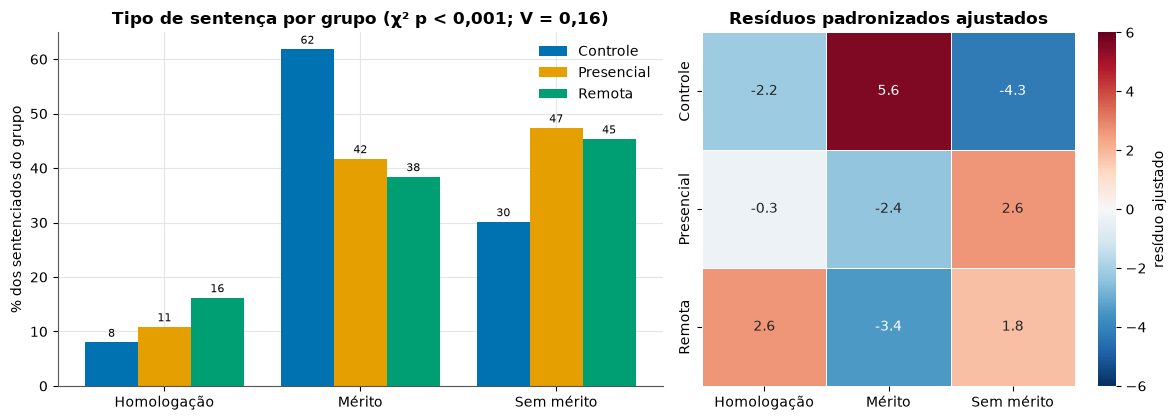

In [33]:
t3_sent = t3[t3['evento'] == 1].copy()
t3_sent['tipo'] = t3_sent['tipo_desfecho'].cat.remove_unused_categories()
t3_tab_tipo = pd.crosstab(t3_sent['grupo'], t3_sent['tipo'])
chi2, p_tipo, gl, esperadas = stats.chi2_contingency(t3_tab_tipo, correction=False)
v_tipo, v_lo, v_hi = tst_cramer_ic(t3_sent['grupo'], t3_sent['tipo'])
res_tipo = tst_residuos(t3_tab_tipo)

print('Frequências observadas:'); display(t3_tab_tipo.assign(Total=t3_tab_tipo.sum(axis=1)))
print('Percentual por grupo:'); display((100 * t3_tab_tipo.div(t3_tab_tipo.sum(axis=1), axis=0)).round(1))
print('Frequências esperadas sob H0 (mínimo = %s):' % fmt_br(esperadas.min(), 1))
display(pd.DataFrame(esperadas, index=t3_tab_tipo.index, columns=t3_tab_tipo.columns).round(1))
print(f'Qui-quadrado = {fmt_br(chi2, 2)}, gl = {gl}, p = {p_tipo:.2e} | V de Cramér = {tst_ic_txt(v_tipo, v_lo, v_hi, 3)}')
print('Resíduos padronizados ajustados:'); display(res_tipo.round(2))
tst_registra('3.2', 'H1 tipo × grupo', 'χ² tipo de sentença × grupo (sentenciados)', 'independência',
             f'χ²({gl}) = {fmt_br(chi2, 2)}', p_tipo, f'V = {tst_ic_txt(v_tipo, v_lo, v_hi, 3)}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={'width_ratios': [1.3, 1]})
perc = 100 * t3_tab_tipo.div(t3_tab_tipo.sum(axis=1), axis=0)
x = np.arange(len(perc.columns)); w = 0.27
for i, g in enumerate(ORDEM_GRUPO):
    barras = ax[0].bar(x + (i - 1) * w, perc.loc[g], w, color=CORES_GRUPO[g], label=g)
    ax[0].bar_label(barras, labels=[fmt_br(v, 0) for v in perc.loc[g]], fontsize=8, padding=2)
ax[0].set_xticks(x, perc.columns); ax[0].set_ylabel('% dos sentenciados do grupo')
ax[0].set_title(f'Tipo de sentença por grupo (χ² p {tst_eq(p_tipo)}; V = {fmt_br(v_tipo, 2)})'); ax[0].legend()
sns.heatmap(res_tipo, annot=True, fmt='.1f', cmap='RdBu_r', center=0, vmin=-6, vmax=6, ax=ax[1],
            cbar_kws={'label': 'resíduo ajustado'}, linewidths=0.5)
ax[1].set_title('Resíduos padronizados ajustados'); ax[1].set_xlabel(''); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

### 3.2.2 Comparações par a par (2 × 3) com Holm

O χ² global diz que *alguma* diferença existe; as tabelas 2 × 3 dizem **entre quais grupos**. São três comparações, ajustadas por Holm. A comparação Presencial × Remota responde se a modalidade da AC importa para o tipo de desfecho.

,Comparação,n,χ²,gl,p,V de Cramér,p Holm
0,Presencial × Controle,492,20.022,2,"< 0,001",0.202,"< 0,001"
1,Remota × Controle,478,26.835,2,"< 0,001",0.237,"< 0,001"
2,Presencial × Remota,446,2.759,2,"0,252",0.079,"0,252"


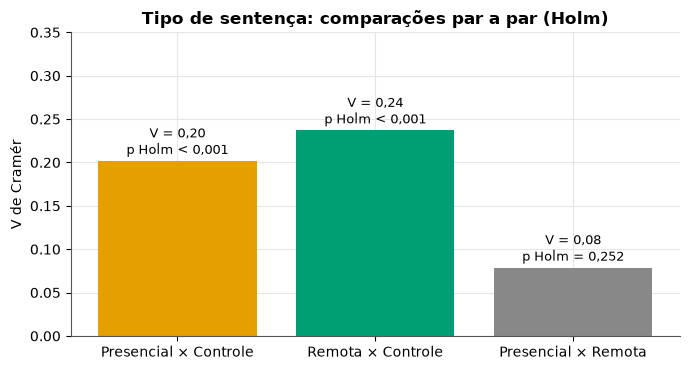

In [34]:
linhas = []
for a, b in PARES_GRUPO:
    sub = t3_sent[t3_sent['grupo'].isin([a, b])]
    tab = pd.crosstab(sub['grupo'].astype(str), sub['tipo'])
    c2, p, g, _ = stats.chi2_contingency(tab, correction=False)
    linhas.append({'Comparação': f'{a} × {b}', 'n': len(sub), 'χ²': c2, 'gl': g, 'p': p, 'V de Cramér': tst_cramer(tab)})
t3_pares_tipo = pd.DataFrame(linhas)
t3_pares_tipo['p Holm'] = tst_holm(t3_pares_tipo['p'])
tst_tabela_p(t3_pares_tipo, casas=3)
for _, r in t3_pares_tipo.iterrows():
    tst_registra('3.2', 'H1 pares', f'χ² 2×3 {r["Comparação"]}', 'mesma distribuição de tipos',
                 f'χ²({r["gl"]}) = {fmt_br(r["χ²"], 2)}', r['p'], f'V = {fmt_br(r["V de Cramér"], 3)}')

fig, ax = plt.subplots(figsize=(7, 3.8))
barras = ax.bar(t3_pares_tipo['Comparação'], t3_pares_tipo['V de Cramér'], color=['#E69F00', '#009E73', '#888888'])
ax.bar_label(barras, labels=[f'V = {fmt_br(v, 2)}\np Holm {tst_eq(p)}' for v, p in
                             zip(t3_pares_tipo['V de Cramér'], t3_pares_tipo['p Holm'])], fontsize=9, padding=2)
ax.set_ylabel('V de Cramér'); ax.set_ylim(0, max(0.35, t3_pares_tipo['V de Cramér'].max() * 1.4))
ax.set_title('Tipo de sentença: comparações par a par (Holm)')
plt.tight_layout(); plt.show()

### 3.2.3 Hipótese-chave: a AC obrigatória troca mérito por extinção sem mérito?

A Lei 9.099/1995 (art. 51, I) extingue o processo, sem resolução de mérito, quando o **autor deixa de comparecer a qualquer das audiências**. Num rito com AC inaugural obrigatória, cada ausência do autor vira extinção; no rito atual (Controle), sem audiência inaugural, o processo segue para contestação e julgamento. A hipótese substantiva, formulada antes do teste, é: **mais "sem mérito" e menos "mérito" nos braços com AC**.

Para cada tipo de sentença, testa-se o desfecho binário (o tipo × os demais) entre os grupos:

- **H₀:** a proporção do tipo é a mesma nos três grupos (χ² 3 × 2); depois, par a par, **Fisher exato** com **razão de chances (OR)** e IC 95% condicional exato, e a **diferença de proporções** com IC de Newcombe. Os nove pares formam uma família ajustada por Holm.
- **Leitura do gráfico:** proporção de cada tipo por grupo, com IC de Wilson.
- A homologação (acordo) aparece aqui por completude; ela é idêntica a "acordo em qualquer momento" entre os sentenciados e é discutida, numa janela sem censura, na seção 3.3.

Testes globais (3 × 2), Holm entre os três tipos:


,Tipo,χ²,gl,p,mín. esperada,V,p Holm
0,Sem mérito,18.312,2,"< 0,001",87.254,0.161,"< 0,001"
1,Mérito,31.612,2,"< 0,001",104.034,0.211,"< 0,001"
2,Homologação,7.945,2,"0,019",24.712,0.106,"0,019"


Pares (Fisher exato), Holm na família de nove:


,Tipo,Comparação,x/n (1º),x/n (2º),OR,OR IC inf,OR IC sup,Dif. (p.p.),Dif. IC inf,Dif. IC sup,p,p Holm
0,Sem mérito,Presencial × Controle,109/230,79/262,2.09,1.42,3.07,17.24,8.63,25.54,"< 0,001","< 0,001"
1,Sem mérito,Remota × Controle,98/216,79/262,1.92,1.30,2.85,15.22,6.50,23.69,"< 0,001","0,005"
2,Sem mérito,Presencial × Remota,109/230,98/216,1.08,0.73,1.60,2.02,-7.19,11.17,"0,704","0,999"
3,Mérito,Presencial × Controle,96/230,162/262,0.44,0.30,0.65,-20.09,-28.49,-11.27,"< 0,001","< 0,001"
4,Mérito,Remota × Controle,83/216,162/262,0.39,0.26,0.57,-23.41,-31.83,-14.45,"< 0,001","< 0,001"
5,Mérito,Presencial × Remota,96/230,83/216,1.15,0.77,1.71,3.31,-5.76,12.29,"0,500","0,999"
6,Homologação,Presencial × Controle,25/230,21/262,1.40,0.73,2.71,2.85,-2.34,8.27,"0,283","0,848"
7,Homologação,Remota × Controle,35/216,21/262,2.22,1.21,4.15,8.19,2.35,14.32,"0,007","0,033"
8,Homologação,Presencial × Remota,25/230,35/216,0.63,0.35,1.13,-5.33,-11.80,1.03,"0,126","0,505"


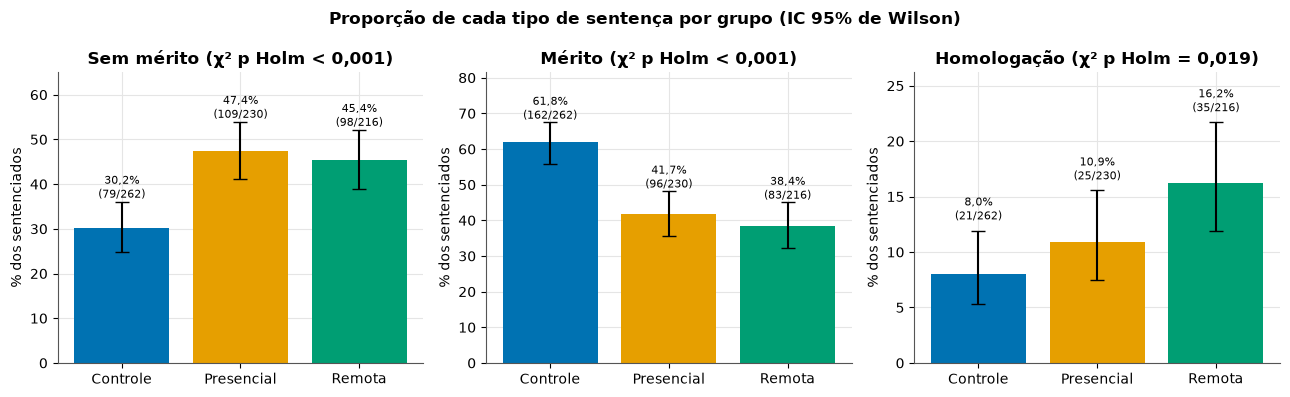

In [35]:
linhas_glob, linhas_par = [], []
for tipo in ['Sem mérito', 'Mérito', 'Homologação']:
    y = (t3_sent['tipo'] == tipo)
    tab = pd.crosstab(t3_sent['grupo'], y)
    c2, p, g, e = stats.chi2_contingency(tab, correction=False)
    linhas_glob.append({'Tipo': tipo, 'χ²': c2, 'gl': g, 'p': p, 'mín. esperada': e.min(), 'V': tst_cramer(tab)})
    for a, b in PARES_GRUPO:
        xa, na = int(y[t3_sent['grupo'] == a].sum()), int((t3_sent['grupo'] == a).sum())
        xb, nb = int(y[t3_sent['grupo'] == b].sum()), int((t3_sent['grupo'] == b).sum())
        pf, orm, orc, olo, ohi = tst_fisher([[xa, na - xa], [xb, nb - xb]])
        dif, dlo, dhi = tst_newcombe(xa, na, xb, nb)
        linhas_par.append({'Tipo': tipo, 'Comparação': f'{a} × {b}', f'% {a[:4]}.': 100 * xa / na,
                           'x/n (1º)': f'{xa}/{na}', 'x/n (2º)': f'{xb}/{nb}', 'OR': orm, 'OR IC inf': olo,
                           'OR IC sup': ohi, 'Dif. (p.p.)': 100 * dif, 'Dif. IC inf': 100 * dlo,
                           'Dif. IC sup': 100 * dhi, 'p': pf})
t3_glob_bin = pd.DataFrame(linhas_glob); t3_glob_bin['p Holm'] = tst_holm(t3_glob_bin['p'])
t3_par_bin = pd.DataFrame(linhas_par).drop(columns=[c for c in pd.DataFrame(linhas_par) if c.startswith('% ')])
t3_par_bin['p Holm'] = tst_holm(t3_par_bin['p'])
print('Testes globais (3 × 2), Holm entre os três tipos:'); tst_tabela_p(t3_glob_bin, casas=3)
print('Pares (Fisher exato), Holm na família de nove:'); tst_tabela_p(t3_par_bin, casas=2)
for _, r in t3_glob_bin.iterrows():
    tst_registra('3.2', 'H2 tipos binários', f'χ² 3×2 {r["Tipo"]} × grupo', 'proporção igual nos 3 grupos',
                 f'χ²(2) = {fmt_br(r["χ²"], 2)}', r['p'], f'V = {fmt_br(r["V"], 3)}')
for _, r in t3_par_bin.iterrows():
    tst_registra('3.2', 'H2 pares (Fisher)', f'Fisher {r["Tipo"]}: {r["Comparação"]}', 'OR = 1', f'OR = {fmt_br(r["OR"], 2)}',
                 r['p'], f'dif. = {tst_ic_txt(r["Dif. (p.p.)"], r["Dif. IC inf"], r["Dif. IC sup"], 1)} p.p.')

fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharey=False)
for k, tipo in enumerate(['Sem mérito', 'Mérito', 'Homologação']):
    for i, g in enumerate(ORDEM_GRUPO):
        sub = t3_sent[t3_sent['grupo'] == g]
        xg, ng = int((sub['tipo'] == tipo).sum()), len(sub)
        lo, hi = tst_wilson(xg, ng)
        ax[k].bar(i, 100 * xg / ng, color=CORES_GRUPO[g], yerr=[[100 * (xg / ng - lo)], [100 * (hi - xg / ng)]], capsize=5)
        ax[k].text(i, 100 * hi + 1, f'{fmt_br(100 * xg / ng, 1)}%\n({xg}/{ng})', ha='center', fontsize=8)
    pg = t3_glob_bin.loc[t3_glob_bin['Tipo'] == tipo, 'p Holm'].iloc[0]
    ax[k].set_xticks(range(3), ORDEM_GRUPO); ax[k].set_title(f'{tipo} (χ² p Holm {tst_eq(pg)})')
    ax[k].set_ylabel('% dos sentenciados'); ax[k].set_ylim(0, ax[k].get_ylim()[1] * 1.15)
plt.suptitle('Proporção de cada tipo de sentença por grupo (IC 95% de Wilson)', fontweight='bold')
plt.tight_layout(); plt.show()

**Mecanismo (descritivo, não é teste).** Nos braços com AC, cruza-se o tipo de sentença com a realização da AC. `ac_realizada` é uma variável **pós-sorteio** — ser ou não realizada depende do comportamento das partes —, por isso a tabela não estima efeito causal: apenas mostra *onde* estão as extinções sem mérito. Uma AC "não realizada" pode ser ausência do autor (art. 51, I) ou extinção anterior à data da audiência (desistência, indeferimento da inicial).

tipo                         Homologação  Mérito  Sem mérito  Total
grupo      AC                                                      
Presencial AC não realizada           11       2          89    102
           AC realizada               14      94          20    128
Remota     AC não realizada           16       2          63     81
           AC realizada               19      81          35    135

tipo                         Homologação  Mérito  Sem mérito
grupo      AC                                               
Presencial AC não realizada         10.8     2.0        87.3
           AC realizada             10.9    73.4        15.6
Remota     AC não realizada         19.8     2.5        77.8
           AC realizada             14.1    60.0        25.9

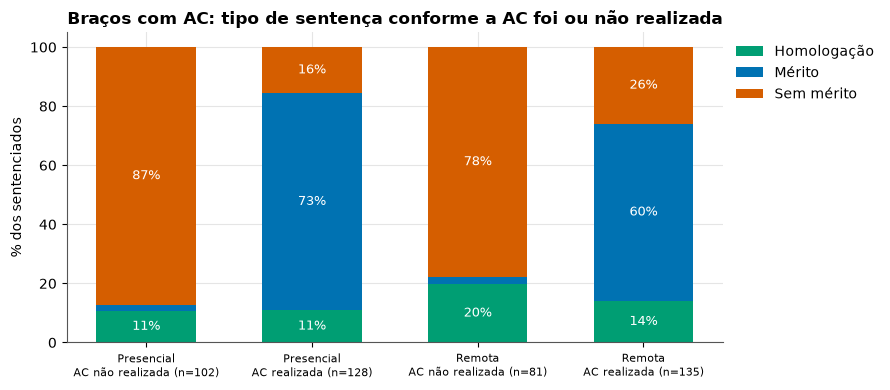

In [36]:
trat = t3_sent[t3_sent['grupo'] != 'Controle'].copy()
trat['AC'] = trat['ac_realizada'].map({True: 'AC realizada', False: 'AC não realizada'}).fillna('não informado')
t3_mec = pd.crosstab([trat['grupo'].astype(str), trat['AC']], trat['tipo'])
display(t3_mec.assign(Total=t3_mec.sum(axis=1)))
display((100 * t3_mec.div(t3_mec.sum(axis=1), axis=0)).round(1))

fig, ax = plt.subplots(figsize=(9, 4))
perc = 100 * t3_mec.div(t3_mec.sum(axis=1), axis=0)
rot = [f'{g}\n{a} (n={int(t3_mec.loc[(g, a)].sum())})' for g, a in perc.index]
base = np.zeros(len(perc))
for tipo in perc.columns:
    ax.bar(range(len(perc)), perc[tipo], bottom=base, color=CORES_DESFECHO[tipo], label=tipo, width=0.6)
    for i, v in enumerate(perc[tipo]):
        if v > 6:
            ax.text(i, base[i] + v / 2, fmt_br(v, 0) + '%', ha='center', va='center', color='white', fontsize=9)
    base += perc[tipo].values
ax.set_xticks(range(len(perc)), rot, fontsize=8); ax.set_ylabel('% dos sentenciados')
ax.set_title('Braços com AC: tipo de sentença conforme a AC foi ou não realizada'); ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

### 3.2.4 Redistribuição (Decisão) × grupo

A redistribuição (remessa a outro juízo por prevenção ou incompetência) não é sentença, mas pode depender do rito: uma AC obrigatória dá mais uma oportunidade de alguém perceber a prevenção. A base são os **938 processos** (a redistribuição costuma ocorrer nos primeiros dias, de modo que a censura pouco a afeta).

- **H₀:** a proporção de redistribuições é igual nos três grupos. Com 24 eventos, as esperadas ficam em torno de 8, e o χ² assintótico é conferido pela **permutação de Monte Carlo** (10.000 reamostragens).

tipo_desfecho  Não  Redistribuição
grupo                             
Controle       308               5
Presencial     304              10
Remota         302               9
Esperadas mínimas = 8,0 | χ²(2) = 1,79, p assintótico = 0,408, p permutação (χ²) = 0,423, p Fisher-Freeman-Halton MC = 0,393 | V = 0,044


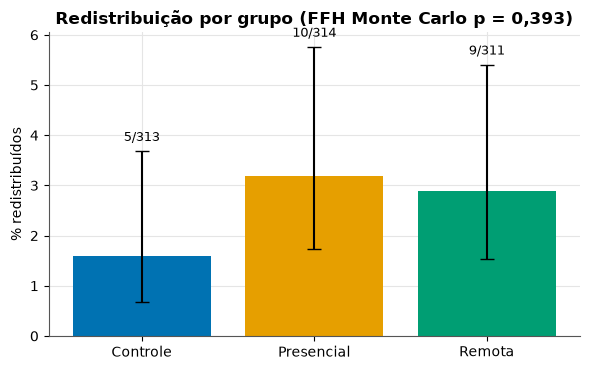

In [37]:
y_red = (t3['tipo_desfecho'] == 'Redistribuição')
tab_red = pd.crosstab(t3['grupo'], y_red)
c2_red, p_red, _, e_red = stats.chi2_contingency(tab_red, correction=False)
_, p_red_mc, p_red_ffh, _ = tst_perm_rxc(t3['grupo'], y_red)
print(tab_red.rename(columns={False: 'Não', True: 'Redistribuição'}))
print(f'Esperadas mínimas = {fmt_br(e_red.min(), 1)} | χ²(2) = {fmt_br(c2_red, 2)}, p assintótico {tst_eq(p_red)}, '
      f'p permutação (χ²) {tst_eq(p_red_mc)}, p Fisher-Freeman-Halton MC {tst_eq(p_red_ffh)} | V = {fmt_br(tst_cramer(tab_red), 3)}')
tst_registra('3.2', 'H3 redistribuição', 'Redistribuição × grupo (FFH Monte Carlo)', 'proporção igual',
             f'χ²(2) = {fmt_br(c2_red, 2)}', p_red_ffh, f'V = {fmt_br(tst_cramer(tab_red), 3)}')

fig, ax = plt.subplots(figsize=(6, 3.8))
for i, g in enumerate(ORDEM_GRUPO):
    xg, ng = int(tab_red.loc[g, True]), int(tab_red.loc[g].sum())
    lo, hi = tst_wilson(xg, ng)
    ax.bar(i, 100 * xg / ng, color=CORES_GRUPO[g], yerr=[[100 * (xg / ng - lo)], [100 * (hi - xg / ng)]], capsize=5)
    ax.text(i, 100 * hi + 0.2, f'{xg}/{ng}', ha='center', fontsize=9)
ax.set_xticks(range(3), ORDEM_GRUPO); ax.set_ylabel('% redistribuídos')
ax.set_title(f'Redistribuição por grupo (FFH Monte Carlo p {tst_eq(p_red_ffh)})')
plt.tight_layout(); plt.show()

### 3.2.5 Sensibilidade sem censura: desfecho até o 65º dia

Todo processo tem no mínimo 65 dias de acompanhamento. Logo, a variável "**como o processo estava no 65º dia**" (homologação, mérito, sem mérito, redistribuído ou ainda sem desfecho) é observada **para os 938**, sem censura e sem condicionar a quem já encerrou. É a forma correta de usar um χ² de "status" (o notebook do professor usou o status na data de corte, que mistura seguimentos de 65 a 279 dias — E19).

- **H₀:** a situação no 65º dia é independente do grupo.

sit65,Homologação,Mérito,Sem mérito,Redistribuição,Sem desfecho até 65 d,Total
grupo,,,,,,
Controle,11,35,65,5,197,313
Presencial,14,5,90,10,195,314
Remota,19,2,64,7,219,311


Esperada mínima = 7,3 | χ²(8) = 59,19, p < 0,001 | V = 0,178 [0,145; 0,228]
Resíduos ajustados:


sit65,Homologação,Mérito,Sem mérito,Redistribuição,Sem desfecho até 65 d
grupo,,,,,
Controle,-1.21,7.03,-1.32,-1.07,-1.00
Presencial,-0.24,-3.03,2.73,1.20,-1.38
Remota,1.45,-4.00,-1.41,-0.13,2.39


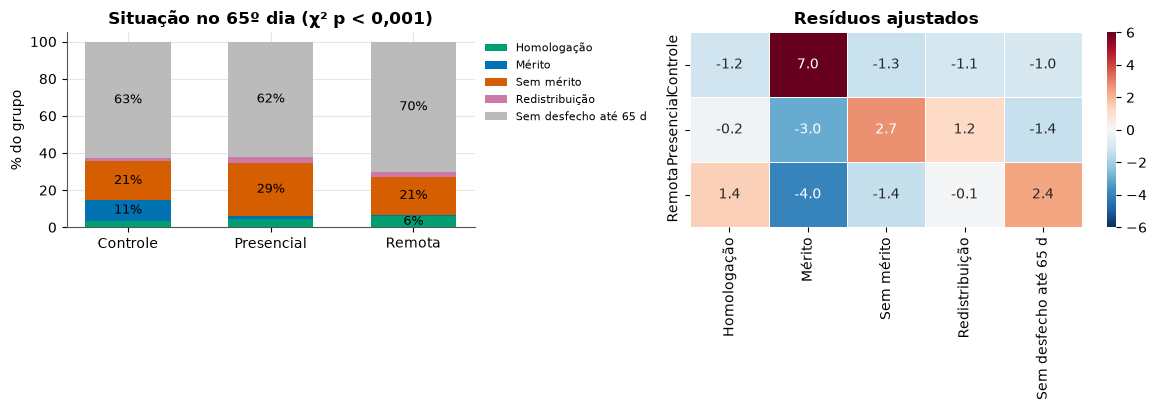

In [38]:
t3['sit65'] = np.where(t3['tempo_f'] <= 65, t3['tipo_desfecho'].astype(str), 'Sem desfecho até 65 d')
t3['sit65'] = np.where((t3['sit65'] == 'Ativo'), 'Sem desfecho até 65 d', t3['sit65'])
ORDEM_SIT65 = ['Homologação', 'Mérito', 'Sem mérito', 'Redistribuição', 'Sem desfecho até 65 d']
tab65 = pd.crosstab(t3['grupo'], t3['sit65'])[ORDEM_SIT65]
c2_65, p_65, gl_65, e_65 = stats.chi2_contingency(tab65, correction=False)
v65, v65lo, v65hi = tst_cramer_ic(t3['grupo'], t3['sit65'])
display(tab65.assign(Total=tab65.sum(axis=1)))
print(f'Esperada mínima = {fmt_br(e_65.min(), 1)} | χ²({gl_65}) = {fmt_br(c2_65, 2)}, p {tst_eq(p_65)} | V = {tst_ic_txt(v65, v65lo, v65hi, 3)}')
print('Resíduos ajustados:'); display(tst_residuos(tab65).round(2))
tst_registra('3.2', 'H1 tipo × grupo', 'χ² situação no 65º dia × grupo (938, sem censura)', 'independência',
             f'χ²({gl_65}) = {fmt_br(c2_65, 2)}', p_65, f'V = {tst_ic_txt(v65, v65lo, v65hi, 3)}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1, 1.2]})
perc = 100 * tab65.div(tab65.sum(axis=1), axis=0)
cores65 = {**CORES_DESFECHO, 'Sem desfecho até 65 d': '#BBBBBB'}
base = np.zeros(3)
for s in ORDEM_SIT65:
    ax[0].bar(range(3), perc[s], bottom=base, color=cores65[s], label=s, width=0.6)
    for i, v in enumerate(perc[s]):
        if v > 5:
            ax[0].text(i, base[i] + v / 2, fmt_br(v, 0) + '%', ha='center', va='center', fontsize=9)
    base += perc[s].values
ax[0].set_xticks(range(3), ORDEM_GRUPO); ax[0].set_ylabel('% do grupo')
ax[0].set_title(f'Situação no 65º dia (χ² p {tst_eq(p_65)})'); ax[0].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
sns.heatmap(tst_residuos(tab65), annot=True, fmt='.1f', cmap='RdBu_r', center=0, vmin=-6, vmax=6, ax=ax[1], linewidths=0.5)
ax[1].set_title('Resíduos ajustados'); ax[1].set_xlabel(''); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

**Leitura. O rito muda o tipo de sentença, e a mudança tem uma explicação jurídica clara.**

- **Há associação entre tipo de sentença e grupo** (χ²(4) = 34,34; p < 0,001; esperadas ≥ 24,7). O efeito é **pequeno a moderado**: V de Cramér = 0,16 (IC 95% 0,11 a 0,21).
- **A diferença está entre o Controle e os braços com AC, e não entre as duas modalidades:**
  - Presencial × Controle: V = 0,20, p Holm < 0,001;
  - Remota × Controle: V = 0,24, p Holm < 0,001;
  - Presencial × Remota: V = 0,08, p = 0,252.

  Para o tipo de desfecho, **"ter AC obrigatória" importa; a modalidade, não**.
- **A hipótese do art. 51, I, da Lei 9.099/1995 é confirmada nos dados.** Entre os sentenciados:
  - **sem mérito:** 30,2% no Controle, contra 47,4% no Presencial e 45,4% na Remota. Presencial × Controle: OR = 2,09 (IC 1,42 a 3,07), diferença de +17,2 p.p. (IC de Newcombe 8,6 a 25,5). Remota × Controle: OR = 1,92 (1,30 a 2,85), +15,2 p.p. (6,5 a 23,7). Ambos com p Holm ≤ 0,005;
  - **mérito:** 61,8% no Controle, contra 41,7% e 38,4%. OR de 0,44 e 0,39, diferenças de −20 e −23 p.p., p Holm < 0,001;
  - os resíduos ajustados apontam as mesmas células: Controle × mérito = +5,6; Controle × sem mérito = −4,3.
- **O mecanismo aparece na tabela descritiva.** Nos braços com AC, quando a audiência **não** foi realizada, 87% (Presencial) e 78% (Remota) das sentenças são **sem mérito**. Quando foi realizada, predominam as de mérito (73% e 60%). A leitura compatível é que a AC obrigatória cria um ponto de "filtragem": o autor que não comparece tem o processo extinto (art. 51, I). Como `ac_realizada` é pós-sorteio, essa tabela mostra **onde** estão as extinções, não prova a causa; parte das AC "não realizadas" pode ser de processos extintos antes da data da audiência.
- **Homologação (acordo).** O global é significativo dentro da família (p Holm = 0,019), e o único par que se sustenta é **Remota × Controle**: 16,2% contra 8,0%, OR = 2,22 (1,21 a 4,15), p Holm = 0,033. Esse par não sobrevive ao Holm global (seção 3.7) e é discutido em horizonte fixo na seção 3.3.
- **A redistribuição não depende do rito**: 5, 10 e 9 casos; Fisher-Freeman-Halton por Monte Carlo, p = 0,393.
- **A conclusão não é um artefato de "quem já encerrou".** Na janela de 65 dias, observada para os 938 processos, a associação persiste e é até mais forte: χ²(8) = 59,19, p < 0,001, V = 0,18 (0,15 a 0,23).
  - **Mérito até o 65º dia:** 35 processos no Controle, contra 5 no Presencial e 2 na Remota (resíduo +7,0). Sem AC inaugural, o Controle consegue julgar o mérito cedo, provavelmente por julgamento antecipado após a contestação.
  - **Sem mérito precoce** se concentra no Presencial (resíduo +2,7).
  - **"Sem desfecho até 65 dias"** se concentra na Remota (+2,4).
- **Leitura jurídica.** A AC obrigatória não se limita a "acrescentar acordos": ela **troca julgamentos de mérito por extinções sem mérito**. Para a política judiciária, isso tem custo. Uma extinção por ausência não resolve o conflito, e o autor pode repropor a ação (art. 51, § 1º). O indicador "processos baixados" melhora sem que a resposta ao jurisdicionado melhore na mesma proporção.

---

## 3.3 Acordo (H4 a H7)

### 3.3.1 Acordo na AC: presencial × remota (H4)

Só há acordo na AC onde houve AC. A comparação válida é **Presencial × Remota entre as AC realizadas** (o χ² do professor incluía o Controle, com zero estrutural — E20).

- **H₀:** p(acordo na AC | AC presencial) = p(acordo na AC | AC remota). **H₁:** bilateral.
- **Teste:** exato de Fisher (17 acordos ao todo: esperadas abaixo de 10, fora do alcance seguro do χ²). Efeitos: OR (IC condicional exato) e diferença de proporções (IC de Newcombe).
- **Poder:** com ~175 audiências por braço, calcula-se a menor diferença detectável com 80% de poder a partir da taxa observada — para dizer se um "não significativo" é informativo.

acordo_ac,Acordo na AC,Sem acordo
grupo,,
Presencial,9,169
Remota,8,166


Presencial 5,1% × Remota 4,6% | Fisher p = 1,000
OR = 1,11 (condicional 1,10; IC 95% exato 0,37 a 3,38)
Diferença = 0,5 p.p. (IC 95% Newcombe -4,4 a 5,3 p.p.)
Com taxa-base de 4,8% e esses n, só uma diferença ≥ 8,4 p.p. teria 80% de poder (α = 5%).


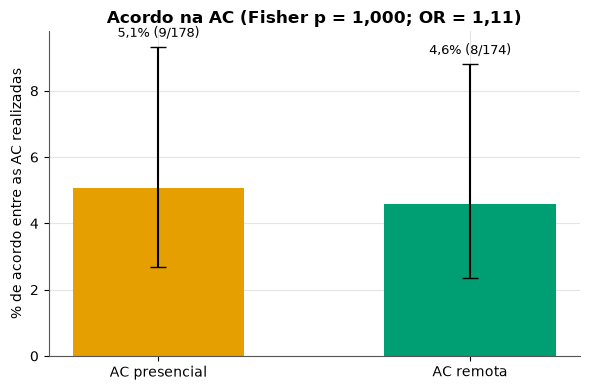

In [39]:
t3_ac = t3[t3['ac_realizada'].fillna(False).astype(bool) & (t3['grupo'] != 'Controle')].copy()
t3_ac['grupo'] = t3_ac['grupo'].cat.remove_unused_categories()
tab_acac = pd.crosstab(t3_ac['grupo'], t3_ac['acordo_ac'].fillna(False).astype(bool)).reindex(columns=[True, False], fill_value=0)
xp, xr = int(tab_acac.loc['Presencial', True]), int(tab_acac.loc['Remota', True])
np_, nr = int(tab_acac.loc['Presencial'].sum()), int(tab_acac.loc['Remota'].sum())
p_acac, or_acac, orc_acac, or_lo, or_hi = tst_fisher(tab_acac.values)
dif_acac, dlo_acac, dhi_acac = tst_newcombe(xp, np_, xr, nr)
display(tab_acac.rename(columns={True: 'Acordo na AC', False: 'Sem acordo'}))
print(f'Presencial {fmt_br(100 * xp / np_, 1)}% × Remota {fmt_br(100 * xr / nr, 1)}% | Fisher p {tst_eq(p_acac)}')
print(f'OR = {fmt_br(or_acac, 2)} (condicional {fmt_br(orc_acac, 2)}; IC 95% exato {fmt_br(or_lo, 2)} a {fmt_br(or_hi, 2)})')
print(f'Diferença = {fmt_br(100 * dif_acac, 1)} p.p. (IC 95% Newcombe {fmt_br(100 * dlo_acac, 1)} a {fmt_br(100 * dhi_acac, 1)} p.p.)')
p_base = (xp + xr) / (np_ + nr)
for alvo in np.arange(0.005, 0.30, 0.001):
    poder = NormalIndPower().power(proportion_effectsize(p_base + alvo, p_base), nobs1=np_, ratio=nr / np_, alpha=0.05)
    if poder >= 0.8:
        break
print(f'Com taxa-base de {pct_br(p_base)} e esses n, só uma diferença ≥ {fmt_br(100 * alvo, 1)} p.p. teria 80% de poder (α = 5%).')
tst_registra('3.3', 'H4 acordo AC modalidade', 'Fisher acordo na AC: Presencial × Remota', 'OR = 1', f'OR = {fmt_br(or_acac, 2)}',
             p_acac, f'dif. = {tst_ic_txt(100 * dif_acac, 100 * dlo_acac, 100 * dhi_acac, 1)} p.p.')

fig, ax = plt.subplots(figsize=(6, 4))
for i, (g, xg, ng) in enumerate([('Presencial', xp, np_), ('Remota', xr, nr)]):
    lo, hi = tst_wilson(xg, ng)
    ax.bar(i, 100 * xg / ng, color=CORES_GRUPO[g], yerr=[[100 * (xg / ng - lo)], [100 * (hi - xg / ng)]], capsize=6, width=0.55)
    ax.text(i, 100 * hi + 0.3, f'{fmt_br(100 * xg / ng, 1)}% ({xg}/{ng})', ha='center', fontsize=9)
ax.set_xticks([0, 1], ['AC presencial', 'AC remota']); ax.set_ylabel('% de acordo entre as AC realizadas')
ax.set_title(f'Acordo na AC (Fisher p {tst_eq(p_acac)}; OR = {fmt_br(or_acac, 2)})')
plt.tight_layout(); plt.show()

### 3.3.2 Acordo em qualquer momento (H5)

"Acordo" (na AC ou fora dela) existe nos três grupos, inclusive no Controle (por petição). Entre os sentenciados, acordo é exatamente a **homologação**, já testada em 3.2.3; aquela comparação, porém, é condicional a quem encerrou. Aqui o acordo é medido **em horizonte fixo**, sem censura:

- **Janela de 65 dias:** homologação até o 65º dia, para os 938 processos (todos acompanhados por ≥ 65 dias);
- **Janela de 120 dias:** homologação até o 120º dia, só entre os processos com ≥ 120 dias de acompanhamento (distribuídos até 09/06/2026).

**H₀:** a proporção de acordos até o horizonte é igual nos três grupos. χ² 3 × 2 (ou permutação, se esparso) e Fisher par a par com Holm.

Horizonte 65 dias (n = 938): acordos {'Controle': 11, 'Presencial': 14, 'Remota': 19} | esperada mín. 14,6 | χ²(2) = 2,41, p = 0,300, p permutação = 0,300


Horizonte 120 dias (n = 688): acordos {'Controle': 12, 'Presencial': 22, 'Remota': 27} | esperada mín. 19,2 | χ²(2) = 8,00, p = 0,018, p permutação = 0,018


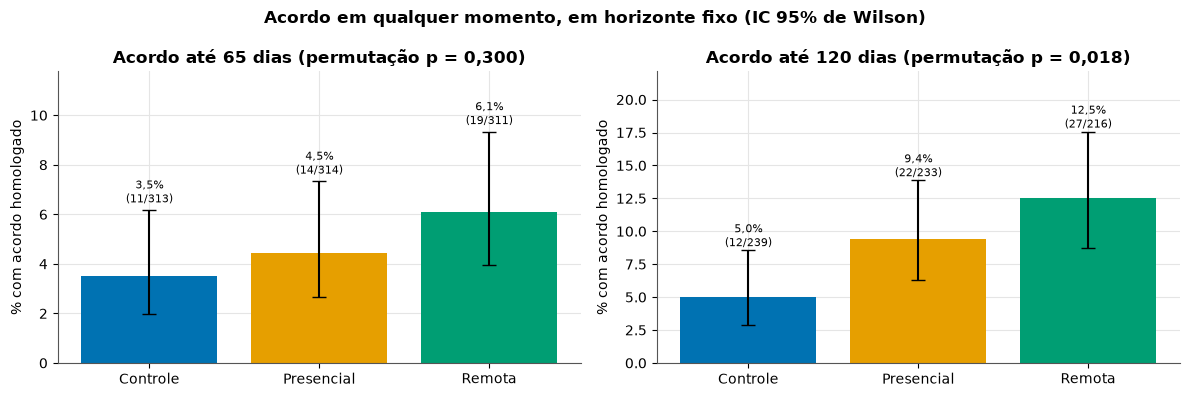

,Horizonte,Comparação,1º,2º,OR,OR IC,Dif. p.p. [IC Newcombe],p,p Holm
0,65,Presencial × Controle,14/314,11/313,1.28,"0,53 a 3,17","0,9 [-2,3; 4,2]","0,684","0,753"
1,65,Remota × Controle,19/311,11/313,1.79,"0,79 a 4,23","2,6 [-0,8; 6,2]","0,139","0,416"
2,65,Presencial × Remota,14/314,19/311,0.72,"0,33 a 1,54","-1,7 [-5,3; 2,0]","0,377","0,753"
3,120,Presencial × Controle,22/233,12/239,1.97,"0,91 a 4,48","4,4 [-0,3; 9,3]","0,075","0,150"
4,120,Remota × Controle,27/216,12/239,2.70,"1,28 a 6,01","7,5 [2,3; 13,0]","0,007","0,020"
5,120,Presencial × Remota,22/233,27/216,0.73,"0,38 a 1,38","-3,1 [-9,0; 2,8]","0,364","0,364"


In [40]:
linhas = []
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, h in enumerate([65, 120]):
    base_h = t3[t3['followup'] >= h]
    y = (base_h['tipo_desfecho'] == 'Homologação') & (base_h['tempo_f'] <= h)
    tab = pd.crosstab(base_h['grupo'], y)
    c2, p, _, e = stats.chi2_contingency(tab, correction=False)
    _, p_mc, _, _ = tst_perm_rxc(base_h['grupo'], y)
    print(f'Horizonte {h} dias (n = {len(base_h)}): acordos {tab[True].to_dict()} | esperada mín. {fmt_br(e.min(), 1)} | '
          f'χ²(2) = {fmt_br(c2, 2)}, p {tst_eq(p)}, p permutação {tst_eq(p_mc)}')
    tst_registra('3.3', 'H5 acordo total', f'χ² acordo até {h} d × grupo', 'proporção igual', f'χ²(2) = {fmt_br(c2, 2)}', p_mc,
                 f'V = {fmt_br(tst_cramer(tab), 3)}')
    for a, b in PARES_GRUPO:
        xa, na = int(y[base_h['grupo'] == a].sum()), int((base_h['grupo'] == a).sum())
        xb, nb = int(y[base_h['grupo'] == b].sum()), int((base_h['grupo'] == b).sum())
        pf, orm, _, olo, ohi = tst_fisher([[xa, na - xa], [xb, nb - xb]])
        dif, dlo, dhi = tst_newcombe(xa, na, xb, nb)
        linhas.append({'Horizonte': h, 'Comparação': f'{a} × {b}', '1º': f'{xa}/{na}', '2º': f'{xb}/{nb}', 'OR': orm,
                       'OR IC': f'{fmt_br(olo, 2)} a {fmt_br(ohi, 2)}', 'Dif. p.p. [IC Newcombe]':
                       tst_ic_txt(100 * dif, 100 * dlo, 100 * dhi, 1), 'p': pf})
    for i, g in enumerate(ORDEM_GRUPO):
        xg, ng = int(tab.loc[g, True]) if True in tab else 0, int(tab.loc[g].sum())
        lo, hi = tst_wilson(xg, ng)
        ax[k].bar(i, 100 * xg / ng, color=CORES_GRUPO[g], yerr=[[100 * (xg / ng - lo)], [100 * (hi - xg / ng)]], capsize=5)
        ax[k].text(i, 100 * hi + 0.3, f'{fmt_br(100 * xg / ng, 1)}%\n({xg}/{ng})', ha='center', fontsize=8)
    ax[k].set_xticks(range(3), ORDEM_GRUPO); ax[k].set_ylabel('% com acordo homologado')
    ax[k].set_title(f'Acordo até {h} dias (permutação p {tst_eq(p_mc)})'); ax[k].set_ylim(0, ax[k].get_ylim()[1] * 1.2)
plt.suptitle('Acordo em qualquer momento, em horizonte fixo (IC 95% de Wilson)', fontweight='bold')
plt.tight_layout(); plt.show()
t3_acordo_pares = pd.DataFrame(linhas)
t3_acordo_pares['p Holm'] = np.concatenate([tst_holm(t3_acordo_pares.loc[t3_acordo_pares['Horizonte'] == h, 'p']) for h in [65, 120]])
tst_tabela_p(t3_acordo_pares, casas=2)
for _, r in t3_acordo_pares.iterrows():
    tst_registra('3.3', 'H5 pares', f'Fisher acordo até {r["Horizonte"]} d: {r["Comparação"]}', 'OR = 1',
                 f'OR = {fmt_br(r["OR"], 2)}', r['p'], f'dif. = {r["Dif. p.p. [IC Newcombe]"]} p.p.')

### 3.3.3 Acordo fora da AC × grupo (H6)

Acordo por petição das partes, fora da audiência. A base são os 733 processos com a informação registrada (os ativos ainda não a têm). Atenção à leitura: no Controle esse é o **único** caminho de acordo; nos braços com AC, é o acordo que veio **depois** de uma AC sem acordo, ou sem AC realizada.

- **H₀:** a proporção de acordo fora da AC é igual nos três grupos.

acordo_fora,Não,Acordo fora
grupo,,
Controle,246,21
Presencial,224,16
Remota,199,27


Esperada mín. = 19,7 | χ²(2) = 4,47, p = 0,107 | V = 0,078


,Comparação,OR,OR IC,Dif. p.p. [IC],p,p Holm
0,Presencial × Controle,0.84,"0,40 a 1,73","-1,2 [-5,8; 3,5]","0,733","0,733"
1,Remota × Controle,1.59,"0,84 a 3,05","4,1 [-1,2; 9,6]","0,131","0,262"
2,Presencial × Remota,0.53,"0,26 a 1,05","-5,3 [-10,8; 0,0]","0,055","0,166"


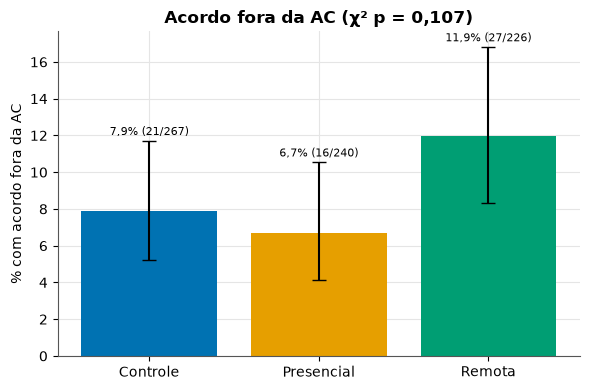

In [41]:
base_f = t3[t3['acordo_fora'].notna()]
y_f = base_f['acordo_fora'].astype(bool)
tab_f = pd.crosstab(base_f['grupo'], y_f)
c2_f, p_f, _, e_f = stats.chi2_contingency(tab_f, correction=False)
display(tab_f.rename(columns={True: 'Acordo fora', False: 'Não'}))
print(f'Esperada mín. = {fmt_br(e_f.min(), 1)} | χ²(2) = {fmt_br(c2_f, 2)}, p {tst_eq(p_f)} | V = {fmt_br(tst_cramer(tab_f), 3)}')
tst_registra('3.3', 'H6 acordo fora', 'χ² acordo fora da AC × grupo', 'proporção igual', f'χ²(2) = {fmt_br(c2_f, 2)}', p_f,
             f'V = {fmt_br(tst_cramer(tab_f), 3)}')
linhas = []
for a, b in PARES_GRUPO:
    xa, na = int(tab_f.loc[a, True]), int(tab_f.loc[a].sum()); xb, nb = int(tab_f.loc[b, True]), int(tab_f.loc[b].sum())
    pf, orm, _, olo, ohi = tst_fisher([[xa, na - xa], [xb, nb - xb]])
    dif, dlo, dhi = tst_newcombe(xa, na, xb, nb)
    linhas.append({'Comparação': f'{a} × {b}', 'OR': orm, 'OR IC': f'{fmt_br(olo, 2)} a {fmt_br(ohi, 2)}',
                   'Dif. p.p. [IC]': tst_ic_txt(100 * dif, 100 * dlo, 100 * dhi, 1), 'p': pf})
t3_fora_pares = pd.DataFrame(linhas); t3_fora_pares['p Holm'] = tst_holm(t3_fora_pares['p'])
tst_tabela_p(t3_fora_pares, casas=2)
for _, r in t3_fora_pares.iterrows():
    tst_registra('3.3', 'H6 pares', f'Fisher acordo fora: {r["Comparação"]}', 'OR = 1', f'OR = {fmt_br(r["OR"], 2)}', r['p'],
                 f'dif. = {r["Dif. p.p. [IC]"]} p.p.')

fig, ax = plt.subplots(figsize=(6, 4))
for i, g in enumerate(ORDEM_GRUPO):
    xg, ng = int(tab_f.loc[g, True]), int(tab_f.loc[g].sum())
    lo, hi = tst_wilson(xg, ng)
    ax.bar(i, 100 * xg / ng, color=CORES_GRUPO[g], yerr=[[100 * (xg / ng - lo)], [100 * (hi - xg / ng)]], capsize=5)
    ax.text(i, 100 * hi + 0.3, f'{fmt_br(100 * xg / ng, 1)}% ({xg}/{ng})', ha='center', fontsize=8)
ax.set_xticks(range(3), ORDEM_GRUPO); ax.set_ylabel('% com acordo fora da AC')
ax.set_title(f'Acordo fora da AC (χ² p {tst_eq(p_f)})')
plt.tight_layout(); plt.show()

### 3.3.4 AC híbrida e técnica de conciliação (H7)

**Híbrida.** Dentro do braço Presencial, uma AC é "híbrida" quando uma das partes pediu para participar por vídeo (Res. CNJ 481). É uma característica **pós-sorteio** (escolha da parte), portanto a comparação é observacional. **H₀:** p(acordo na AC) igual entre AC híbridas e totalmente presenciais (Fisher exato).

**Técnica.** A técnica foi sorteada entre as AC realizadas (Presencial e Remota). São 6 técnicas e 17 acordos: tabela 6 × 2 muito esparsa (esperadas < 3 em todas as células "acordo"). O χ² assintótico não vale; usa-se a **permutação de Monte Carlo** com margens fixas, com a estatística χ² e com a probabilidade da tabela (Fisher-Freeman-Halton). **H₀:** a probabilidade de acordo na AC é a mesma para as seis técnicas. Com tão poucos eventos, o poder é baixíssimo: um "não significativo" aqui **não** mostra que as técnicas são equivalentes.

acordo_ac,Acordo na AC,Sem acordo
hibrida,,
Híbrida,1,23
Presencial pura,8,146


Fisher p = 1,000 | OR = 0,79 (IC exato 0,02 a 6,41)


acordo_ac,Sem acordo,Acordo,% acordo
tecnica_curta,,,
Desconstrução,45,2,4.3
Parafraseamento,51,6,10.5
Separação,55,5,8.3
Padrões objetivos,65,2,3.0
Afago,58,0,0.0
Comunicação,61,2,3.2


Esperadas da coluna "acordo": [2.3 2.8 2.9 3.2 2.8 3. ] | χ² = 9,48; p permutação (χ²) = 0,088; p Fisher-Freeman-Halton MC = 0,080 (20.000 permutações)
p assintótico (só para comparar, inválido aqui) = 0,092


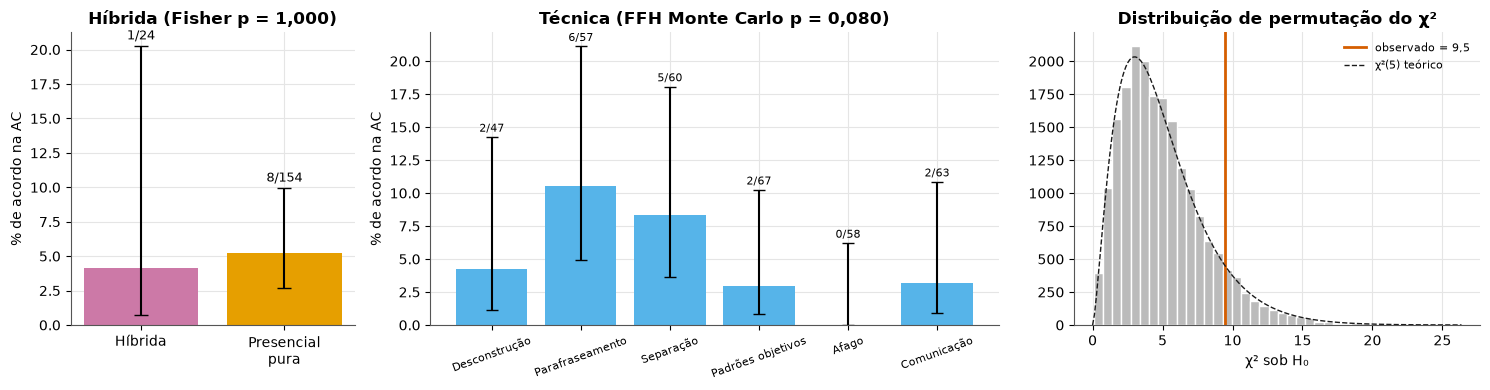

In [42]:
pres = t3_ac[t3_ac['grupo'] == 'Presencial']
pres = pres[pres['hibrida'].notna()]
tab_h = pd.crosstab(pres['hibrida'].astype(bool), pres['acordo_ac'].fillna(False).astype(bool)).reindex(index=[True, False], columns=[True, False], fill_value=0)
p_h, or_h, _, orh_lo, orh_hi = tst_fisher(tab_h.values)
display(tab_h.rename(index={True: 'Híbrida', False: 'Presencial pura'}, columns={True: 'Acordo na AC', False: 'Sem acordo'}))
print(f'Fisher p {tst_eq(p_h)} | OR = {fmt_br(or_h, 2)} (IC exato {fmt_br(orh_lo, 2)} a {fmt_br(orh_hi, 2)})')
tst_registra('3.3', 'H7 híbrida/técnica', 'Fisher híbrida × acordo na AC (Presencial)', 'OR = 1', f'OR = {fmt_br(or_h, 2)}', p_h,
             f'OR IC {fmt_br(orh_lo, 2)} a {fmt_br(orh_hi, 2)}')

tec = t3_ac[t3_ac['tecnica_curta'].notna()].copy()
tec['tecnica_curta'] = tec['tecnica_curta'].cat.remove_unused_categories()
y_tec = tec['acordo_ac'].fillna(False).astype(bool)
tab_tec = pd.crosstab(tec['tecnica_curta'], y_tec)
chi_tec, p_tec_chi, p_tec_ffh, chi_null = tst_perm_rxc(tec['tecnica_curta'], y_tec, B=20000)
e_tec = stats.contingency.expected_freq(tab_tec.values)
display(tab_tec.rename(columns={True: 'Acordo', False: 'Sem acordo'}).assign(**{'% acordo': (100 * tab_tec[True] / tab_tec.sum(axis=1)).round(1)}))
print(f'Esperadas da coluna "acordo": {np.round(e_tec[:, 1], 1)} | χ² = {fmt_br(chi_tec, 2)}; '
      f'p permutação (χ²) {tst_eq(p_tec_chi)}; p Fisher-Freeman-Halton MC {tst_eq(p_tec_ffh)} (20.000 permutações)')
print(f'p assintótico (só para comparar, inválido aqui) {tst_eq(stats.chi2.sf(chi_tec, (tab_tec.shape[0] - 1)))}')
tst_registra('3.3', 'H7 híbrida/técnica', 'Técnica × acordo na AC (FFH Monte Carlo)', 'acordo independente da técnica',
             f'χ²(5) = {fmt_br(chi_tec, 2)}', p_tec_ffh, f'V = {fmt_br(tst_cramer(tab_tec), 3)}')

fig, ax = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={'width_ratios': [0.7, 1.4, 1]})
for i, (rot, lin) in enumerate([('Híbrida', True), ('Presencial pura', False)]):
    xg, ng = int(tab_h.loc[lin, True]), int(tab_h.loc[lin].sum())
    lo, hi = tst_wilson(xg, ng)
    ax[0].bar(i, 100 * xg / ng, color=['#CC79A7', '#E69F00'][i], yerr=[[100 * (xg / ng - lo)], [100 * (hi - xg / ng)]], capsize=5)
    ax[0].text(i, 100 * hi + 0.5, f'{xg}/{ng}', ha='center', fontsize=9)
ax[0].set_xticks([0, 1], ['Híbrida', 'Presencial\npura']); ax[0].set_ylabel('% de acordo na AC')
ax[0].set_title(f'Híbrida (Fisher p {tst_eq(p_h)})')
for i, t in enumerate(tab_tec.index):
    xg, ng = int(tab_tec.loc[t, True]), int(tab_tec.loc[t].sum())
    lo, hi = tst_wilson(xg, ng)
    ax[1].bar(i, 100 * xg / ng, color='#56B4E9', yerr=[[100 * (xg / ng - lo)], [100 * (hi - xg / ng)]], capsize=4)
    ax[1].text(i, 100 * hi + 0.4, f'{xg}/{ng}', ha='center', fontsize=8)
ax[1].set_xticks(range(len(tab_tec)), tab_tec.index, rotation=20, fontsize=8); ax[1].set_ylabel('% de acordo na AC')
ax[1].set_title(f'Técnica (FFH Monte Carlo p {tst_eq(p_tec_ffh)})')
ax[2].hist(chi_null, bins=40, color='#BBBBBB', edgecolor='white')
ax[2].axvline(chi_tec, color='#D55E00', lw=2, label=f'observado = {fmt_br(chi_tec, 1)}')
xs = np.linspace(0, chi_null.max(), 200)
ax[2].plot(xs, stats.chi2.pdf(xs, 5) * len(chi_null) * (chi_null.max() / 40), color=TINTA, lw=1, ls='--', label='χ²(5) teórico')
ax[2].set_title('Distribuição de permutação do χ²'); ax[2].set_xlabel('χ² sob H₀'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Leitura. A AC obrigatória não produziu mais acordos *na audiência*. O excedente de acordos da Remota veio de fora dela e só aparece com seguimento maior.**

- **Acordo na AC, presencial × remota (H4).** Foram 9/178 (5,1%) contra 8/174 (4,6%). Fisher p = 1,000; OR = 1,11 (IC exato 0,37 a 3,38); diferença de +0,5 p.p. (IC de Newcombe −4,4 a +5,3).
  - O resultado é **compatível com igualdade**, mas o IC é largo. Com uma taxa-base de 4,8% e cerca de 175 audiências por braço, só uma diferença de **≥ 8,4 p.p.** teria 80% de poder.
  - Ou seja, o estudo **exclui grandes diferenças** entre as modalidades, mas não exclui diferenças de alguns pontos percentuais.
  - Em qualquer modalidade, a taxa de acordo na AC (~5%) é baixa. É coerente com o diagnóstico Ipea/CNJ de baixa efetividade das audiências de conciliação nos JECs.
- **Acordo em qualquer momento (H5), em horizonte fixo:**
  - **até 65 dias** (938 processos): 3,5% no Controle, 4,5% no Presencial e 6,1% na Remota; χ² p = 0,300. Nenhum par difere;
  - **até 120 dias** (688 com seguimento ≥ 120 d): 5,0%, 9,4% e 12,5%; χ²(2) = 8,00, p = 0,018. O par **Remota × Controle** difere: OR = 2,70 (1,28 a 6,01), +7,5 p.p. (2,3 a 13,0), p Holm = 0,020. Presencial × Controle fica no limite (+4,4 p.p., IC −0,3 a 9,3; p Holm = 0,150).
  - Esse sinal é o mesmo da homologação entre os sentenciados (seção 3.2.3). **Não sobrevive à correção global de Holm** sobre os 55 testes da parte, só à de Benjamini-Hochberg (seção 3.7). É um achado **sugestivo**, a confirmar com a função de incidência acumulada do acordo (Parte IV).
- **De onde vem o excedente da Remota?** Não vem da AC, já que Presencial e Remota têm a mesma taxa na audiência. O acordo **fora** da AC é de 7,9% no Controle, 6,7% no Presencial e 11,9% na Remota (χ² p = 0,107; nenhum par significativo após Holm). A hipótese plausível, a testar com dados de movimentação, é que a AC remota sem acordo ainda aproxima as partes (contato, proposta registrada), e o acordo se fecha depois, por petição.
- **AC híbrida (H7):** 1/24 contra 8/154; Fisher p = 1,000, OR = 0,79 (0,02 a 6,41). Com 24 híbridas e 9 acordos, o teste é **não informativo**: o IC vai de "quase nunca" a "seis vezes mais". A híbrida também é escolha da parte (pós-sorteio).
- **Técnica (H7).** As taxas vão de 0/58 (Afago) a 6/57 (Parafraseamento).
  - O χ² observado é 9,48. A permutação de Monte Carlo dá p = 0,088 (estatística χ²), e o Fisher-Freeman-Halton por Monte Carlo dá **p = 0,080**. O p assintótico (0,092) é parecido, mas não é confiável aqui: todas as esperadas da coluna "acordo" estão entre 2,3 e 3,2.
  - **Não há evidência de que a técnica importe**, e com 17 acordos distribuídos por seis técnicas o teste tem poder muito baixo. A pergunta exigiria centenas de audiências por técnica.
  - O histograma de permutação mostra que, neste caso, a distribuição de referência fica próxima de um χ²(5). A permutação confirma o resultado, mas não o altera.

---

## 3.4 Tempo entre os sentenciados: testes clássicos e por que não bastam (H8)

### 3.4.1 Kruskal-Wallis, ε² e Dunn

**Atenção — análise condicional.** Aqui só entram os **708 processos sentenciados**. É a distribuição do tempo *dado que a sentença saiu até 07/10/2026*: os processos lentos que ainda estão ativos ficam de fora, e ficam mais de fora nos grupos com mais ativos (Presencial e Remota). O resultado descreve os encerrados, **não** estima o efeito do rito sobre o tempo (isso é feito na Parte IV, com Kaplan-Meier e log-rank).

- **H₀ (Kruskal-Wallis):** as três distribuições do tempo são iguais (nenhum grupo é estocasticamente maior). H₁: ao menos um grupo tende a valores maiores. O KW só se lê como "medianas iguais" se as formas forem iguais (E17).
- **Efeito:** ε² = H/(n − 1) (TOMCZAK; TOMCZAK, 2014); referência grosseira: 0,01 pequeno, 0,08 médio, 0,26 grande.
- **Post-hoc:** teste de Dunn (1964) com ajuste de Holm, que usa os postos conjuntos do KW (o notebook do professor usava Mann-Whitney sem correção).

,count,25%,50%,75%,mean
grupo,,,,,
Controle,262.0,34.2,72.0,96.0,71.0
Presencial,230.0,24.2,71.0,110.0,69.8
Remota,216.0,31.2,77.0,106.2,72.2


Kruskal-Wallis: H = 0,33, gl = 2, p = 0,847 | ε² = 0,0005
Dunn (p ajustado por Holm):


,Controle,Presencial,Remota
Controle,1.0,1.0,1.0
Presencial,1.0,1.0,1.0
Remota,1.0,1.0,1.0


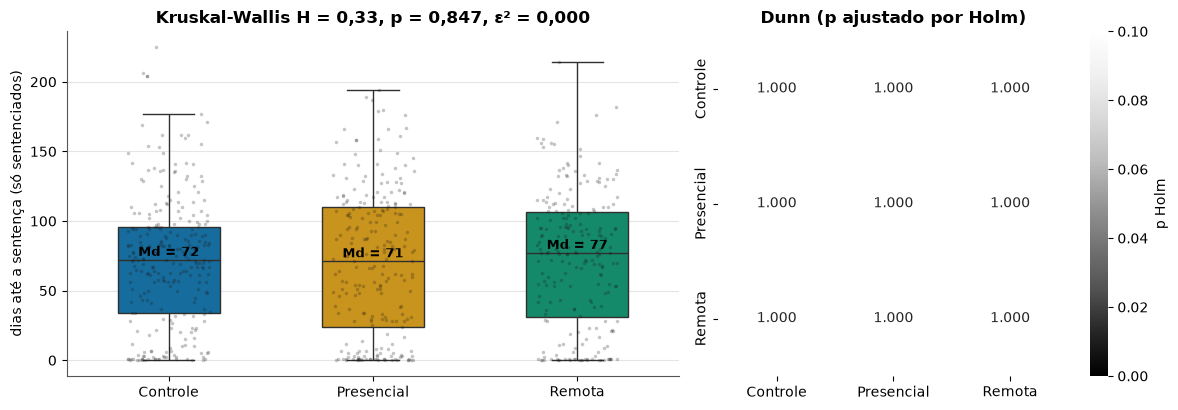

In [43]:
t3_enc = t3_sent.copy()
amostras = [t3_enc.loc[t3_enc['grupo'] == g, 'tempo_f'].values for g in ORDEM_GRUPO]
H_kw, p_kw = stats.kruskal(*amostras)
eps2 = H_kw / (len(t3_enc) - 1)
desc = t3_enc.groupby('grupo', observed=True)['tempo_f'].describe()[['count', '25%', '50%', '75%', 'mean']]
display(desc.round(1))
print(f'Kruskal-Wallis: H = {fmt_br(H_kw, 2)}, gl = 2, p {tst_eq(p_kw)} | ε² = {fmt_br(eps2, 4)}')
dunn = sp.posthoc_dunn(t3_enc, val_col='tempo_f', group_col='grupo', p_adjust='holm').loc[ORDEM_GRUPO, ORDEM_GRUPO]
print('Dunn (p ajustado por Holm):'); display(dunn.round(4))
tst_registra('3.4', 'H8 tempo (condicional)', 'Kruskal-Wallis tempo × grupo (sentenciados)', 'distribuições iguais',
             f'H(2) = {fmt_br(H_kw, 2)}', p_kw, f'ε² = {fmt_br(eps2, 4)}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.4, 1]})
sns.boxplot(data=t3_enc, x='grupo', y='tempo_f', order=ORDEM_GRUPO, palette=CORES_GRUPO, ax=ax[0], width=0.5, fliersize=0)
sns.stripplot(data=t3_enc, x='grupo', y='tempo_f', order=ORDEM_GRUPO, color=TINTA, alpha=0.25, size=2.5, ax=ax[0], jitter=0.2)
for i, g in enumerate(ORDEM_GRUPO):
    ax[0].text(i, desc.loc[g, '50%'] + 3, f'Md = {fmt_br(desc.loc[g, "50%"], 0)}', ha='center', fontsize=9, fontweight='bold')
ax[0].set_xlabel(''); ax[0].set_ylabel('dias até a sentença (só sentenciados)')
ax[0].set_title(f'Kruskal-Wallis H = {fmt_br(H_kw, 2)}, p {tst_eq(p_kw)}, ε² = {fmt_br(eps2, 3)}')
sns.heatmap(dunn, annot=True, fmt='.3f', cmap='Greys_r', vmin=0, vmax=0.1, ax=ax[1], linewidths=0.5, cbar_kws={'label': 'p Holm'})
ax[1].set_title('Dunn (p ajustado por Holm)')
plt.tight_layout(); plt.show()

### 3.4.2 Mann-Whitney par a par com delta de Cliff

O mesmo contraste em pares, com o **delta de Cliff** d = P(X > Y) − P(X < Y), que vai de −1 a 1 e coincide com a correlação bisserial de postos. Referência de Romano et al. (2006): |d| < 0,147 desprezível, < 0,33 pequeno, < 0,474 médio. **H₀:** P(X > Y) = P(X < Y). Holm na família de três pares.

,Comparação,n1,n2,U,p,delta de Cliff,IC inf,IC sup,p Holm
0,Presencial × Controle,230,262,29838.0,"0,853",-0.010,-0.110,0.092,"1,000"
1,Remota × Controle,216,262,29104.5,"0,591",0.029,-0.074,0.133,"1,000"
2,Presencial × Remota,230,216,24228.0,"0,653",-0.025,-0.128,0.083,"1,000"


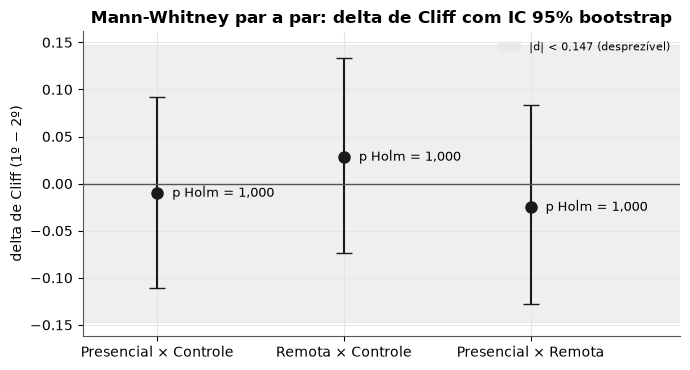

In [44]:
linhas = []
for a, b in PARES_GRUPO:
    xa = t3_enc.loc[t3_enc['grupo'] == a, 'tempo_f']; xb = t3_enc.loc[t3_enc['grupo'] == b, 'tempo_f']
    U, p = stats.mannwhitneyu(xa, xb, alternative='two-sided')
    d, dlo, dhi = tst_cliff(xa, xb)
    linhas.append({'Comparação': f'{a} × {b}', 'n1': len(xa), 'n2': len(xb), 'U': U, 'p': p,
                   'delta de Cliff': d, 'IC inf': dlo, 'IC sup': dhi})
t3_mw = pd.DataFrame(linhas); t3_mw['p Holm'] = tst_holm(t3_mw['p'])
tst_tabela_p(t3_mw, casas=3)
for _, r in t3_mw.iterrows():
    tst_registra('3.4', 'H8 pares MW', f'Mann-Whitney {r["Comparação"]} (sentenciados)', 'P(X>Y) = P(X<Y)',
                 f'U = {fmt_br(r["U"], 0)}', r['p'], f'Cliff d = {tst_ic_txt(r["delta de Cliff"], r["IC inf"], r["IC sup"], 3)}')

fig, ax = plt.subplots(figsize=(7, 3.8))
for i, r in t3_mw.iterrows():
    ax.errorbar(i, r['delta de Cliff'], yerr=[[r['delta de Cliff'] - r['IC inf']], [r['IC sup'] - r['delta de Cliff']]],
                fmt='o', color=TINTA, capsize=6, ms=8)
    ax.text(i + 0.08, r['delta de Cliff'], f'p Holm {tst_eq(r["p Holm"])}', fontsize=9, va='center')
ax.axhline(0, color=TINTA_2, lw=1); ax.axhspan(-0.147, 0.147, color=GRADE, alpha=0.6, label='|d| < 0,147 (desprezível)')
ax.set_xticks(range(3), t3_mw['Comparação']); ax.set_ylabel('delta de Cliff (1º − 2º)'); ax.set_xlim(-0.4, 2.8)
ax.set_title('Mann-Whitney par a par: delta de Cliff com IC 95% bootstrap'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3.4.3 Teste da mediana de Mood

Teste mais simples e robusto (só usa "acima/abaixo da mediana geral"), com menos poder que o KW. **H₀:** os três grupos têm a mesma mediana populacional. É uma tabela 3 × 2 testada por χ².

,Controle,Presencial,Remota
> mediana,127,112,115
≤ mediana,135,118,101


Mediana geral = 74 dias | χ²(2) = 1,31, p = 0,520


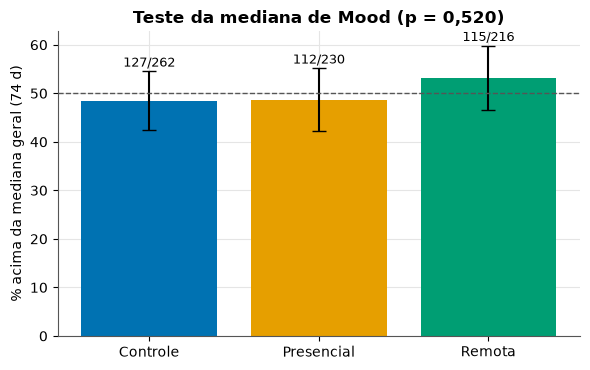

In [45]:
stat_m, p_m, med_m, tab_m = stats.median_test(*amostras, ties='below')
tab_m = pd.DataFrame(tab_m, index=['> mediana', '≤ mediana'], columns=ORDEM_GRUPO)
display(tab_m)
print(f'Mediana geral = {fmt_br(med_m, 0)} dias | χ²(2) = {fmt_br(stat_m, 2)}, p {tst_eq(p_m)}')
tst_registra('3.4', 'H8 tempo (condicional)', 'Mediana de Mood (sentenciados)', 'medianas iguais', f'χ²(2) = {fmt_br(stat_m, 2)}', p_m, '')

fig, ax = plt.subplots(figsize=(6, 3.8))
for i, g in enumerate(ORDEM_GRUPO):
    xg, ng = int(tab_m.loc['> mediana', g]), int(tab_m[g].sum())
    lo, hi = tst_wilson(xg, ng)
    ax.bar(i, 100 * xg / ng, color=CORES_GRUPO[g], yerr=[[100 * (xg / ng - lo)], [100 * (hi - xg / ng)]], capsize=5)
    ax.text(i, 100 * hi + 1, f'{xg}/{ng}', ha='center', fontsize=9)
ax.axhline(50, color=TINTA_2, ls='--', lw=1)
ax.set_xticks(range(3), ORDEM_GRUPO); ax.set_ylabel(f'% acima da mediana geral ({fmt_br(med_m, 0)} d)')
ax.set_title(f'Teste da mediana de Mood (p {tst_eq(p_m)})')
plt.tight_layout(); plt.show()

### 3.4.4 ANOVA e Welch: contraste didático

A ANOVA de um fator pressupõe normalidade dos resíduos e variâncias iguais; a ANOVA de Welch dispensa a igualdade de variâncias. Os pressupostos são verificados com **Levene** (centrado na média) e **Brown-Forsythe** (centrado na mediana, robusto) para a homogeneidade, e **Shapiro-Wilk** nos resíduos por grupo. O objetivo é **didático**: mostrar que, com n grande, a conclusão coincide com a do KW, mas que o teste paramétrico está formalmente fora das suas condições — e que nenhum dos dois resolve a censura.

ANOVA: F = 0,133, p = 0,875 | Welch: F = 0,128, p = 0,880
Levene (média): W = 5,333, p = 0,005 | Brown-Forsythe (mediana): W = 5,290, p = 0,005
Shapiro-Wilk dos resíduos, Controle: W = 0,962, p < 0,001
Shapiro-Wilk dos resíduos, Presencial: W = 0,943, p < 0,001
Shapiro-Wilk dos resíduos, Remota: W = 0,958, p < 0,001
η² = 0,0004


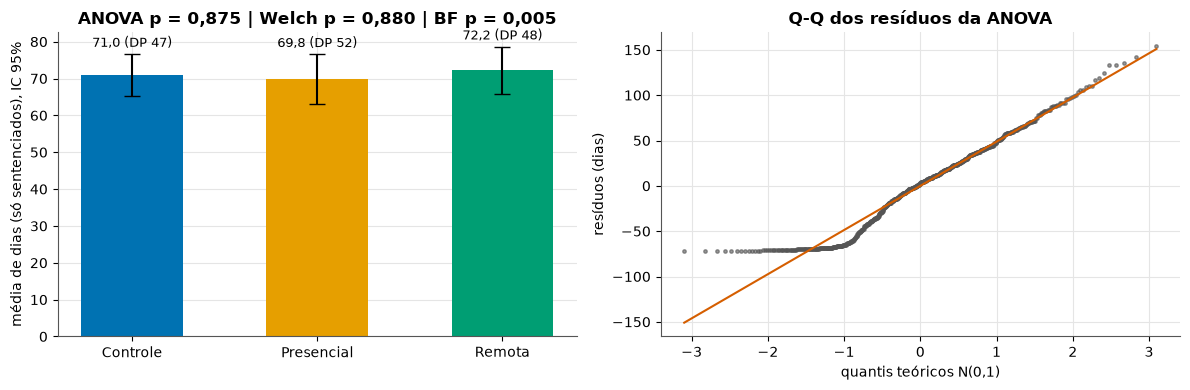

In [46]:
F_a, p_a = stats.f_oneway(*amostras)
welch = anova_oneway(t3_enc['tempo_f'].values, t3_enc['grupo'].astype(str).values, use_var='unequal')
lev, p_lev = stats.levene(*amostras, center='mean')
bf, p_bf = stats.levene(*amostras, center='median')
residuos = np.concatenate([a - a.mean() for a in amostras])
sw = {g: stats.shapiro(a - a.mean()) for g, a in zip(ORDEM_GRUPO, amostras)}
print(f'ANOVA: F = {fmt_br(F_a, 3)}, p {tst_eq(p_a)} | Welch: F = {fmt_br(welch.statistic, 3)}, p {tst_eq(welch.pvalue)}')
print(f'Levene (média): W = {fmt_br(lev, 3)}, p {tst_eq(p_lev)} | Brown-Forsythe (mediana): W = {fmt_br(bf, 3)}, p {tst_eq(p_bf)}')
for g, r in sw.items():
    print(f'Shapiro-Wilk dos resíduos, {g}: W = {fmt_br(r.statistic, 3)}, p {tst_eq(r.pvalue)}')
eta2 = F_a * 2 / (F_a * 2 + len(t3_enc) - 3)
print(f'η² = {fmt_br(eta2, 4)}')
tst_registra('3.4', 'H8 didático', 'ANOVA de Welch (sentenciados; didático)', 'médias iguais', f'F = {fmt_br(welch.statistic, 3)}',
             welch.pvalue, f'η² = {fmt_br(eta2, 4)}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, (g, a) in enumerate(zip(ORDEM_GRUPO, amostras)):
    m, ep = a.mean(), a.std(ddof=1) / np.sqrt(len(a))
    ax[0].bar(i, m, color=CORES_GRUPO[g], yerr=1.96 * ep, capsize=6, width=0.55)
    ax[0].text(i, m + 1.96 * ep + 2, f'{fmt_br(m, 1)} (DP {fmt_br(a.std(ddof=1), 0)})', ha='center', fontsize=9)
ax[0].set_xticks(range(3), ORDEM_GRUPO); ax[0].set_ylabel('média de dias (só sentenciados), IC 95%')
ax[0].set_title(f'ANOVA p {tst_eq(p_a)} | Welch p {tst_eq(welch.pvalue)} | BF p {tst_eq(p_bf)}')
(osm, osr), _ = stats.probplot(residuos, dist='norm')
ax[1].scatter(osm, osr, s=6, color=TINTA_2, alpha=0.6)
ax[1].plot(osm, osm * residuos.std(ddof=1), color='#D55E00', lw=1.5)
ax[1].set_xlabel('quantis teóricos N(0,1)'); ax[1].set_ylabel('resíduos (dias)'); ax[1].set_title('Q-Q dos resíduos da ANOVA')
plt.tight_layout(); plt.show()

### 3.4.5 Estratificado pelo tipo de sentença: o efeito de composição

Os tipos de sentença têm tempos muito diferentes (uma extinção sem mérito por ausência à AC sai rápido; um julgamento de mérito exige contestação e instrução). Como os grupos diferem na **composição** de tipos (seção 3.2), uma diferença no tempo "total" pode vir só da mistura. Testa-se, por isso, o tempo × grupo **dentro de cada tipo** (KW, Holm na família de três estratos).

Ressalva: estratificar por uma variável **pós-sorteio** (o tipo de desfecho é consequência do rito) quebra a comparabilidade garantida pelo sorteio; a análise é descritiva do mecanismo, não estimativa causal.

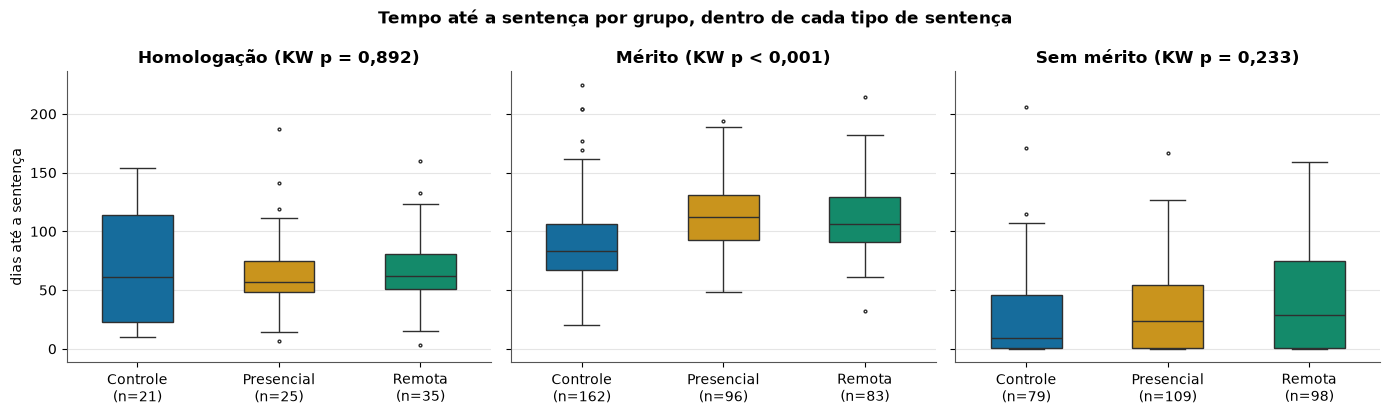

,Tipo,n,Md Controle,Md Presencial,Md Remota,H,p,ε²,p Holm
0,Homologação,81,61.0,57.0,62.0,0.228,"0,892",0.003,"0,892"
1,Mérito,341,83.0,112.5,106.0,45.732,"< 0,001",0.135,"< 0,001"
2,Sem mérito,286,9.0,24.0,28.5,2.918,"0,233",0.010,"0,465"


Mediana do tempo por tipo (todos os grupos): {'Homologação': '61', 'Mérito': '97', 'Sem mérito': '20'}


In [47]:
linhas = []
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for k, tipo in enumerate(['Homologação', 'Mérito', 'Sem mérito']):
    sub = t3_enc[t3_enc['tipo'] == tipo]
    a = [sub.loc[sub['grupo'] == g, 'tempo_f'].values for g in ORDEM_GRUPO]
    H, p = stats.kruskal(*a)
    linhas.append({'Tipo': tipo, 'n': len(sub), **{f'Md {g}': np.median(x) for g, x in zip(ORDEM_GRUPO, a)},
                   'H': H, 'p': p, 'ε²': H / (len(sub) - 1)})
    sns.boxplot(data=sub, x='grupo', y='tempo_f', order=ORDEM_GRUPO, palette=CORES_GRUPO, ax=ax[k], width=0.5, fliersize=2)
    ax[k].set_title(f'{tipo} (KW p {tst_eq(p)})'); ax[k].set_xlabel(''); ax[k].set_ylabel('dias até a sentença' if k == 0 else '')
    ax[k].set_xticks(range(3), [f'{g}\n(n={len(x)})' for g, x in zip(ORDEM_GRUPO, a)])
plt.suptitle('Tempo até a sentença por grupo, dentro de cada tipo de sentença', fontweight='bold')
plt.tight_layout(); plt.show()
t3_estrato = pd.DataFrame(linhas); t3_estrato['p Holm'] = tst_holm(t3_estrato['p'])
tst_tabela_p(t3_estrato, casas=3)
for _, r in t3_estrato.iterrows():
    tst_registra('3.4', 'H8 por tipo', f'Kruskal-Wallis tempo × grupo, só {r["Tipo"]}', 'distribuições iguais',
                 f'H(2) = {fmt_br(r["H"], 2)}', r['p'], f'ε² = {fmt_br(r["ε²"], 4)}')
mediana_tipo = t3_enc.groupby('tipo', observed=True)['tempo_f'].median()
print('Mediana do tempo por tipo (todos os grupos):', {k: fmt_br(v, 0) for k, v in mediana_tipo.items()})

### 3.4.6 O Kruskal-Wallis do professor (p ≈ 0,48) e como ele muda

O notebook do professor aplicou o KW a **todos** os processos, tratando o tempo dos ativos (censurado no corte) como tempo completo e a "Decisão" como sentença (E10, E14, E17), e concluiu "sem diferença" (H = 1,48; p = 0,478). Abaixo, o mesmo teste em quatro versões:

1. **Professor (reproduzido na base de 938):** todos os tempos, censurados como se completos;
2. **Só sentenciados (708):** condicional, seção 3.4.1;
3. **Janela de 65 dias (914, sem redistribuídos):** tempo truncado em 65, min(T, 65). Como todos são acompanhados por ≥ 65 dias, o tempo truncado é **observado** para todos: é a única versão do KW livre de censura (equivale a comparar a área sob a curva de sobrevivência até 65 dias, a ideia do RMST da Parte IV);
4. **Sentença até 65 dias (indicador):** χ² da proporção sentenciada até o 65º dia.

E também o **Mann-Whitney com × sem acordo na AC** do professor (E24), refeito só entre as AC realizadas que já têm sentença.

,Versão,n,H / χ²,p,Medida,Controle,Presencial,Remota
0,"1. Professor: todos, censura ignorada",938,1.164,"0,559",mediana (dias),77.000,83.500,81.000
1,2. Só sentenciados (condicional),708,0.333,"0,847",mediana (dias),72.000,71.000,77.000
2,3. Tempo truncado em 65 d (sem censura),914,4.000,"0,135","média de min(T, 65) (dias)",51.779,49.928,53.056
3,4. Sentença até 65 d (χ² 3×2),914,5.538,"0,063",% sentenciado até 65 d,36.039,35.855,28.146


% sentenciados até 65 dias: {'Controle': '36,0%', 'Presencial': '35,9%', 'Remota': '28,1%'}
% de ativos (censurados) por grupo: {'Controle': '14,7%', 'Presencial': '23,6%', 'Remota': '27,7%'}
Mediana do tempo dos ATIVOS por grupo (seguimento, não duração): {'Controle': '112', 'Presencial': '100', 'Remota': '89'}


E24 refeito (AC realizadas e sentenciadas): com acordo n = 17, Md = 63 | sem acordo n = 246, Md = 104 | U = 816, p < 0,001, Cliff d = -0,610 [-0,850; -0,315]


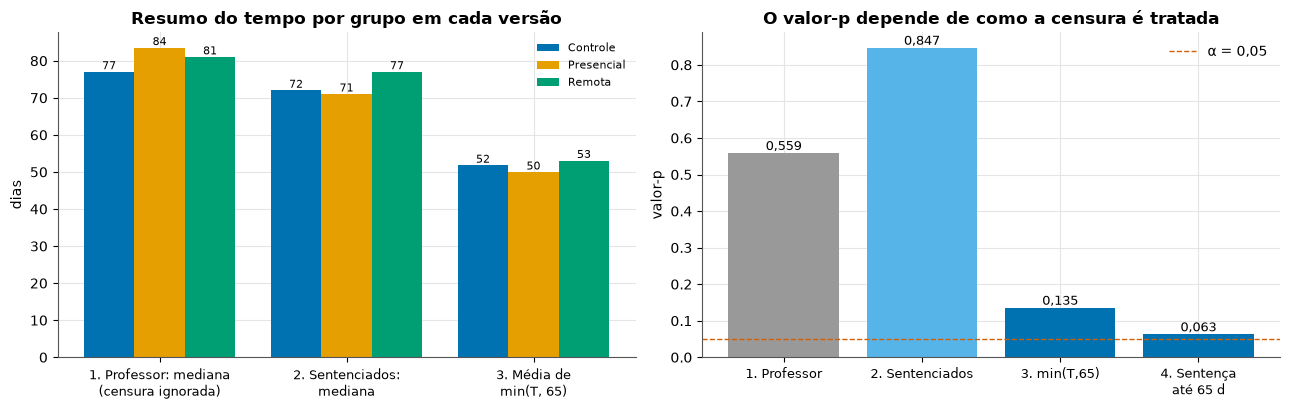

In [48]:
def kw_grupos(df, col):
    a = [df.loc[df['grupo'] == g, col].values for g in ORDEM_GRUPO]
    H, p = stats.kruskal(*a)
    resumo = [np.mean(x) for x in a] if col == 'tempo65' else [np.median(x) for x in a]
    return H, p, resumo, len(df)

t3['tempo65'] = t3['tempo_f'].clip(upper=65)
nao_red = t3[t3['tipo_desfecho'] != 'Redistribuição']
versoes = {
    '1. Professor: todos, censura ignorada': kw_grupos(t3, 'tempo_f'),
    '2. Só sentenciados (condicional)': kw_grupos(t3_enc, 'tempo_f'),
    '3. Tempo truncado em 65 d (sem censura)': kw_grupos(nao_red, 'tempo65'),
}
y65 = (nao_red['evento'] == 1) & (nao_red['tempo_f'] <= 65)
tab_s65 = pd.crosstab(nao_red['grupo'], y65)
c2_s65, p_s65, _, _ = stats.chi2_contingency(tab_s65, correction=False)
MEDIDA = ['mediana (dias)', 'mediana (dias)', 'média de min(T, 65) (dias)']
linhas = [{'Versão': k, 'n': v[3], 'H / χ²': v[0], 'p': v[1], 'Medida': med, **{g: m for g, m in zip(ORDEM_GRUPO, v[2])}}
          for (k, v), med in zip(versoes.items(), MEDIDA)]
linhas.append({'Versão': '4. Sentença até 65 d (χ² 3×2)', 'n': len(nao_red), 'H / χ²': c2_s65, 'p': p_s65,
               'Medida': '% sentenciado até 65 d', **{g: 100 * tab_s65.loc[g, True] / tab_s65.loc[g].sum() for g in ORDEM_GRUPO}})
t3_versoes = pd.DataFrame(linhas)
tst_tabela_p(t3_versoes, casas=3)
print('% sentenciados até 65 dias:', {g: pct_br(tab_s65.loc[g, True] / tab_s65.loc[g].sum()) for g in ORDEM_GRUPO})
print('% de ativos (censurados) por grupo:', {g: pct_br((t3.loc[t3['grupo'] == g, 'tipo_desfecho'] == 'Ativo').mean()) for g in ORDEM_GRUPO})
print('Mediana do tempo dos ATIVOS por grupo (seguimento, não duração):',
      {g: fmt_br(t3.loc[(t3['grupo'] == g) & (t3['tipo_desfecho'] == 'Ativo'), 'tempo_f'].median(), 0) for g in ORDEM_GRUPO})
tst_registra('3.4', 'H8 sem censura', 'Kruskal-Wallis min(T, 65) × grupo', 'distribuições iguais',
             f'H(2) = {fmt_br(versoes["3. Tempo truncado em 65 d (sem censura)"][0], 2)}', versoes['3. Tempo truncado em 65 d (sem censura)'][1], '')
tst_registra('3.4', 'H8 sem censura', 'χ² sentença até 65 d × grupo', 'proporção igual', f'χ²(2) = {fmt_br(c2_s65, 2)}', p_s65,
             f'V = {fmt_br(tst_cramer(tab_s65), 3)}')

# E24: Mann-Whitney com × sem acordo na AC, refeito entre AC realizadas já sentenciadas
acs = t3_ac[t3_ac['evento'] == 1]
com, sem = acs.loc[acs['acordo_ac'] == True, 'tempo_f'], acs.loc[acs['acordo_ac'] == False, 'tempo_f']
U24, p24 = stats.mannwhitneyu(com, sem)
d24, d24lo, d24hi = tst_cliff(com, sem)
print(f'E24 refeito (AC realizadas e sentenciadas): com acordo n = {len(com)}, Md = {fmt_br(com.median(), 0)} | '
      f'sem acordo n = {len(sem)}, Md = {fmt_br(sem.median(), 0)} | U = {fmt_br(U24, 0)}, p {tst_eq(p24)}, '
      f'Cliff d = {tst_ic_txt(d24, d24lo, d24hi, 3)}')
tst_registra('3.4', 'H8 acordo', 'Mann-Whitney tempo com × sem acordo na AC (AC realizadas, sentenciados)', 'P(X>Y) = P(X<Y)',
             f'U = {fmt_br(U24, 0)}', p24, f'Cliff d = {tst_ic_txt(d24, d24lo, d24hi, 3)}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(3); w = 0.27
for i, g in enumerate(ORDEM_GRUPO):
    barras = ax[0].bar(x + (i - 1) * w, t3_versoes[g].iloc[:3], w, color=CORES_GRUPO[g], label=g)
    ax[0].bar_label(barras, labels=[fmt_br(v, 0) for v in t3_versoes[g].iloc[:3]], fontsize=8)
ax[0].set_xticks(x, ['1. Professor: mediana\n(censura ignorada)', '2. Sentenciados:\nmediana', '3. Média de\nmin(T, 65)'], fontsize=9)
ax[0].set_ylabel('dias'); ax[0].set_title('Resumo do tempo por grupo em cada versão'); ax[0].legend(fontsize=8)
pv = t3_versoes['p'].values
barras = ax[1].bar(range(4), pv, color=['#999999', '#56B4E9', '#0072B2', '#0072B2'])
ax[1].bar_label(barras, labels=[p_br(p) for p in pv], fontsize=9)
ax[1].axhline(0.05, color='#D55E00', ls='--', lw=1, label='α = 0,05')
ax[1].set_xticks(range(4), ['1. Professor', '2. Sentenciados', '3. min(T,65)', '4. Sentença\naté 65 d'], fontsize=9)
ax[1].set_ylabel('valor-p'); ax[1].set_title('O valor-p depende de como a censura é tratada'); ax[1].legend()
plt.tight_layout(); plt.show()

**Leitura. Entre os sentenciados, os três grupos "levam o mesmo tempo". Esse resultado esconde dois efeitos opostos e é enviesado pela censura.**

- **Testes clássicos, só entre os sentenciados (708):**
  - **Kruskal-Wallis:** H = 0,33, p = 0,847, ε² = 0,0005, praticamente zero. Medianas: Controle 72, Presencial 71 e Remota 77 dias. O Dunn com Holm dá p = 1 em todos os pares;
  - **Mann-Whitney:** todos os deltas de Cliff estão entre −0,03 e +0,03, com ICs dentro de ±0,13 (efeito desprezível);
  - **mediana de Mood:** p = 0,520.
- **ANOVA e Welch (didático).** F = 0,13, p = 0,875; Welch p = 0,880. A conclusão é a mesma, mas os pressupostos falham:
  - **homocedasticidade:** Levene p = 0,005 e Brown-Forsythe p = 0,005 rejeitam a igualdade de variâncias. O Presencial é o mais disperso (P75 = 110 dias);
  - **normalidade:** Shapiro-Wilk rejeita nos resíduos dos três grupos (p < 0,001), e o Q-Q mostra caudas curtas, cortadas pela censura, e massa perto de zero.

  Com n ≈ 230 por grupo, o F é robusto o bastante para não errar a conclusão, mas não há razão para preferi-lo ao KW.
- **O efeito de composição.** Estratificando pelo tipo de sentença:
  - **mérito:** os braços com AC são **muito mais lentos**. Medianas: Controle 83, Presencial 112,5 e Remota 106 dias. KW H = 45,7, p Holm < 0,001, ε² = 0,13 (efeito médio). A AC inaugural acrescenta uma etapa antes da contestação, e o julgamento de mérito chega cerca de um mês depois;
  - **sem mérito:** as extinções saem cedo nos três grupos (medianas 9, 24 e 28,5 dias; p Holm = 0,465);
  - **homologação:** 61, 57 e 62 dias (p = 0,892).

  Os braços com AC têm **mais** extinções rápidas (sem mérito, mediana geral de 20 dias) e **menos** julgamentos de mérito (mediana geral de 97 dias). No agregado, a lentidão do mérito é compensada pela rapidez das extinções. O "nenhuma diferença" do agregado é um **paradoxo de composição**, não ausência de efeito. Ressalva: o tipo de sentença é pós-sorteio, então a estratificação descreve o mecanismo, mas não estima o efeito causal.
- **Por que o KW do professor dá p ≈ 0,5, e como isso muda (E14, E17).** Na base primária, a reprodução dá H = 1,16, p = 0,559 (no original, p = 0,478, com 944 linhas, duplicatas e "Decisão" como sentença). O teste mistura dois tipos de número:
  - durações reais dos encerrados;
  - **tempos de seguimento** dos ativos, que são 14,7% do Controle, 23,6% do Presencial e 27,7% da Remota. Os ativos não têm duração, e sim um piso: estão em tramitação há pelo menos 112, 100 e 89 dias (medianas).

  O grupo com mais ativos tem mais tempos "cortados", e o teste compara grandezas diferentes. Retirar os ativos (versão 2) não resolve: a comparação passa a ser entre os que encerraram rápido o bastante, e o p sobe para 0,847.
- **Versões sem censura.** Com a janela comum de 65 dias, observada para todos:
  - média de min(T, 65): 51,8, 49,9 e 53,1 dias (KW p = 0,135);
  - sentença até o 65º dia: 36,0%, 35,9% e 28,1% (χ² p = 0,063).

  A Remota já aparece mais lenta, embora sem significância nesse horizonte curto. Usando todo o seguimento com Kaplan-Meier e log-rank (Parte IV), a revisão do notebook do professor encontrou medianas de Controle 80, Presencial 93 e Remota 94 dias (log-rank p ≈ 0,03). **A conclusão muda** de "o rito não importa" (KW ingênuo) para "a AC obrigatória alonga a tramitação", e só um método que respeita a censura consegue mostrar isso.
- **E24 refeito.** Entre as AC realizadas já sentenciadas, os 17 processos com acordo na AC terminaram em 63 dias (mediana), contra 104 dias dos sem acordo (U = 816, p < 0,001, delta de Cliff = −0,61, IC −0,85 a −0,32). O efeito é grande, mas em boa parte é **definicional**: o acordo encerra o processo com a homologação, e quem não fez acordo segue para contestação e julgamento. A pergunta correta ("o acordo na AC antecipa o fim?") é de riscos competitivos (Parte IV).

---

## 3.5 Ordem de chegada (questão 2.7; H9 a H11)

### 3.5.1 O sorteio foi aleatório? Teste de corridas de Wald-Wolfowitz

Segundo o pesquisador, o sorteio seguiu a ordem de chegada. Se a alocação foi de fato aleatória, a sequência de grupos na ordem de chegada não deve ter **padrões**: nem corridas longas demais (blocos de um mesmo grupo), nem alternância regular demais (rodízio Controle → Presencial → Remota). O **número de corridas** R (sequências maximais de um mesmo grupo) mede isso.

- **H₀:** a sequência é uma permutação aleatória dos 938 rótulos. **H₁:** bilateral (R pequeno = agrupamento; R grande = alternância).
- **Três categorias:** a distribuição de R sob H₀ é obtida por **permutação** (10.000 embaralhamentos da sequência); também se compara a **maior corrida** observada.
- **Por grupo:** cada grupo × os demais (sequência binária), com a aproximação normal de Wald-Wolfowitz e Holm.

Corridas observadas R = 626 | esperado sob H0 = 626,3 | permutação: média 626,2, DP 14,3 | p bilateral = 1,000
Maior corrida = 8 | P(maior corrida ≥ 8 sob H0) = 0,239


,Grupo,n,Corridas,Esperado,z,p,p Holm
0,Controle,313,424,418.111,0.433,"0,665","0,906"
1,Presencial,314,429,418.774,0.750,"0,453","0,906"
2,Remota,311,400,416.772,-1.236,"0,216","0,649"


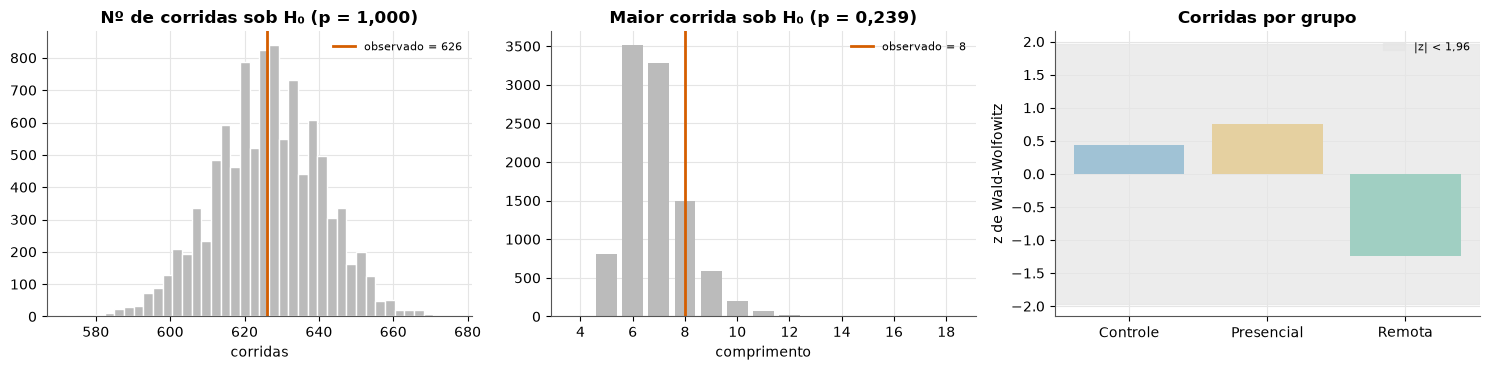

In [49]:
seq = t3.sort_values('ordem_chegada')['grupo'].astype(str).values
def n_corridas(s):
    return 1 + int((s[1:] != s[:-1]).sum())
def maior_corrida(s):
    m = c = 1
    for i in range(1, len(s)):
        c = c + 1 if s[i] == s[i - 1] else 1
        m = max(m, c)
    return m
R_obs, L_obs = n_corridas(seq), maior_corrida(seq)
n = len(seq); cont = pd.Series(seq).value_counts()
E_R = 1 + (n - 1) - (cont * (cont - 1)).sum() / n
rng = np.random.default_rng(SEMENTE)
R_null, L_null = np.empty(10000), np.empty(10000)
for b in range(10000):
    s = rng.permutation(seq)
    R_null[b], L_null[b] = n_corridas(s), maior_corrida(s)
p_R = min(1, 2 * min((R_null <= R_obs).mean(), (R_null >= R_obs).mean()))
p_L = (L_null >= L_obs).mean()
print(f'Corridas observadas R = {R_obs} | esperado sob H0 = {fmt_br(E_R, 1)} | permutação: média {fmt_br(R_null.mean(), 1)}, '
      f'DP {fmt_br(R_null.std(), 1)} | p bilateral {tst_eq(p_R)}')
print(f'Maior corrida = {L_obs} | P(maior corrida ≥ {L_obs} sob H0) {tst_eq(p_L)}')
tst_registra('3.5', 'H9 sorteio', 'Corridas (3 grupos, permutação)', 'sequência aleatória', f'R = {R_obs} (E = {fmt_br(E_R, 1)})', p_R, '')

linhas = []
for g in ORDEM_GRUPO:
    b = (seq == g)
    n1, n2 = b.sum(), (~b).sum()
    R = n_corridas(b)
    mu = 2 * n1 * n2 / n + 1
    var = 2 * n1 * n2 * (2 * n1 * n2 - n) / (n ** 2 * (n - 1))
    z = (R - mu) / np.sqrt(var)
    linhas.append({'Grupo': g, 'n': n1, 'Corridas': R, 'Esperado': mu, 'z': z, 'p': 2 * stats.norm.sf(abs(z))})
t3_runs = pd.DataFrame(linhas); t3_runs['p Holm'] = tst_holm(t3_runs['p'])
tst_tabela_p(t3_runs, casas=3)
for _, r in t3_runs.iterrows():
    tst_registra('3.5', 'H9 sorteio por grupo', f'Corridas {r["Grupo"]} × demais (Wald-Wolfowitz)', 'sequência aleatória',
                 f'z = {fmt_br(r["z"], 2)}', r['p'], '')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(R_null, bins=40, color='#BBBBBB', edgecolor='white')
ax[0].axvline(R_obs, color='#D55E00', lw=2, label=f'observado = {R_obs}')
ax[0].set_title(f'Nº de corridas sob H₀ (p {tst_eq(p_R)})'); ax[0].set_xlabel('corridas'); ax[0].legend(fontsize=8)
ax[1].bar(*np.unique(L_null, return_counts=True), color='#BBBBBB')
ax[1].axvline(L_obs, color='#D55E00', lw=2, label=f'observado = {L_obs}')
ax[1].set_title(f'Maior corrida sob H₀ (p {tst_eq(p_L)})'); ax[1].set_xlabel('comprimento'); ax[1].legend(fontsize=8)
ax[2].bar(range(3), t3_runs['z'], color=[CORES_GRUPO[g] for g in ORDEM_GRUPO])
ax[2].axhspan(-1.96, 1.96, color=GRADE, alpha=0.7, label='|z| < 1,96')
ax[2].set_xticks(range(3), ORDEM_GRUPO); ax[2].set_ylabel('z de Wald-Wolfowitz'); ax[2].set_title('Corridas por grupo'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3.5.2 Ordem de chegada × tempo: Spearman, Kendall e o artefato da censura (H10)

A ordem de chegada é **ordinal**; o tempo, quantitativo com censura. Pearson não cabe (E13, E16); Spearman (ρ) e Kendall (τ-b, que trata empates) medem associação monótona. **H₀:** ρ = 0 (τ = 0).

O problema é a censura: um processo distribuído em agosto só pode aparecer "encerrado" se tiver sido rápido (no máximo 65 dias), enquanto um de janeiro pode ter encerrado em até 279 dias. Entre os encerrados, a ordem de chegada **tem de** se correlacionar negativamente com o tempo, mesmo que o ritmo da vara não tenha mudado. Quatro versões:

1. **Todos (938)**, tempo censurado como se completo;
2. **Só sentenciados (708)**: o artefato;
3. **Janela comum de 65 dias**: min(T, 65), observado para todos (censura administrativa em 65 dias para todos) — a versão válida;
4. **Simulação sob H₀:** tempos gerados independentemente da ordem e censurados com o acompanhamento real de cada processo; mostra que o artefato aparece mesmo quando não existe associação verdadeira.

,Versão,ρ Spearman,p (ρ),τ Kendall,p (τ),n
0,"1. Todos, censura ignorada",-0.0409,"0,211",-0.0496,"0,024",938
1,2. Só sentenciados,-0.1184,"0,002",-0.0824,"0,001",708
2,"3. min(T, 65), sem redistribuídos",0.1402,"< 0,001",0.1065,"< 0,001",914


Simulação sob H0 (500 réplicas) — média [percentis 2,5 e 97,5] de ρ:
  todos (censura ignorada)     -0,188 [-0,246; -0,130]
  só encerrados                -0,280 [-0,343; -0,212]
  min(T, 65)                   -0,001 [-0,066; 0,067]


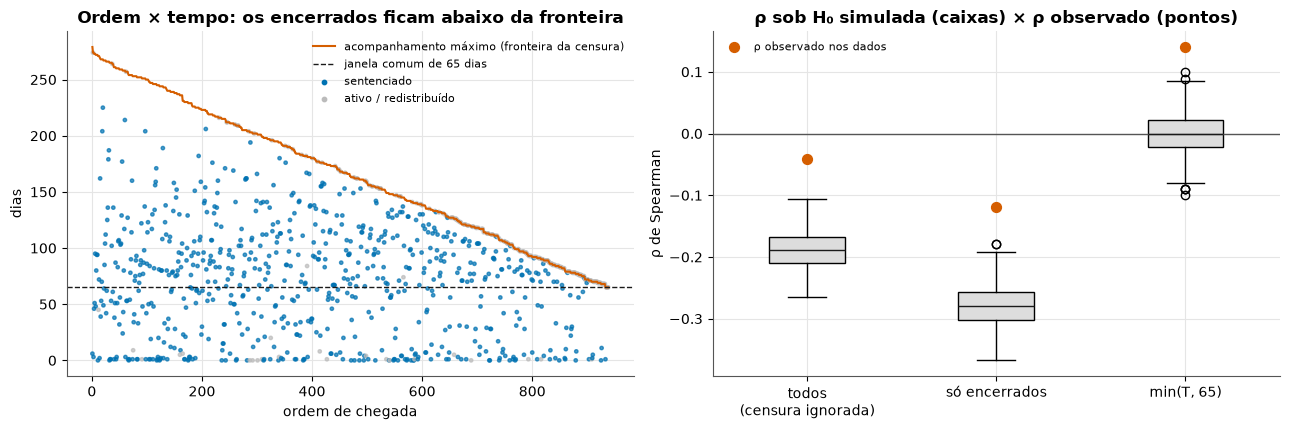

In [50]:
def corr_ord(df, col):
    rho, p_rho = stats.spearmanr(df['ordem_chegada'].astype(float), df[col])
    tau, p_tau = stats.kendalltau(df['ordem_chegada'].astype(float), df[col])
    return rho, p_rho, tau, p_tau, len(df)

t3_corr = pd.DataFrame([
    dict(zip(['Versão', 'ρ Spearman', 'p (ρ)', 'τ Kendall', 'p (τ)', 'n'], ['1. Todos, censura ignorada', *corr_ord(t3, 'tempo_f')])),
    dict(zip(['Versão', 'ρ Spearman', 'p (ρ)', 'τ Kendall', 'p (τ)', 'n'], ['2. Só sentenciados', *corr_ord(t3_enc, 'tempo_f')])),
    dict(zip(['Versão', 'ρ Spearman', 'p (ρ)', 'τ Kendall', 'p (τ)', 'n'], ['3. min(T, 65), sem redistribuídos', *corr_ord(nao_red, 'tempo65')])),
])
tst_tabela_p(t3_corr, casas=4, colunas_p=('p (ρ)', 'p (τ)'))
for _, r in t3_corr.iterrows():
    tst_registra('3.5', 'H10 ordem × tempo', f'Spearman ordem × tempo: {r["Versão"]}', 'ρ = 0', f'ρ = {fmt_br(r["ρ Spearman"], 3)}', r['p (ρ)'],
                 f'τ = {fmt_br(r["τ Kendall"], 3)}')

# Simulação: tempos independentes da ordem, censurados pelo acompanhamento real de cada processo
rng = np.random.default_rng(SEMENTE)
fu = t3['followup'].astype(float).values; ordem = t3['ordem_chegada'].astype(float).values
sim = {'todos (censura ignorada)': [], 'só encerrados': [], 'min(T, 65)': []}
for _ in range(500):
    T = rng.weibull(1.6, len(fu)) * 115            # forma e escala próximas às dos dados; sem relação com a ordem
    obs = np.minimum(T, fu); enc = T <= fu
    sim['todos (censura ignorada)'].append(stats.spearmanr(ordem, obs)[0])
    sim['só encerrados'].append(stats.spearmanr(ordem[enc], obs[enc])[0])
    sim['min(T, 65)'].append(stats.spearmanr(ordem, np.minimum(T, 65))[0])
sim = pd.DataFrame(sim)
print('Simulação sob H0 (500 réplicas) — média [percentis 2,5 e 97,5] de ρ:')
for c in sim:
    print(f'  {c:28s} {fmt_br(sim[c].mean(), 3)} [{fmt_br(sim[c].quantile(.025), 3)}; {fmt_br(sim[c].quantile(.975), 3)}]')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
cor_ev = np.where(t3['evento'] == 1, '#0072B2', '#BBBBBB')
ax[0].scatter(t3['ordem_chegada'], t3['tempo_f'], c=cor_ev, s=6, alpha=0.7)
srt = t3.sort_values('ordem_chegada')
ax[0].plot(srt['ordem_chegada'], srt['followup'], color='#D55E00', lw=1.5, label='acompanhamento máximo (fronteira da censura)')
ax[0].axhline(65, color=TINTA, ls='--', lw=1, label='janela comum de 65 dias')
ax[0].scatter([], [], c='#0072B2', s=10, label='sentenciado'); ax[0].scatter([], [], c='#BBBBBB', s=10, label='ativo / redistribuído')
ax[0].set_xlabel('ordem de chegada'); ax[0].set_ylabel('dias'); ax[0].legend(fontsize=8, loc='upper right')
ax[0].set_title('Ordem × tempo: os encerrados ficam abaixo da fronteira')
pos = np.arange(3)
ax[1].boxplot([sim[c] for c in sim], positions=pos, widths=0.4, patch_artist=True,
              boxprops=dict(facecolor='#DDDDDD'), medianprops=dict(color=TINTA))
obs_rho = [t3_corr['ρ Spearman'].iloc[0], t3_corr['ρ Spearman'].iloc[1], t3_corr['ρ Spearman'].iloc[2]]
ax[1].scatter(pos, obs_rho, color='#D55E00', zorder=3, s=50, label='ρ observado nos dados')
ax[1].axhline(0, color=TINTA_2, lw=1)
ax[1].set_xticks(pos, ['todos\n(censura ignorada)', 'só encerrados', 'min(T, 65)'])
ax[1].set_ylabel('ρ de Spearman'); ax[1].set_title('ρ sob H₀ simulada (caixas) × ρ observado (pontos)'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3.5.3 Grupo × mês de distribuição (H11)

Mesmo com sorteio aleatório, a composição mensal pode oscilar. Se oscilar além do acaso, o mês (que determina o acompanhamento e a sazonalidade da pauta) vira **confundidor** potencial. Agosto (6 processos, até 03/08) é unido a julho.

- **H₀:** a distribuição dos grupos é a mesma em todos os meses (χ² de independência 7 × 3).

grupo,Controle,Presencial,Remota,Total
mes7,,,,
jan,37,34,32,103
fev,34,35,37,106
mar,57,50,44,151
abr,47,46,44,137
mai,52,45,49,146
jun,39,59,34,132
jul–ago,47,45,71,163


Esperada mín. = 34,2 | χ²(12) = 18,45, p = 0,103 | V = 0,099 [0,083; 0,168]
Resíduos ajustados:


grupo,Controle,Presencial,Remota
mes7,,,
jan,0.58,-0.11,-0.48
fev,-0.30,-0.11,0.41
mar,1.25,-0.10,-1.14
abr,0.25,0.03,-0.28
mai,0.63,-0.74,0.11
jun,-1.00,2.95,-1.95
jul–ago,-1.35,-1.75,3.10


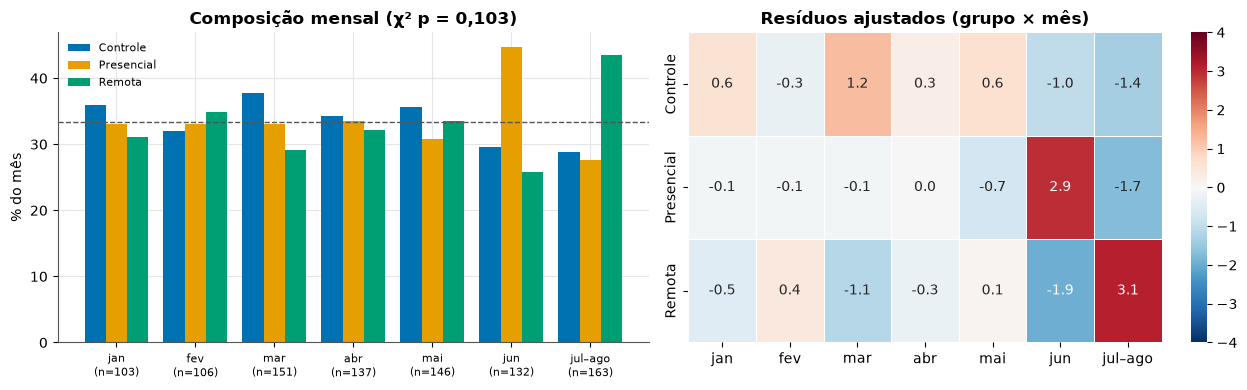

In [51]:
mes = t3['mes_distribuicao'].astype(str).replace({'jul': 'jul–ago', 'ago': 'jul–ago'})
ordem_mes = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul–ago']
t3['mes7'] = pd.Categorical(mes, categories=ordem_mes, ordered=True)
tab_mes = pd.crosstab(t3['mes7'], t3['grupo'])
c2_mes, p_mes, gl_mes, e_mes = stats.chi2_contingency(tab_mes, correction=False)
v_mes, vm_lo, vm_hi = tst_cramer_ic(t3['mes7'], t3['grupo'])
display(tab_mes.assign(Total=tab_mes.sum(axis=1)))
print(f'Esperada mín. = {fmt_br(e_mes.min(), 1)} | χ²({gl_mes}) = {fmt_br(c2_mes, 2)}, p {tst_eq(p_mes)} | V = {tst_ic_txt(v_mes, vm_lo, vm_hi, 3)}')
res_mes = tst_residuos(tab_mes)
print('Resíduos ajustados:'); display(res_mes.round(2))
tst_registra('3.5', 'H11 grupo × mês', 'χ² grupo × mês de distribuição', 'independência', f'χ²({gl_mes}) = {fmt_br(c2_mes, 2)}', p_mes,
             f'V = {tst_ic_txt(v_mes, vm_lo, vm_hi, 3)}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
perc = 100 * tab_mes.div(tab_mes.sum(axis=1), axis=0)
x = np.arange(len(perc)); w = 0.27
for i, g in enumerate(ORDEM_GRUPO):
    ax[0].bar(x + (i - 1) * w, perc[g], w, color=CORES_GRUPO[g], label=g)
ax[0].axhline(100 / 3, color=TINTA_2, ls='--', lw=1)
ax[0].set_xticks(x, [f'{m}\n(n={int(tab_mes.loc[m].sum())})' for m in perc.index], fontsize=8)
ax[0].set_ylabel('% do mês'); ax[0].set_title(f'Composição mensal (χ² p {tst_eq(p_mes)})'); ax[0].legend(fontsize=8)
sns.heatmap(res_mes.T, annot=True, fmt='.1f', cmap='RdBu_r', center=0, vmin=-4, vmax=4, ax=ax[1], linewidths=0.5)
ax[1].set_title('Resíduos ajustados (grupo × mês)'); ax[1].set_xlabel(''); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

**Leitura. O sorteio parece aleatório, a vara ficou mais lenta ao longo do ano e a correlação "ingênua" entre a ordem de chegada e o tempo é dominada pela censura.**

- **Aleatoriedade do sorteio (H9).**
  - **Número de corridas:** foram observadas R = 626 corridas, contra 626,3 esperadas sob H₀ (DP de permutação de 14,3; p = 1,000). Não há nem agrupamento nem rodízio regular.
  - **Maior corrida:** tem 8 processos seguidos, comprimento comum sob o acaso (P ≥ 8 = 0,239).
  - **Por grupo:** z = 0,43, 0,75 e −1,24, todos não significativos.

  A sequência é **compatível com sorteio aleatório**, o que reforça a classificação como ECA (questão 2.2). O teste não prova o mecanismo: uma lista pseudoaleatória bem feita e um sorteio físico dariam o mesmo resultado, e a ocultação da alocação continua sem documentação.
- **Composição mensal (H11).** χ²(12) = 18,45, p = 0,103, V = 0,10. No conjunto, o desequilíbrio não excede o acaso, mas os resíduos mostram dois meses atípicos: **junho**, com excesso de Presencial (+2,95), e **julho-agosto**, com excesso de Remota (+3,10; 71 de 163 processos). Como julho é o mês com menos seguimento e mais ativos, a Remota recebe uma parcela maior de processos com pouco seguimento. Por isso o mês entra como estrato e covariável (seção 3.6 e Partes IV e V).
- **Ordem de chegada × tempo (H10, questão 2.7):**
  - **todos (938), censura ignorada:** ρ = −0,04 (p = 0,211), τ = −0,05 (p = 0,024). Spearman e Kendall discordam quanto à significância, um sinal de que a associação é fraca e frágil;
  - **só sentenciados:** ρ = −0,12 (p = 0,002). Este é o "achado" que uma análise ingênua reportaria: "os processos mais recentes são mais rápidos";
  - **janela comum de 65 dias**, sem censura: ρ = **+0,14** (p < 0,001; τ = +0,11). **O sinal se inverte**: os processos que chegaram depois demoram **mais**. A proporção sentenciada até o 65º dia cai de 46% (janeiro) para 21% (julho), o que é compatível com acúmulo de acervo ao longo do experimento (cada processo dos braços com AC exige uma pauta de audiência) ou com sazonalidade de pauta.
- **A simulação explica a inversão.** Em 500 réplicas, os tempos foram gerados **sem nenhuma relação** com a ordem e censurados com o acompanhamento real de cada processo. Sob essa H₀:
  - **só encerrados:** ρ médio = −0,28 (faixa de 95%: −0,34 a −0,21);
  - **todos, com a censura ignorada:** ρ médio = −0,19;
  - **janela de 65 dias:** ρ médio = 0,00.

  A censura sozinha "fabrica" uma correlação negativa forte. Os ρ observados (−0,12 e −0,04) ficam **acima** dessa faixa, ou seja, a associação verdadeira é positiva e parcialmente mascarada pela censura. A magnitude do artefato depende da distribuição simulada (Weibull de forma 1,6), mas o sinal não depende.
- **Resposta à questão 2.7.** Sim, é possível investigar a correlação entre a ordem de chegada e o tempo, com Spearman ou Kendall (a ordem é ordinal; nunca Pearson), **desde que** a censura seja tratada: janela comum de seguimento, como aqui, ou a ordem/data como covariável num modelo de Cox (Parte IV). Sem esse cuidado, a correlação mede o calendário de distribuição e não o ritmo da vara.

---

## 3.6 Os testes do notebook do professor × as decisões deste notebook (questão 2.11)

### 3.6.1 Reprodução dos testes problemáticos

Para que a comparação seja concreta, os testes do notebook do professor que dependem da base são reproduzidos na base primária (938). Os números diferem um pouco dos originais (944 linhas, com duplicatas, linha vazia e "Decisão" como sentença), mas a conclusão de cada um é a mesma. **Esses testes não entram no registro da seção 3.7**: são exibidos para crítica, não como achados.

,Teste reproduzido,p
0,χ² grupo × status (E19),"< 0,001"
1,χ² grupo × acordo na AC com Controle (E20),"0,013"
2,χ² sentença (com Decisão) × grupo (E21),"< 0,001"
3,Mann-Whitney Encerrado × Ativo (E18),"< 0,001"
4,"z de proporção p0 = 0,5 (E23)","< 0,001"
5,"Mann-Whitney com × sem acordo na AC, todos (E24)","0,448"
6,"Kruskal-Wallis todos, censura ignorada (E17)","0,559"


Esperadas da coluna "acordo na AC" no χ² com o Controle (E20): [5.7 5.7 5.6]
Encerrados: 732/938 = 78,0% (z = 17,2)


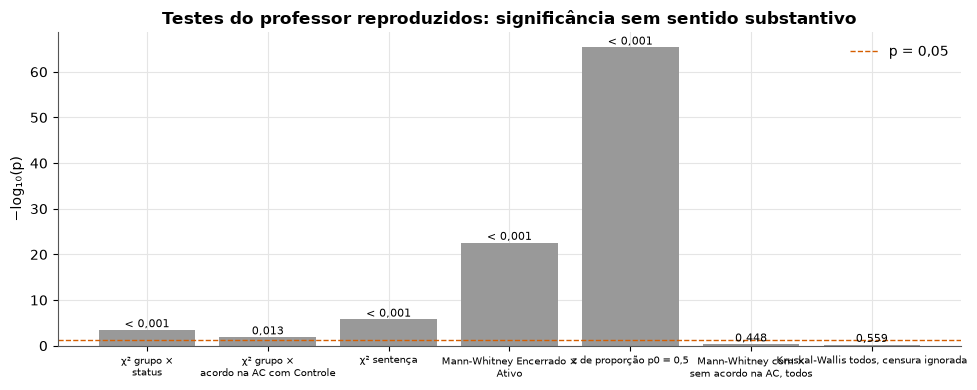

In [52]:
rep = {}
tab = pd.crosstab(t3['grupo'], t3['encerrado'].astype(bool)); rep['χ² grupo × status (E19)'] = stats.chi2_contingency(tab, correction=False)[1]
tab = pd.crosstab(t3['grupo'], t3['acordo_ac'].fillna(False).astype(bool)); rep['χ² grupo × acordo na AC com Controle (E20)'] = stats.chi2_contingency(tab, correction=False)[1]
e20 = stats.chi2_contingency(tab, correction=False)[3]
enc_all = t3[t3['encerrado'].astype(bool)]
tab = pd.crosstab(enc_all['tipo_desfecho'].cat.remove_unused_categories(), enc_all['grupo']); rep['χ² sentença (com Decisão) × grupo (E21)'] = stats.chi2_contingency(tab, correction=False)[1]
ativos = t3.loc[t3['tipo_desfecho'] == 'Ativo', 'tempo_f']; encs = enc_all['tempo_f']
rep['Mann-Whitney Encerrado × Ativo (E18)'] = stats.mannwhitneyu(encs, ativos)[1]
x_enc = int(t3['encerrado'].sum())
z = (x_enc / len(t3) - 0.5) / np.sqrt(0.25 / len(t3)); rep['z de proporção p0 = 0,5 (E23)'] = 2 * stats.norm.sf(abs(z))
com_all = t3.loc[t3['acordo_ac'] == True, 'tempo_f']; sem_all = t3.loc[t3['acordo_ac'] != True, 'tempo_f']
rep['Mann-Whitney com × sem acordo na AC, todos (E24)'] = stats.mannwhitneyu(com_all, sem_all)[1]
rep['Kruskal-Wallis todos, censura ignorada (E17)'] = versoes['1. Professor: todos, censura ignorada'][1]
t3_rep = pd.DataFrame({'Teste reproduzido': rep.keys(), 'p': rep.values()})
tst_tabela_p(t3_rep)
print('Esperadas da coluna "acordo na AC" no χ² com o Controle (E20):', np.round(e20[:, 1], 1))
print(f'Encerrados: {x_enc}/{len(t3)} = {pct_br(x_enc / len(t3))} (z = {fmt_br(z, 1)})')

fig, ax = plt.subplots(figsize=(10, 4))
cores_rep = ['#999999'] * len(t3_rep)
barras = ax.bar(range(len(t3_rep)), -np.log10(np.clip(t3_rep['p'], 1e-300, 1)), color=cores_rep)
ax.bar_label(barras, labels=[p_br(p) for p in t3_rep['p']], fontsize=8)
ax.axhline(-np.log10(0.05), color='#D55E00', ls='--', lw=1, label='p = 0,05')
ax.set_xticks(range(len(t3_rep)), [t.split(' (')[0].replace(' × ', ' ×\n') for t in t3_rep['Teste reproduzido']], fontsize=7, rotation=0)
ax.set_ylabel('−log₁₀(p)'); ax.set_title('Testes do professor reproduzidos: significância sem sentido substantivo'); ax.legend()
plt.tight_layout(); plt.show()

### 3.6.2 Quadro de decisão

| Cél. | Teste do professor | Resultado original | Problema (código) | Decisão aqui | Onde |
|---|---|---|---|---|---|
| 28 | Kruskal-Wallis da duração × grupo, todos | H = 1,48; p = 0,478 | censurados como completos; "Decisão" como sentença; H₀ como "medianas" (E14, E17) | **Substituído** por log-rank/Cox; KW só condicional aos sentenciados ou em min(T, 65) | 3.4; Parte IV |
| 28 | Mann-Whitney post-hoc sem correção | (não executado: p > 0,05) | sem ajuste de multiplicidade (E17, E27) | **Substituído** por Dunn com Holm; MW com delta de Cliff | 3.4 |
| 29 | Mann-Whitney Encerrado × Ativo | p = 3,2 × 10⁻²⁴ | tautológico (E18) | **Removido** | 3.1 |
| 32 | χ² grupo × status | p = 0,00015 | status depende do mês de entrada (E19) | **Substituído** pela situação no 65º dia e por KM | 3.2.5; Parte IV |
| 33 | χ² grupo × acordo na AC | p = 0,0074 | zero estrutural no Controle; esperadas ~5 (E20) | **Substituído** por Fisher Presencial × Remota entre AC realizadas | 3.3.1 |
| 34 | χ² tipo de sentença × grupo | p = 2,0 × 10⁻⁶ | inclui Decisão; sem resíduos nem V; % no sentido errado (E21) | **Adequado na ideia, refeito**: sem Decisão, resíduos, V com IC, pares com Holm | 3.2 |
| 37–38 | Matriz de Spearman das 4 durações; OLS das dispersões | r = 1; R² = 1 | mesma variável (E6, E16) | **Removido**; Spearman/Kendall ordem × tempo com controle da censura | 3.5.2 |
| 40 | Shapiro-Wilk e D'Agostino (subamostra de 500) | p = 2,6 × 10⁻⁸ / 0,213 | subamostra arbitrária, variável censurada, decisão *a posteriori* (E22) | **Refeito** por grupo na Parte II; aqui, nos resíduos da ANOVA didática | Parte II; 3.4.4 |
| 42 | z de proporção (p₀ = 0,5) | z = 17,1 | hipótese sem sentido (E23) | **Removido** | 3.1 |
| 42 | Mann-Whitney com × sem acordo na AC | p = 0,456 | "sem acordo" inclui o Controle e os ativos (E24) | **Refeito** entre AC realizadas e sentenciadas (condicional); correto: riscos competitivos | 3.4.6; Parte IV |
| 44 | Ajuste MLE de distribuições | Weibull melhor AIC | censura ignorada; `loc` livre; zeros descartados (E25) | **Substituído** por ajuste com censura | Partes II e IV |
| 46 | OLS duração ~ grupo; Logit evento ~ grupo | p = 0,588; p < 0,001 | censura; evento depende do seguimento (E26) | **Substituído** por Cox/AFT e logit em horizonte fixo | Partes IV e V |
| 48 | KM + log-rank | não executou | import errado (E1) | **Feito** | Parte IV |
| — | correção de multiplicidade, tamanhos de efeito | ausentes | E27 | **Holm/BH**, V, OR, ε², delta de Cliff, ρ, τ | 3.7 |

### 3.6.3 Outros testes que poderiam ser aplicados (Siegel e Castellan, 2006; Barbetta et al., 2020; Becker, 2015)

| Teste | Para quê, neste caso | Situação |
|---|---|---|
| **Cochran-Mantel-Haenszel** (+ Breslow-Day) | acordo × grupo ajustado pelo mês (estratos) | **implementado abaixo** |
| **Permutação / Monte Carlo** | tabelas esparsas (técnica, redistribuição), sequência do sorteio | implementado (3.2.4, 3.3, 3.5.1) |
| **Exato de Fisher / Fisher-Freeman-Halton** | acordo na AC (17 eventos) | implementado (3.3) |
| **Jonckheere-Terpstra** | tendência ordenada do tempo (condicional) ao longo dos **meses** | possível; não se aplica ao grupo (nominal) |
| **Cochran-Armitage** | tendência da proporção de acordo/sem mérito ao longo dos meses (curva de aprendizado do rito) | possível, mas exige horizonte fixo por causa do seguimento decrescente |
| **Kolmogorov-Smirnov para 2 amostras** | diferença de forma (não só de posição) das distribuições do tempo | possível; mesmo problema de censura |
| **Brunner-Munzel** | alternativa ao Mann-Whitney sem supor formas iguais | possível |
| **Log-rank, Wilcoxon-Gehan, Peto, Fleming-Harrington; Gray** | tempos censurados; riscos competitivos | Parte IV |
| **McNemar, Wilcoxon pareado, Friedman, Cochran Q** | amostras dependentes | **não se aplicam** (grupos independentes, questão 2.3) |

### 3.6.4 Cochran-Mantel-Haenszel: acordo × grupo estratificado por mês (H12)

O mês de distribuição está associado à composição dos grupos (3.5.3) e ao acompanhamento. O CMH combina as tabelas 2 × 2 de cada mês num **OR comum** de Mantel-Haenszel e testa **H₀: OR comum = 1**; o teste de **Breslow-Day** (Tarone) verifica se o OR é homogêneo entre os meses. O desfecho é o acordo homologado entre os processos com o registro de acordo (733); cada braço com AC é comparado ao Controle. O gráfico mostra o OR de cada mês (com correção de Haldane, +0,5, só para desenhar meses com zero) e o OR combinado.

,Comparação,OR bruto,p bruto (Fisher),OR MH,OR MH IC,CMH χ²,p,Breslow-Day p,p Holm
0,Presencial × Controle,1.362,"0,355",1.339,"0,73 a 2,47",0.871,"0,351","0,405","0,351"
1,Remota × Controle,2.147,"0,010",2.173,"1,22 a 3,86",7.232,"0,007","0,385","0,014"


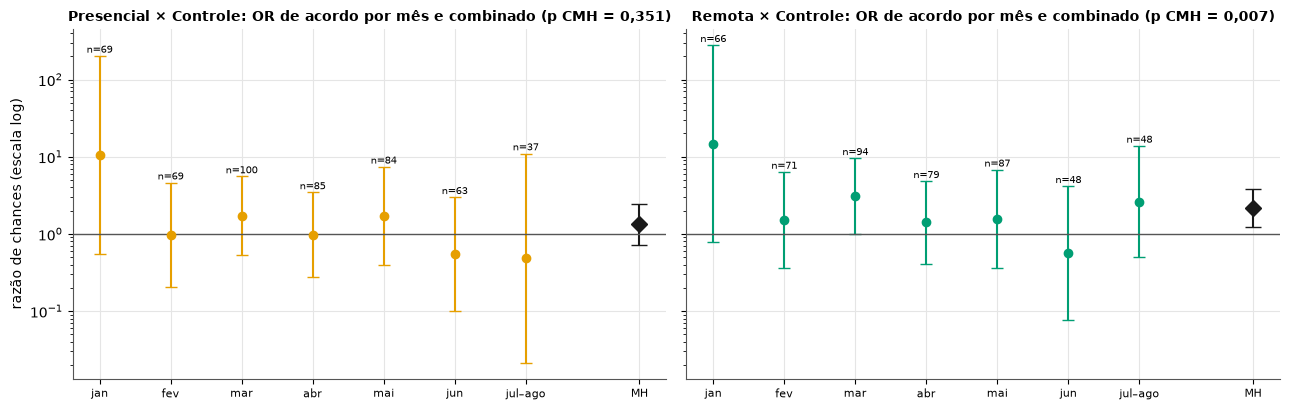

In [53]:
base_cmh = t3[t3['acordo'].notna()].copy()
linhas, forest = [], {}
for g in ['Presencial', 'Remota']:
    sub = base_cmh[base_cmh['grupo'].isin([g, 'Controle'])]
    tabelas, ors = [], []
    for m in ordem_mes:
        sm_ = sub[sub['mes7'] == m]
        t = np.array([[((sm_['grupo'] == g) & sm_['acordo'].astype(bool)).sum(), ((sm_['grupo'] == g) & ~sm_['acordo'].astype(bool)).sum()],
                      [((sm_['grupo'] == 'Controle') & sm_['acordo'].astype(bool)).sum(), ((sm_['grupo'] == 'Controle') & ~sm_['acordo'].astype(bool)).sum()]])
        tabelas.append(t)
        a, b, c, d = t.ravel() + 0.5
        lor, se = np.log(a * d / (b * c)), np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
        ors.append((m, np.exp(lor), np.exp(lor - 1.96 * se), np.exp(lor + 1.96 * se), int(t.sum())))
    st = StratifiedTable(tabelas)
    teste = st.test_null_odds(correction=False)
    bd = st.test_equal_odds(adjust=True)
    lo, hi = st.oddsratio_pooled_confint()
    bruto = np.sum(tabelas, axis=0)
    p_bruto, or_bruto, _, _, _ = tst_fisher(bruto)
    linhas.append({'Comparação': f'{g} × Controle', 'OR bruto': or_bruto, 'p bruto (Fisher)': p_bruto,
                   'OR MH': st.oddsratio_pooled, 'OR MH IC': f'{fmt_br(lo, 2)} a {fmt_br(hi, 2)}',
                   'CMH χ²': teste.statistic, 'p': teste.pvalue, 'Breslow-Day p': bd.pvalue})
    forest[g] = (ors, st.oddsratio_pooled, lo, hi)
t3_cmh = pd.DataFrame(linhas); t3_cmh['p Holm'] = tst_holm(t3_cmh['p'])
tst_tabela_p(t3_cmh, casas=3, colunas_p=('p', 'p Holm', 'p bruto (Fisher)', 'Breslow-Day p'))
for _, r in t3_cmh.iterrows():
    tst_registra('3.6', 'H12 CMH', f'CMH acordo × grupo por mês: {r["Comparação"]}', 'OR comum = 1', f'χ²(1) = {fmt_br(r["CMH χ²"], 2)}',
                 r['p'], f'OR MH = {fmt_br(r["OR MH"], 2)} [{r["OR MH IC"].replace(" a ", "; ")}]')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for k, g in enumerate(['Presencial', 'Remota']):
    ors, orp, lo, hi = forest[g]
    for i, (m, o, l, h, nn) in enumerate(ors):
        ax[k].errorbar(i, o, yerr=[[o - l], [h - o]], fmt='o', color=CORES_GRUPO[g], capsize=4)
        ax[k].text(i, h * 1.1, f'n={nn}', ha='center', fontsize=7)
    ax[k].errorbar(len(ors) + 0.6, orp, yerr=[[orp - lo], [hi - orp]], fmt='D', color=TINTA, capsize=6, ms=8)
    ax[k].axhline(1, color=TINTA_2, lw=1)
    ax[k].set_yscale('log'); ax[k].set_xticks(list(range(len(ors))) + [len(ors) + 0.6], [o[0] for o in ors] + ['MH'], fontsize=8)
    ax[k].set_title(f'{g} × Controle: OR de acordo por mês e combinado (p CMH {tst_eq(t3_cmh.loc[k, "p"])})', fontsize=10)
ax[0].set_ylabel('razão de chances (escala log)')
plt.tight_layout(); plt.show()

**Leitura (questão 2.11).**

- **Os testes reproduzidos dão valores-p "fortes" justamente onde a hipótese é vazia:**
  - **Encerrado × Ativo:** p < 0,001, e é tautológico;
  - **z com p₀ = 0,5:** z = 17,2, e 78,0% de encerrados não é comparável a nada;
  - **grupo × status:** p < 0,001, mas o status depende do mês de entrada;
  - **grupo × acordo na AC com o Controle:** p = 0,013. O "efeito" é o zero estrutural do Controle, e as esperadas da coluna "acordo" são 5,6 a 5,7, no limite de Cochran.
- **Testes sobre perguntas reais têm valores-p fracos e precisam de método adequado.** É o caso do KW (p = 0,559) e do Mann-Whitney com × sem acordo (p = 0,448). A significância estatística do notebook do professor está, portanto, **invertida em relação à relevância substantiva**.
- **Dos 14 testes do notebook:**
  - **um é adequado na ideia:** χ² tipo de sentença × grupo, refeito aqui sem a "Decisão", com resíduos e V;
  - **quatro devem ser removidos:** Encerrado × Ativo, z com p₀ = 0,5, matriz de correlação e dispersões tautológicas;
  - **os demais devem ser substituídos** por métodos que respeitem a censura (Parte IV), o zero estrutural (Fisher entre os braços com AC) ou a multiplicidade (Dunn/Holm).
- **CMH estratificado por mês (H12).** O acordo foi comparado entre os processos com o registro de acordo (733).
  - **Remota × Controle:** OR bruto = 2,15 e OR de Mantel-Haenszel = **2,17 (IC 95% 1,22 a 3,86)**, χ²(1) = 7,23, p = 0,007 (p Holm = 0,014 na família). Breslow-Day p = 0,385: o OR é homogêneo entre os meses.
  - **Presencial × Controle:** OR MH = 1,34 (0,73 a 2,47), p = 0,351.
  - **Leitura.** O ajuste pelo mês **não altera** a razão de chances. A concentração de Remota em julho não explica o seu excedente de acordos, ou seja, o mês não confunde essa associação. A ressalva continua: a base é condicional a ter o acordo registrado (encerrados), e o desfecho correto é a incidência acumulada do acordo (Parte IV).
- **Outros testes aplicáveis.** CMH, permutação e exatos foram implementados aqui. Jonckheere-Terpstra e Cochran-Armitage servem para hipóteses de **tendência no mês** (por exemplo, a queda da proporção sentenciada até 65 dias, de 46% para 21%), não para o grupo, que é nominal. Brunner-Munzel e Kolmogorov-Smirnov ampliariam a comparação de distribuições, mas herdam o problema da censura. Testes pareados não se aplicam (questão 2.3).

---

## 3.7 Multiplicidade: todos os valores-p da Parte III

Cada família já foi corrigida por Holm nas seções anteriores. Aqui, **todos** os testes registrados são reunidos e corrigidos de uma vez:

- **Holm global** controla a probabilidade de ao menos um falso positivo entre todos os testes da parte (FWER), o critério mais exigente;
- **Benjamini-Hochberg** controla a proporção esperada de falsos positivos entre os testes declarados significativos (FDR), o critério usual em análises exploratórias com muitos testes.

Uma conclusão que sobrevive ao Holm global não depende da quantidade de testes feitos. Leitura do gráfico: cada barra é um teste; a altura é −log₁₀ do p ajustado (barras acima da linha tracejada são significativas a 5% após a correção).

55 testes registrados | significativos: brutos 19, Holm global 13, BH 17


,Seção,Família,Teste,H0,Estatística,p,Efeito (IC 95%),p Holm global,p BH (FDR),"Holm < 0,05","BH < 0,05"
0,3.2,H1 tipo × grupo,χ² tipo de sentença × grupo (sentenciados),independência,"χ²(4) = 34,34","< 0,001","V = 0,156 [0,114; 0,212]","< 0,001","< 0,001",sim,sim
1,3.2,H1 pares,χ² 2×3 Presencial × Controle,mesma distribuição de tipos,"χ²(2) = 20,02","< 0,001","V = 0,202","0,002","< 0,001",sim,sim
2,3.2,H1 pares,χ² 2×3 Remota × Controle,mesma distribuição de tipos,"χ²(2) = 26,83","< 0,001","V = 0,237","< 0,001","< 0,001",sim,sim
3,3.2,H1 pares,χ² 2×3 Presencial × Remota,mesma distribuição de tipos,"χ²(2) = 2,76","0,252","V = 0,079","1,000","0,420",,
4,3.2,H2 tipos binários,χ² 3×2 Sem mérito × grupo,proporção igual nos 3 grupos,"χ²(2) = 18,31","< 0,001","V = 0,161","0,005","< 0,001",sim,sim
5,3.2,H2 tipos binários,χ² 3×2 Mérito × grupo,proporção igual nos 3 grupos,"χ²(2) = 31,61","< 0,001","V = 0,211","< 0,001","< 0,001",sim,sim
6,3.2,H2 tipos binários,χ² 3×2 Homologação × grupo,proporção igual nos 3 grupos,"χ²(2) = 7,94","0,019","V = 0,106","0,697","0,055",,
7,3.2,H2 pares (Fisher),Fisher Sem mérito: Presencial × Controle,OR = 1,"OR = 2,09","< 0,001","dif. = 17,2 [8,6; 25,5] p.p.","0,004","< 0,001",sim,sim
8,3.2,H2 pares (Fisher),Fisher Sem mérito: Remota × Controle,OR = 1,"OR = 1,92","< 0,001","dif. = 15,2 [6,5; 23,7] p.p.","0,036","0,004",sim,sim
9,3.2,H2 pares (Fisher),Fisher Sem mérito: Presencial × Remota,OR = 1,"OR = 1,08","0,704","dif. = 2,0 [-7,2; 11,2] p.p.","1,000","0,824",,


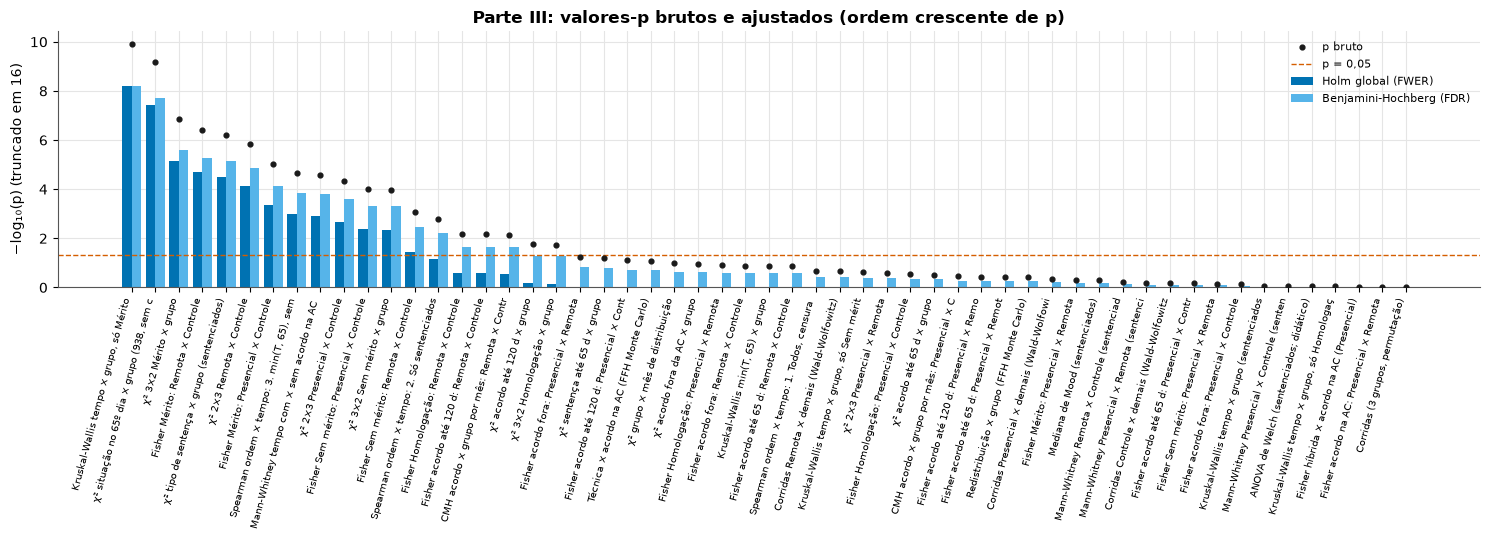

In [54]:
t3_reg = pd.DataFrame(TST_REGISTRO)
t3_reg['p Holm global'] = multipletests(t3_reg['p'], method='holm')[1]
t3_reg['p BH (FDR)'] = multipletests(t3_reg['p'], method='fdr_bh')[1]
t3_reg['Holm < 0,05'] = np.where(t3_reg['p Holm global'] < 0.05, 'sim', '')
t3_reg['BH < 0,05'] = np.where(t3_reg['p BH (FDR)'] < 0.05, 'sim', '')
print(f'{len(t3_reg)} testes registrados | significativos: brutos {int((t3_reg["p"] < 0.05).sum())}, '
      f'Holm global {int((t3_reg["p Holm global"] < 0.05).sum())}, BH {int((t3_reg["p BH (FDR)"] < 0.05).sum())}')
with pd.option_context('display.max_colwidth', 80, 'display.max_rows', 100):
    tst_tabela_p(t3_reg, colunas_p=('p', 'p Holm global', 'p BH (FDR)'))
t3_reg.to_csv(PROC / 'ed2_parte3_testes.csv', sep=';', decimal=',', index=False, encoding='utf-8-sig')

ordem_plot = t3_reg.sort_values('p').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(15, 5.5))
xx = np.arange(len(ordem_plot)); w = 0.4
lp = lambda s: -np.log10(np.clip(s, 1e-16, 1))
ax.bar(xx - w / 2, lp(ordem_plot['p Holm global']), w, color='#0072B2', label='Holm global (FWER)')
ax.bar(xx + w / 2, lp(ordem_plot['p BH (FDR)']), w, color='#56B4E9', label='Benjamini-Hochberg (FDR)')
ax.scatter(xx, lp(ordem_plot['p']), color=TINTA, s=12, zorder=3, label='p bruto')
ax.axhline(-np.log10(0.05), color='#D55E00', ls='--', lw=1, label='p = 0,05')
ax.set_xticks(xx, [t[:42] for t in ordem_plot['Teste']], rotation=75, ha='right', fontsize=7)
ax.set_ylabel('−log₁₀(p) (truncado em 16)'); ax.set_title('Parte III: valores-p brutos e ajustados (ordem crescente de p)')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Leitura. O que sobrevive a qualquer critério.**

- **Volume de testes.** A parte registrou **55 testes**. São significativos a 5%: **19** sem correção, **17** com Benjamini-Hochberg (FDR) e **13** com Holm global (FWER).
- **Sobrevivem ao Holm global, que é o critério mais exigente:**
  - **H1/H2 (tipo de desfecho).** Associação tipo × grupo (sentenciados e janela de 65 dias); pares Presencial × Controle e Remota × Controle; mais sem mérito e menos mérito nos dois braços com AC. **É o achado mais robusto da Parte III.**
  - **H8 por tipo.** Julgamentos de mérito mais lentos nos braços com AC (KW no estrato mérito).
  - **H10.** Correlação positiva entre ordem de chegada e tempo na janela sem censura (ρ = +0,14): a vara ficou mais lenta ao longo do ano.
  - **E24 refeito.** O acordo na AC encerra o processo mais cedo, o que é em boa parte definicional.
- **Sobrevivem só ao BH (FDR), como evidência sugestiva a confirmar:**
  - mais **acordo** na Remota que no Controle: homologação entre sentenciados, acordo até 120 dias e CMH por mês, com OR entre 2,2 e 2,7 de forma consistente;
  - a correlação negativa ordem × tempo entre os sentenciados, que é o artefato da censura (seção 3.5.2) e, por isso, não deve ser lida como achado.
- **Não rejeitados, com IC que informa o tamanho máximo plausível:**
  - acordo na AC presencial × remota: diferença de +0,5 p.p. (IC −4,4 a +5,3);
  - técnica e híbrida: sem poder;
  - redistribuição;
  - aleatoriedade do sorteio, compatível com H₀;
  - tempo agregado entre os sentenciados: delta de Cliff ≈ 0, um paradoxo de composição.
- **Leitura para a questão 2.11.** Sem correção de multiplicidade e sem tamanho de efeito (E27), o notebook do professor não tinha como separar esses três níveis de evidência. Com 55 testes a 5%, cerca de três "significâncias" seriam esperadas só pelo acaso. Por isso, o achado de acordo da Remota, isolado, não autorizaria uma recomendação de política judiciária. Já a troca de mérito por extinção sem mérito autoriza.